# Exploratory Data Analysis: ACDC Membership Dataset

## Purpose and scope
This notebook explores the ACDC coworking membership dataset to understand its data quality, member behavior, and potential signals for a later customer-segmentation model. It follows a deliberate sequence: inspect the raw data, assess reliability, study distributions and relationships, create behavior-focused features, and identify candidate inputs for future clustering.

The notebook is descriptive: it does not fit a clustering model or claim that customer groups have already been discovered. Interpretations are framed as hypotheses to test in the modeling stage. The expected cluster count is a starting business hypothesis, not a result.


## 0. Setup and conventions

The notebook uses Python with pandas for tabular data, NumPy for numeric operations, and Matplotlib/Seaborn for plots. The data-loading cell searches the expected project-relative locations and raises a clear error if the CSV is not found. Derived and cleaned fields are added to analysis dataframes; raw category labels and original LTV text are retained where needed for auditing. Run the notebook from top to bottom in a fresh kernel to reproduce the tables and figures.


In [1]:
from pathlib import Path
import re
import unicodedata

import matplotlib.pyplot as plt
from matplotlib.colors import ListedColormap
import numpy as np
import pandas as pd
import seaborn as sns

PALETTE = sns.color_palette("viridis", 8)
sns.set_palette(PALETTE)
PALETTE_CMAP = ListedColormap(PALETTE)

%config InlineBackend.figure_format = "retina"

print("Setup complete: libraries imported.")


Setup complete: libraries imported.


## 1. Load and preview the data

Read the semicolon-separated source file and inspect a small sample. This first check confirms that columns were separated correctly and gives an initial view of how values, missing entries, category labels, and dates are represented. The source data is not cleaned at this stage.


In [2]:
data_candidates = [Path("../data/acdc_dataset.csv"), Path("data/acdc_dataset.csv")]
DATA_PATH = next((path for path in data_candidates if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError("Could not find acdc_dataset.csv in ../data or data.")

acdc = pd.read_csv(DATA_PATH, sep=";")
pd.set_option("display.max_columns", None)
display(acdc.head(10))


,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
0,CW000001,38.0,Female,Information Technology,Portugal,False,0,flex,3,2021-08-01,2023-03-06,2023-03-23,-17,220,2.65,26.09,22,0.0,0.0,18.0,False,False,True,0,False,True,True,False,False,2,4477.97
1,CW000002,38.0,Male,Information Technology,Portugal,True,2,HOT_DESK,2,2023-11-24,1970-01-01,2023-11-24,37,2,0.32,10.68,1,0.0,0.0,0.0,False,False,False,0,True,False,False,False,False,0,165.86
2,CW000003,43.0,Male,Education,DE,True,1,flex,3,2021-12-03,1970-01-01,2023-07-22,163,19,0.17,26.09,2,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,1,4486.17
3,CW000004,38.0,F,Legal,portugal,False,0,flex,3,2022-01-02,2022-02-15,2022-01-02,44,8,1.23,18.74,9,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,258.63
4,CW000005,45.0,Female,Information Technology,United Kingdom,False,0,hot_desk,2,2023-10-24,1970-01-01,2023-12-17,15,4,0.38,17.39,3,0.0,0.0,0.0,False,False,False,0,False,False,True,False,False,0,335.74
5,CW000006,39.0,Male,Health,Portugal,False,0,flex,3,2021-05-31,2021-08-01,2021-07-09,23,3,0.36,26.09,3,0.0,0.0,0.0,False,False,False,1,True,False,False,False,False,0,413.17
6,CW000007,23.0,Female,Unknown,Portugal,True,2,hot_desk,2,2022-01-17,2022-03-19,2022-01-31,47,5,0.62,17.39,5,0.0,0.0,1.0,False,False,True,0,False,False,False,False,False,0,257.95
7,CW000008,33.0,Male,Information Technology,Portugal,True,3,flex,3,2021-03-28,2022-06-30,2022-06-14,16,155,2.36,26.09,25,129.0,0.0,0.0,True,False,False,0,False,False,False,True,False,0,4636.8
8,CW000009,30.0,Male,Other,Portugal,False,0,flex,3,2023-08-12,2023-09-21,2023-08-12,40,6,1.10,17.13,6,0.0,1.0,0.0,False,True,False,0,False,False,False,False,False,0,281.37
9,CW000010,44.0,Male,Consulting,Portugal,False,0,dedicated_desk,5,2022-06-06,1970-01-01,2023-12-30,2,331,4.04,43.48,36,42.1,0.0,37.0,True,False,True,1,True,True,False,True,False,1,8741.88


## 2. Dataset structure

Check the number of records and fields, then inspect the column names and inferred data types. This establishes the scope of the dataset and helps identify fields that need special handling.


In [3]:
acdc.shape

(15465, 31)

In [4]:
list(acdc.columns)

['member_id',
 'age',
 'gender',
 'industry',
 'country',
 'is_team_account',
 'n_colleagues_on_account',
 'plan_tier',
 'plan_days_per_week',
 'membership_start',
 'membership_end',
 'last_badge_swipe',
 'days_since_last_visit',
 'total_visits',
 'avg_weekly_visits',
 'entitled_visits_last_period',
 'actual_visits_last_period',
 'meeting_room_hours',
 'event_space_hours',
 'guest_passes_issued',
 'uses_meeting_rooms',
 'uses_event_space',
 'uses_guest_passes',
 'uses_print',
 'uses_mail_handling',
 'uses_phone_booths',
 'uses_day_passes',
 'uses_storage',
 'uses_bike_locker',
 'n_renewals',
 'lifetime_value']

In [5]:
acdc.dtypes

member_id                       object
age                            float64
gender                          object
industry                        object
country                         object
is_team_account                   bool
n_colleagues_on_account          int64
plan_tier                       object
plan_days_per_week               int64
membership_start                object
membership_end                  object
last_badge_swipe                object
days_since_last_visit            int64
total_visits                     int64
avg_weekly_visits              float64
entitled_visits_last_period    float64
actual_visits_last_period        int64
meeting_room_hours             float64
event_space_hours              float64
guest_passes_issued            float64
uses_meeting_rooms                bool
uses_event_space                  bool
uses_guest_passes                 bool
uses_print                       int64
uses_mail_handling                bool
uses_phone_booths        

**Initial read:** The dataset contains 15,465 records and 31 fields. The column list and dtypes show that membership dates are initially text and lifetime value is not yet a numeric field, motivating the normalization step below.

## 3. Missing values

Calculate the percentage of missing values for each raw source field and sort the results from highest to lowest. Missingness can reduce the usable sample for a feature or introduce bias if it is concentrated in particular member groups. The table is calculated before adding derived columns, so each source field appears once.


In [6]:
column_percentage = acdc.isna().mean() * 100
column_percentage = column_percentage[column_percentage > 0].sort_values(ascending=False)
column_percentage

meeting_room_hours     8.393146
guest_passes_issued    8.218558
lifetime_value         6.724863
age                    3.608147
gender                 3.427093
country                2.780472
plan_tier              0.678952
dtype: float64

**What this tells us:** Missingness is concentrated in meeting-room hours (about 8.4%) and guest-pass counts (about 8.2%); lifetime value is missing for about 6.7% of records. Missing values should not be assumed to mean zero unless the source definition confirms that interpretation.

### Exact duplicates and repeated member IDs

Count exact duplicate rows and repeated member IDs separately. A repeated ID may indicate a duplicate row or conflicting records; inspect examples before deciding how to handle them. This notebook does not remove rows from the original `acdc` dataframe at this stage.


In [7]:
print("Duplicated rows:", acdc.duplicated().sum())
print("Duplicated member IDs:", acdc["member_id"].duplicated().sum())

Duplicated rows: 15
Duplicated member IDs: 15


In [8]:
dup_ids = acdc.loc[acdc["member_id"].duplicated(keep=False)].sort_values("member_id")
dup_ids.head(30)

,member_id,age,gender,industry,country,is_team_account,n_colleagues_on_account,plan_tier,plan_days_per_week,membership_start,membership_end,last_badge_swipe,days_since_last_visit,total_visits,avg_weekly_visits,entitled_visits_last_period,actual_visits_last_period,meeting_room_hours,event_space_hours,guest_passes_issued,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_print,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,n_renewals,lifetime_value
959,CW000935,22.0,Female,Unknown,Portugal,False,0,FLEX,3,2022-12-18,2023-03-07,2023-01-21,45,18,1.56,26.09,11,1.7,0.0,1.0,True,False,True,0,False,False,False,False,False,0,505.28
15453,CW000935,22.0,Female,Unknown,Portugal,False,0,FLEX,3,2022-12-18,2023-03-07,2023-01-21,45,18,1.56,26.09,11,1.7,0.0,1.0,True,False,True,0,False,False,False,False,False,0,505.28
15454,CW001390,44.0,Male,UNKNOWN,Portugal,False,0,hot_desk,2,28/10/2022,18/12/2022,17/11/2022,31,4,0.61,14.63,5,NaN,0.0,NaN,False,False,True,0,False,False,False,False,False,0,231.86
1428,CW001390,44.0,Male,UNKNOWN,Portugal,False,0,hot_desk,2,28/10/2022,18/12/2022,17/11/2022,31,4,0.61,14.63,5,NaN,0.0,NaN,False,False,True,0,False,False,False,False,False,0,231.86
15462,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,1970-01-01,2023-12-27,5,1,0.21,1.31,0,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,18.14
3985,CW003868,28.0,Female,Design & Creative,Portugal,True,1,hot_desk,2,2023-12-27,1970-01-01,2023-12-27,5,1,0.21,1.31,0,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,0,18.14
15461,CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,2023-10-15,2023-09-26,19,74,0.58,60.87,4,0.0,0.0,0.0,False,False,False,0,True,True,False,True,False,0,20683.24
5441,CW005287,19.0,Female,Information Technology,Germany,False,0,private_office,7,2021-04-29,2023-10-15,2023-09-26,19,74,0.58,60.87,4,0.0,0.0,0.0,False,False,False,0,True,True,False,True,False,0,20683.24
6011,CW005845,35.0,Female,FINANCE,Portugal,True,3,dedicated_desk,5,2021-10-05,1970-01-01,2023-01-26,340,24,0.20,43.48,2,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,4,9403.99
15456,CW005845,35.0,Female,FINANCE,Portugal,True,3,dedicated_desk,5,2021-10-05,1970-01-01,2023-01-26,340,24,0.20,43.48,2,0.0,0.0,0.0,False,False,False,0,False,False,False,False,False,4,9403.99


**Initial read:** The source contains 15 exact duplicate rows and 15 repeated member IDs. The later quality check confirms whether any repeated IDs have genuinely conflicting records; duplicates are removed only from a separate analysis copy.

## 4. Variable distributions

Summarize numerical, categorical, and Boolean fields to understand typical values, spread, skew, and label consistency. Before calculating numeric summaries, standardize dates and create an auditable numeric lifetime-value field. Category counts at this stage intentionally retain the original labels so inconsistent spellings remain visible.


### 4.1 Standardize dates and prepare lifetime value

The three date fields contain both ISO (`YYYY-MM-DD`) and day-first (`DD/MM/YYYY`) strings. Parse each format explicitly and standardize the displayed values to `YYYY-MM-DD`. Keep the `1970-01-01` membership-end sentinel unchanged in the source-facing column; it represents an active membership rather than a real end date.

Some lifetime-value strings include a euro symbol, and a separate LTV analysis suggests that a subset may be stored in cents. To make this concern auditable, retain the original string, parse a numeric value, and compare it with a plan-tier monthly reference multiplied by membership duration. Values more than 20 times the reference, or unusually large values with no usable reference, are flagged and divided by 100 in a separate `lifetime_value_eur` column. This is a heuristic, not a verified correction. The data include badge swipes later than the LTV analysis's assumed `2024-01-01` snapshot, so validate the observation window before relying on tenure-based adjustments.


In [9]:
date_cols = ["membership_start", "membership_end", "last_badge_swipe"]
parsed_dates = pd.DataFrame(index=acdc.index)
date_format_audit = []

for column in date_cols:
    raw = acdc[column].astype("string").str.strip()
    iso_mask = raw.str.fullmatch(r"\d{4}-\d{2}-\d{2}", na=False)
    slash_mask = raw.str.fullmatch(r"\d{1,2}/\d{1,2}/\d{4}", na=False)
    parsed = pd.Series(pd.NaT, index=acdc.index, dtype="datetime64[ns]")
    parsed.loc[iso_mask] = pd.to_datetime(raw.loc[iso_mask], format="%Y-%m-%d", errors="coerce")
    parsed.loc[slash_mask] = pd.to_datetime(raw.loc[slash_mask], format="%d/%m/%Y", errors="coerce")
    parsed_dates[column] = parsed
    date_format_audit.append({
        "column": column,
        "ISO dates": int(iso_mask.sum()),
        "day-first dates": int(slash_mask.sum()),
        "unsupported or missing": int((raw.isna() | ~(iso_mask | slash_mask)).sum()),
        "invalid calendar dates": int((iso_mask | slash_mask).sum() - parsed.notna().sum()),
    })
    acdc[column] = parsed.dt.strftime("%Y-%m-%d")

display(pd.DataFrame(date_format_audit).set_index("column"))
print("Date columns after standardization:")
display(acdc[date_cols].head())

acdc["lifetime_value_raw"] = acdc["lifetime_value"].astype("string")
ltv_numeric = pd.to_numeric(
    acdc["lifetime_value_raw"].str.replace(r"[\u20ac,]", "", regex=True).str.strip(),
    errors="coerce",
)
plan_key = (
    acdc["plan_tier"].astype("string").str.strip().str.lower()
    .str.replace(r"[\s_-]+", "", regex=True)
)
plan_key = plan_key.map({
    "hotdesk": "hot_desk",
    "flex": "flex",
    "fulltime": "full_time",
    "dedicateddesk": "dedicated_desk",
    "privateoffice": "private_office",
})
snapshot_date = pd.Timestamp("2024-01-01")
latest_badge_date = parsed_dates["last_badge_swipe"].max()
print(f"Latest badge-swipe date: {latest_badge_date:%Y-%m-%d}")
if latest_badge_date > snapshot_date:
    print("Data-quality note: badge-swipe activity extends past the LTV notebook snapshot; verify the observation date before relying on tenure-based LTV corrections.")
end_dates = parsed_dates["membership_end"].mask(
    parsed_dates["membership_end"].eq(pd.Timestamp("1970-01-01")), snapshot_date
).fillna(snapshot_date)
tenure_months = ((end_dates - parsed_dates["membership_start"]).dt.days / 30.44)
tenure_months = tenure_months.where(tenure_months >= 0)
ltv_reference = ltv_numeric.mask(ltv_numeric.eq(0))
monthly_reference = (ltv_reference / tenure_months).groupby(plan_key).median()
expected_ltv = plan_key.map(monthly_reference) * tenure_months
ltv_ratio = ltv_reference / expected_ltv
cents_candidate = ((ltv_ratio > 20) | (ltv_ratio.isna() & (ltv_reference > 30000))).fillna(False)

acdc["lifetime_value_eur"] = ltv_numeric.mask(cents_candidate, ltv_numeric / 100)
acdc["lifetime_value_was_cents"] = cents_candidate.astype(bool)
print(f"Lifetime values containing a euro symbol: {acdc['lifetime_value_raw'].str.contains('\u20ac', na=False).sum():,}")
print(f"Likely cents values converted (heuristic): {int(cents_candidate.sum()):,}")
display(acdc.loc[cents_candidate, [
    "member_id", "plan_tier", "lifetime_value_raw", "lifetime_value_eur"
]].head(10))

,ISO dates,day-first dates,unsupported or missing,invalid calendar dates
column,,,,
membership_start,14826,639,0,0
membership_end,15002,463,0,0
last_badge_swipe,14826,639,0,0


Date columns after standardization:


,membership_start,membership_end,last_badge_swipe
0,2021-08-01,2023-03-06,2023-03-23
1,2023-11-24,1970-01-01,2023-11-24
2,2021-12-03,1970-01-01,2023-07-22
3,2022-01-02,2022-02-15,2022-01-02
4,2023-10-24,1970-01-01,2023-12-17


Latest badge-swipe date: 2024-04-28
Data-quality note: badge-swipe activity extends past the LTV notebook snapshot; verify the observation date before relying on tenure-based LTV corrections.


Lifetime values containing a euro symbol: 291
Likely cents values converted (heuristic): 85


,member_id,plan_tier,lifetime_value_raw,lifetime_value_eur
320,CW000313,flex,47029,470.29
374,CW000366,dedicated_desk,1342807,13428.07
973,CW000948,hot_desk,23879,238.79
978,CW000953,flex,66238,662.38
1059,CW001030,flex,193955,1939.55
1252,CW001218,hot_desk,29875,298.75
1368,CW001332,flex,659184,6591.84
1379,CW001343,hot_desk,23066,230.66
1402,CW001364,hot_desk,40828,408.28
1494,CW001455,full_time,39661,396.61


**Date/LTV preparation results:** The original date fields include both supported formats, with no unsupported strings or invalid calendar dates in the source. 291 lifetime-value entries contain a euro symbol, and 85 additional values are flagged by the cents heuristic. These 85 are candidates, not confirmed corrections. The latest badge swipe is 2024-04-28, later than the assumed 2024-01-01 snapshot, so use the adjusted LTV only provisionally.

In [10]:
# Summarize numeric fields, adding the audited numeric LTV estimate.
numeric = acdc.select_dtypes(include="number").drop(columns="uses_print", errors="ignore").copy()
numeric["lifetime_value_eur"] = acdc["lifetime_value_eur"]
display(numeric.describe().T)

# Keep raw labels visible here; alias cleanup is limited to later profiling summaries.
for column in ["gender", "industry", "country", "plan_tier"]:
    print(f"\n{column} (raw labels):")
    display(acdc[column].value_counts(dropna=False).to_frame("members"))


,count,mean,std,min,25%,50%,75%,max
age,14907.0,34.858724,10.394649,1.0,29.0,34.0,40.0,149.0
n_colleagues_on_account,15465.0,0.537019,1.177668,-1.0,0.0,0.0,1.0,9.0
plan_days_per_week,15465.0,3.387262,1.458818,0.0,2.0,3.0,5.0,9.0
days_since_last_visit,15465.0,117.109279,275.532807,-956.0,4.0,13.0,55.0,1212.0
total_visits,15465.0,110.406531,182.93934,-112.0,8.0,34.0,132.0,6530.0
avg_weekly_visits,15465.0,1.777214,1.937515,0.0,0.71,1.42,2.41,47.4
entitled_visits_last_period,15465.0,27.517393,13.480235,0.0,17.39,26.09,43.48,78.27
actual_visits_last_period,15465.0,13.80097,11.387207,0.0,5.0,10.0,20.0,60.0
meeting_room_hours,14167.0,33.07557,428.169678,-56.6,0.0,0.0,7.2,41220.0
event_space_hours,15465.0,5.11722,26.013097,-13.5,0.0,0.0,0.0,602.8



gender (raw labels):


,members
gender,
Female,7414
Male,6172
NaN,530
Other,465
female,169
F,143
Female,141
M,138
male,132



industry (raw labels):


,members
industry,
Information Technology,3322
Consulting,1896
Marketing & PR,1835
Design & Creative,1822
Finance,1134
Other,1100
Legal,809
Education,727
Unknown,640



country (raw labels):


,members
country,
Portugal,9959
United Kingdom,1105
Germany,852
Spain,712
France,506
Netherlands,464
NaN,430
Other (Europe),429
Ireland,232



plan_tier (raw labels):


,members
plan_tier,
flex,5182
hot_desk,4974
full_time,2323
dedicated_desk,1481
private_office,630
Flex,138
FLEX,133
NaN,105
HOT_DESK,82


**How to read the tables:** Numeric `count`, median, quartiles, and range summarize typical values and spread; differences between mean and median indicate skew or outliers. Category tables are raw counts and intentionally reveal aliases such as capitalization variants. Review the date/LTV caveat above before interpreting cumulative monetary values.

Boolean fields describe yes/no characteristics rather than numeric magnitudes. This summary reports the most common value and its frequency for each flag.

In [11]:
# Describe Boolean fields and include the source's 0/1 print flag.
boolean_summary = acdc.select_dtypes(include="bool").assign(
    uses_print=acdc["uses_print"].astype(bool)
)
display(boolean_summary.describe(include="bool"))


,is_team_account,uses_meeting_rooms,uses_event_space,uses_guest_passes,uses_mail_handling,uses_phone_booths,uses_day_passes,uses_storage,uses_bike_locker,lifetime_value_was_cents,uses_print
count,15465,15465,15465,15465,15465,15465,15465,15465,15465,15465,15465
unique,2,2,2,2,2,2,2,2,2,2,2
top,False,False,False,False,False,False,False,False,False,False,False
freq,11112,10202,13624,12651,11901,11469,12069,13169,15439,15380,10469


**How to read the Boolean summary:** `freq` is the count of the most common value. These flags describe optional-service use and team-account status; binary fields can become candidate behavioral indicators, but extremely common or rare indicators may contribute little or be unstable.

LTV is summarized separately because its original text includes currency symbols and candidate cent values. Inspect both raw examples and the parsed estimate before using it as a numeric feature.

In [12]:
# Show currency-formatted examples and summarize the numeric LTV estimate.
euro_values = acdc["lifetime_value_raw"].str.contains("\\u20ac", na=False)
print(f"Values containing a euro symbol: {int(euro_values.sum()):,}")
print(f"Values flagged as likely cents and divided by 100: {int(acdc['lifetime_value_was_cents'].sum()):,}")
display(acdc.loc[euro_values, ["lifetime_value_raw", "lifetime_value_eur"]].head())
display(acdc["lifetime_value_eur"].describe().to_frame("lifetime_value_eur"))


Values containing a euro symbol: 291
Values flagged as likely cents and divided by 100: 85


,lifetime_value_raw,lifetime_value_eur
70,246.10 €,246.1
83,446.70 €,446.7
211,859.65 €,859.65
220,843.67 €,843.67
240,646.66 €,646.66


,lifetime_value_eur
count,14425.0
mean,3586.920922
std,5440.385792
min,-13440.24
25%,252.04
50%,799.7
75%,4943.93
max,128431.81


**LTV parsing result:** The original euro-formatted strings are preserved alongside the numeric estimate. A negative minimum remains after parsing/heuristic correction, so it is a value to investigate rather than silently set to zero. Because the cents rule is tenure- and plan-reference-based, validate the original records before treating `lifetime_value_eur` as ground truth.

### 4.2 Overall numeric distribution shapes


Histograms complement the summary statistics and boxplots: they show whether values cluster near zero, spread broadly, or have a long tail. Each panel shows the central 99% of non-missing values so that the main distribution remains readable; the title reports how many observations fall outside that display range. Those observations are still included in the summaries and are not removed from the data. The LTV panel uses the audited `lifetime_value_eur` estimate, so its cents correction remains heuristic.


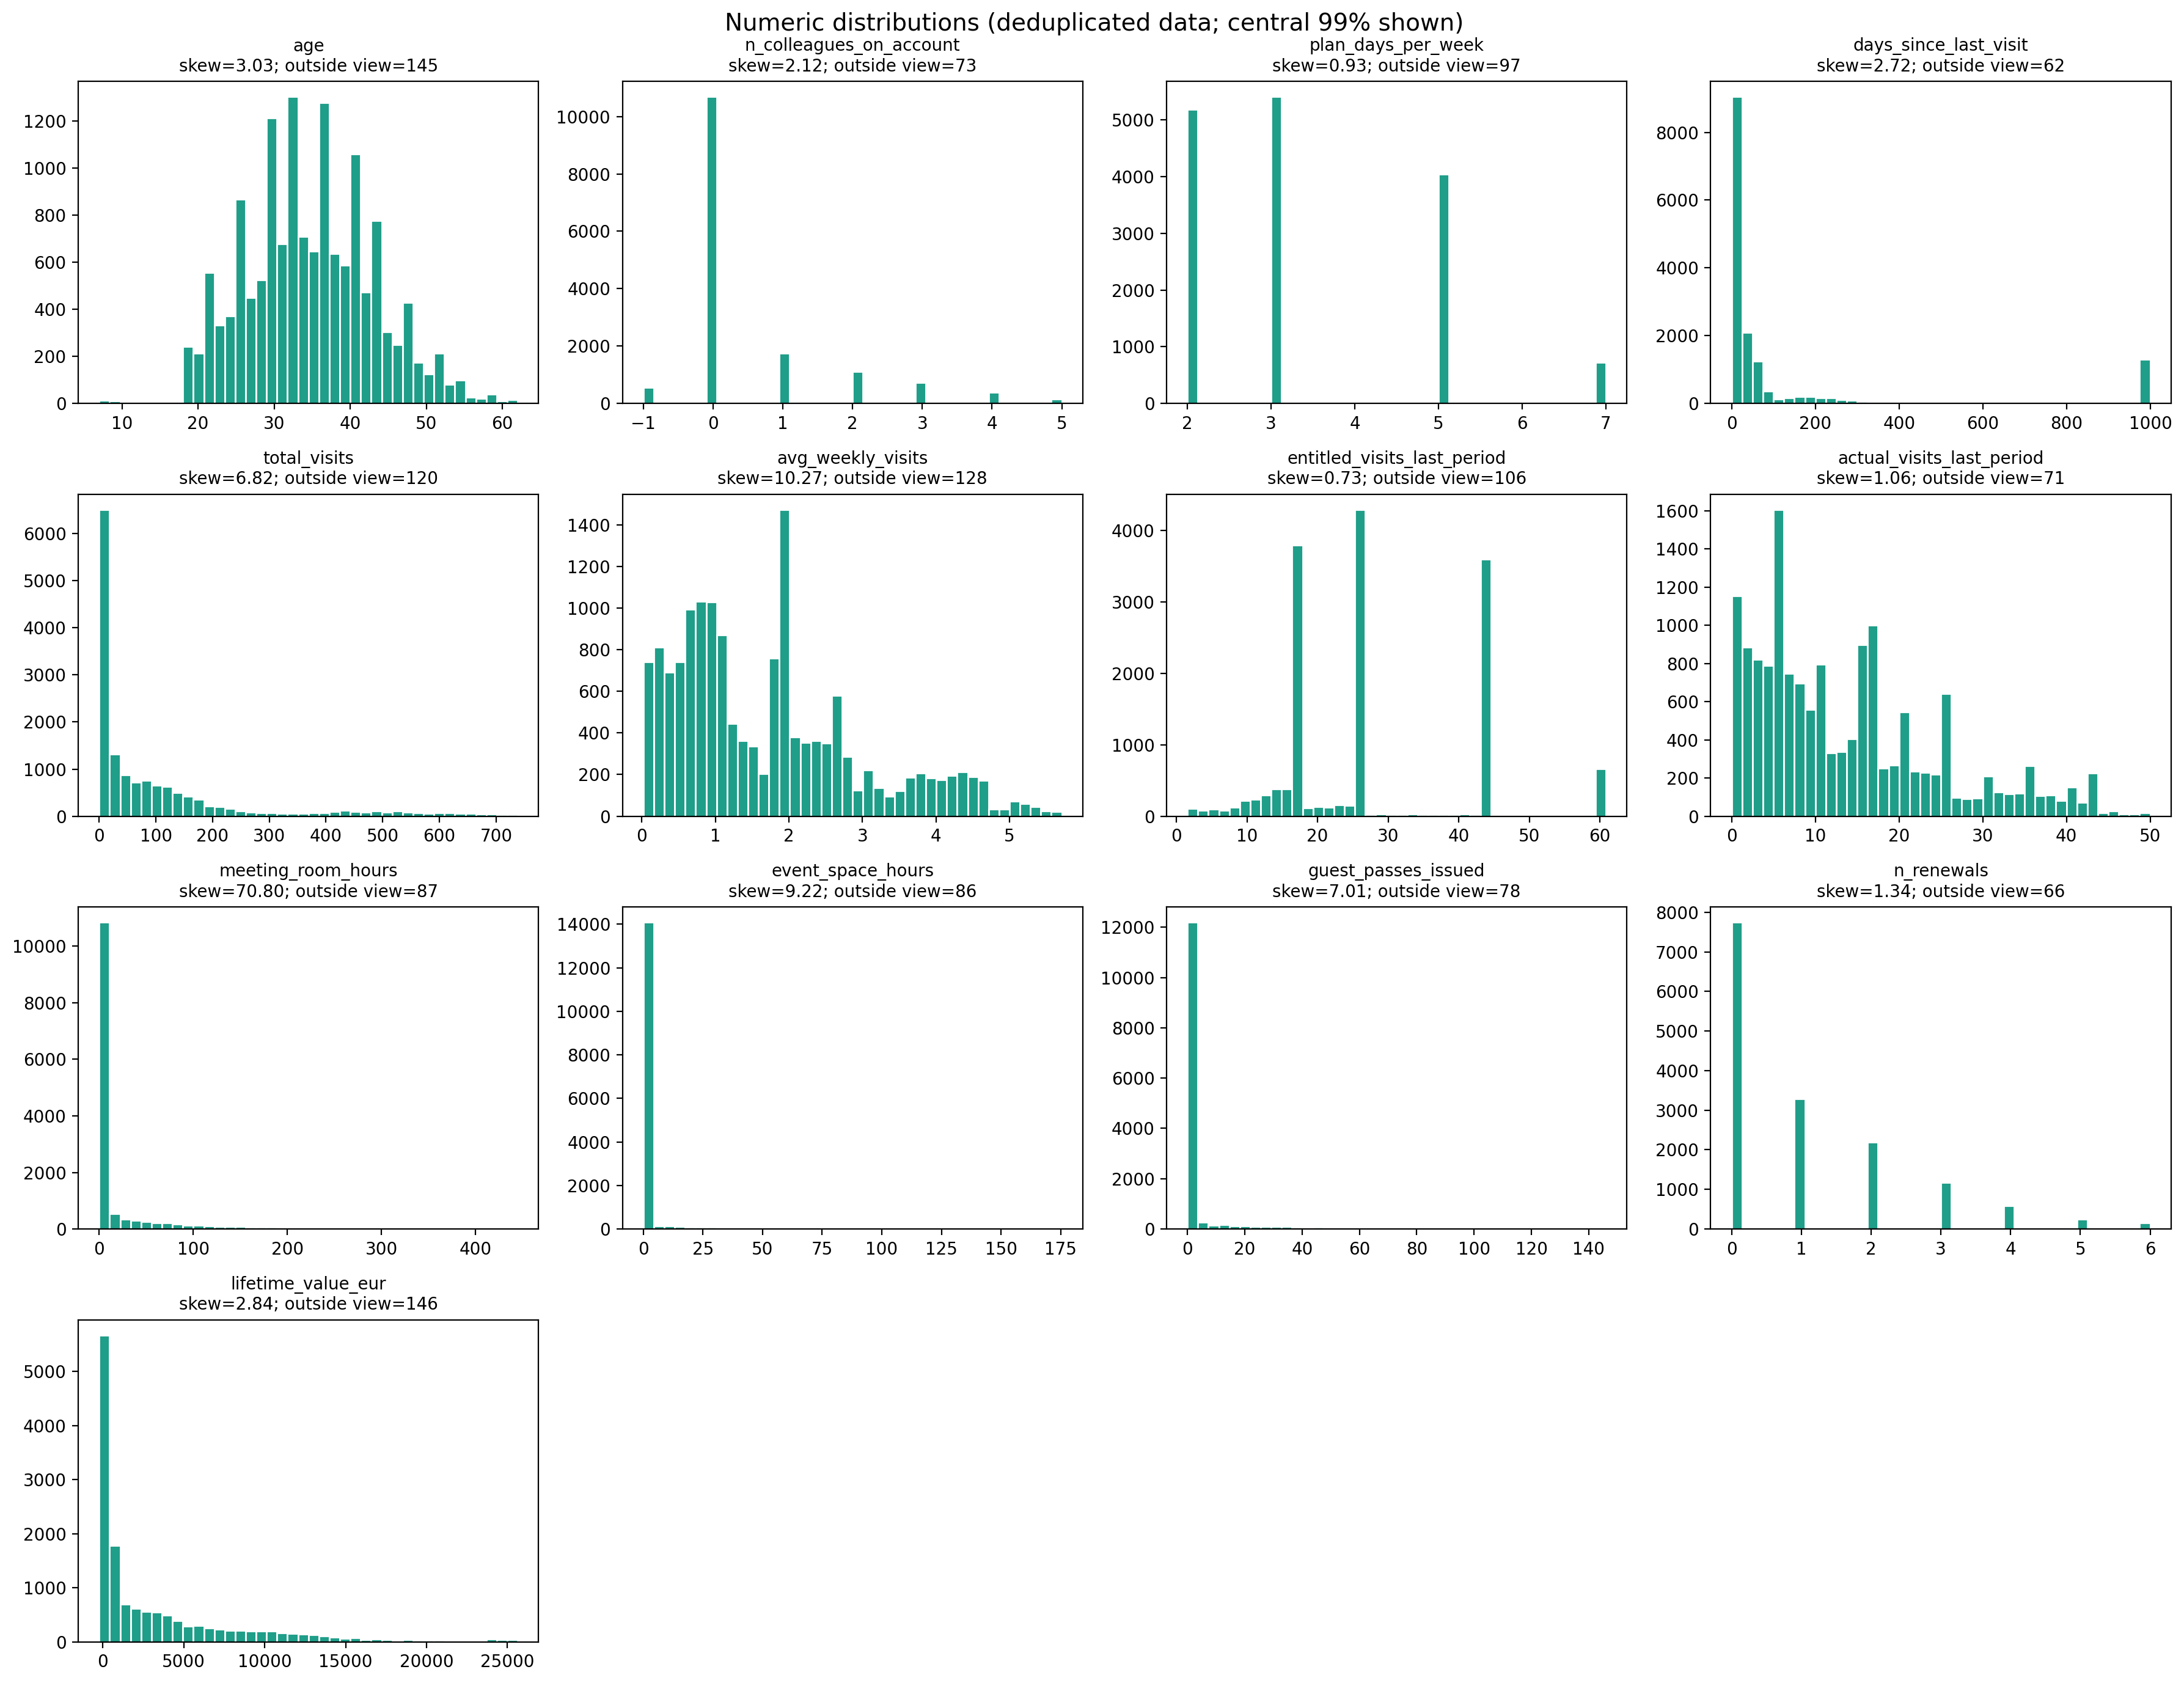

In [13]:
numeric_distribution = acdc.loc[~acdc.duplicated()].copy()
numeric_distribution_cols = [
    "age", "n_colleagues_on_account", "plan_days_per_week", "days_since_last_visit",
    "total_visits", "avg_weekly_visits", "entitled_visits_last_period",
    "actual_visits_last_period", "meeting_room_hours", "event_space_hours",
    "guest_passes_issued", "n_renewals", "lifetime_value_eur",
]
fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, column in zip(axes.flat, numeric_distribution_cols):
    values = numeric_distribution[column].dropna()
    lower, upper = values.quantile([0.005, 0.995])
    central_values = values.loc[values.between(lower, upper)]
    ax.hist(central_values, bins=40, color=PALETTE[4], edgecolor="white")
    ax.set_title(
        f"{column}\nskew={values.skew():.2f}; outside view={len(values) - len(central_values):,}",
        fontsize=10,
    )
for ax in axes.flat[len(numeric_distribution_cols):]:
    ax.axis("off")
fig.suptitle("Numeric distributions (deduplicated data; central 99% shown)", fontsize=14)
fig.tight_layout()
plt.show()


**How to read this overview:** Compare each panel?s concentration and skew rather than comparing bar heights across variables, since their units and scales differ. Long tails and observations outside the displayed central range flag variables that may need robust scaling, transformation, or validation before clustering. The zoom is visual only; no observations are removed by this plot.


## 5. Univariate exploration: distributions and outliers

Boxplots provide a compact view of each variable's median, central spread, and unusually distant observations. Lifetime-value outlier markers are hidden to keep its plot readable; they are still included in the underlying summary. A point outside the whiskers is only a candidate outlier: it may be a data error or a genuine high-usage member, so do not automatically remove it.


The following plots scan for unusually low or high observations across age, attendance, service hours, renewal history, plan allowance, and the corrected LTV estimate.

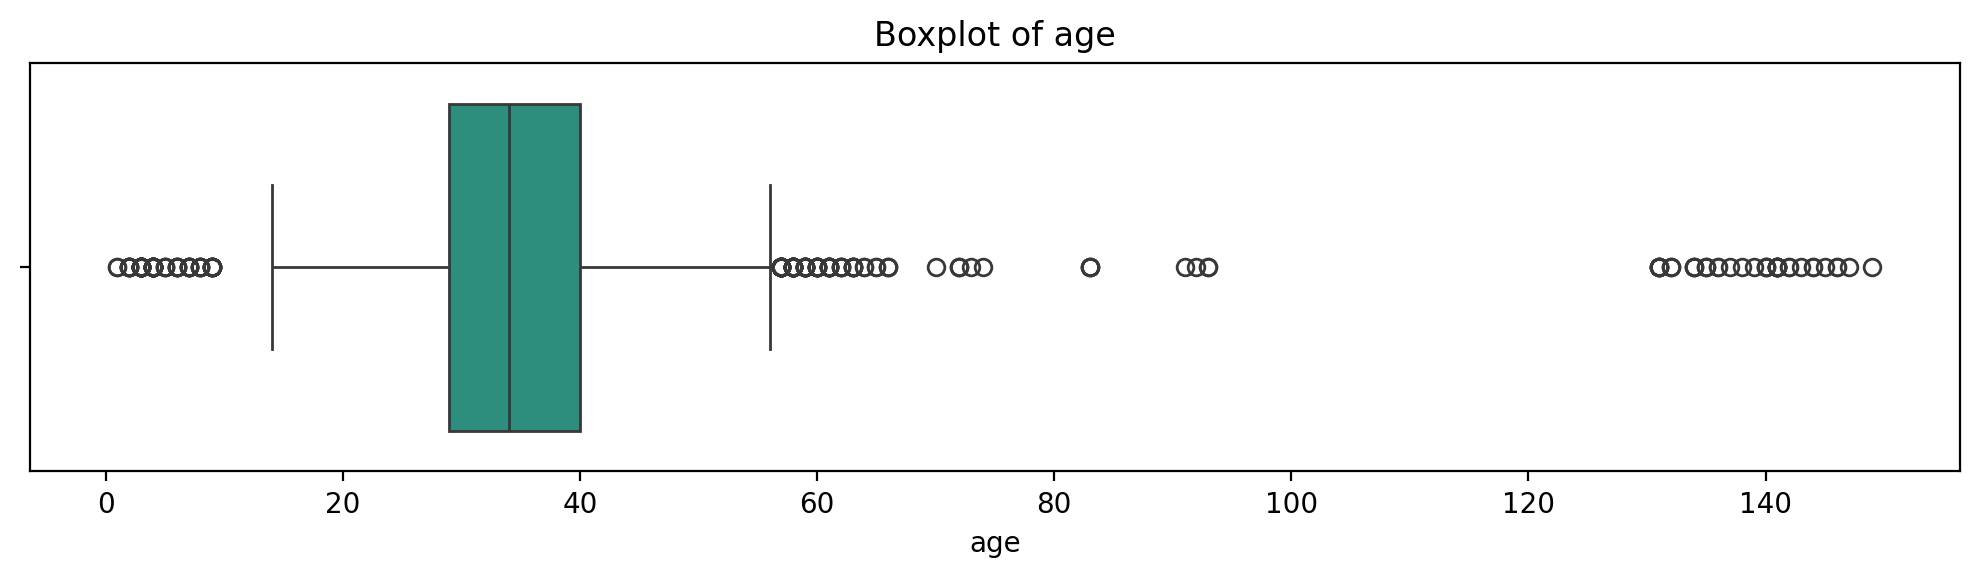

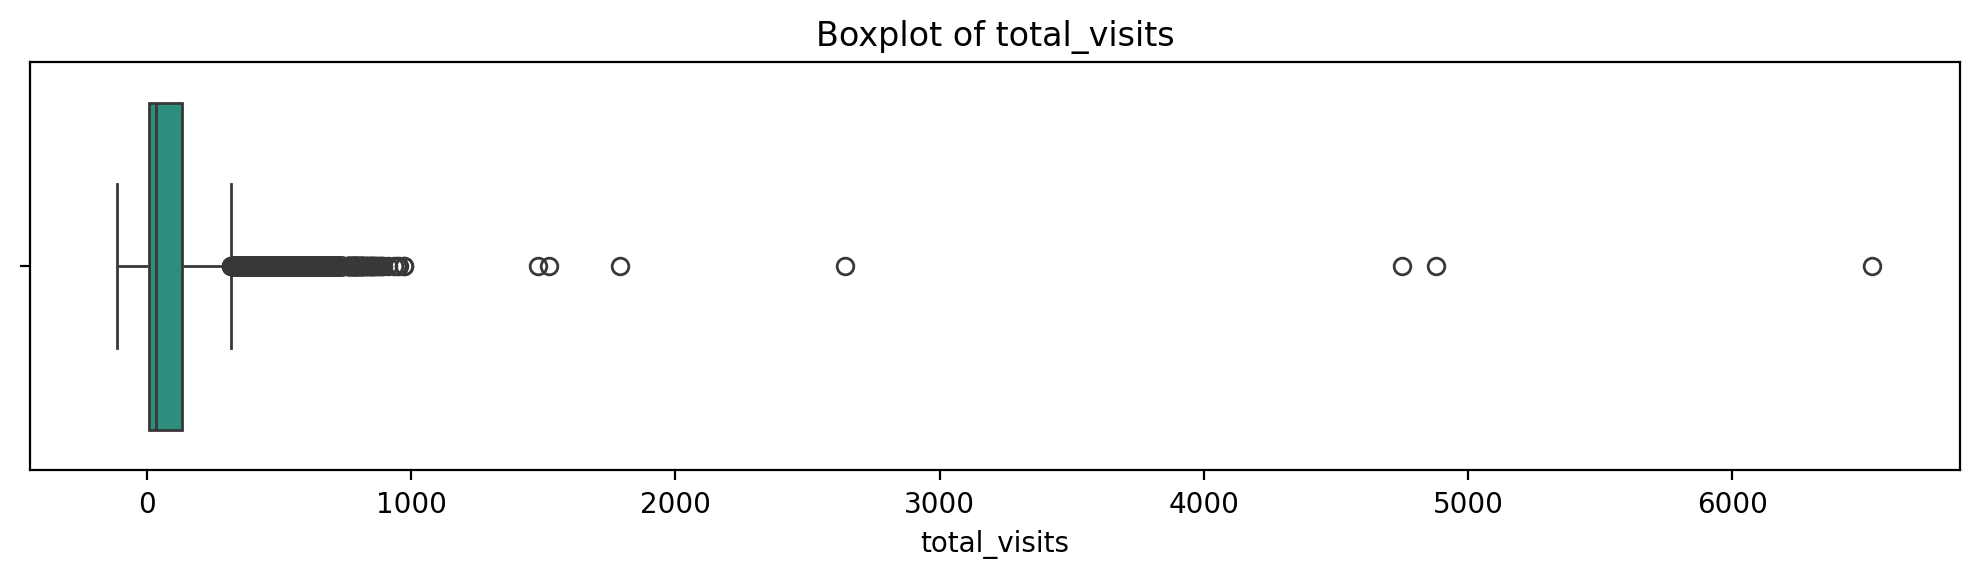

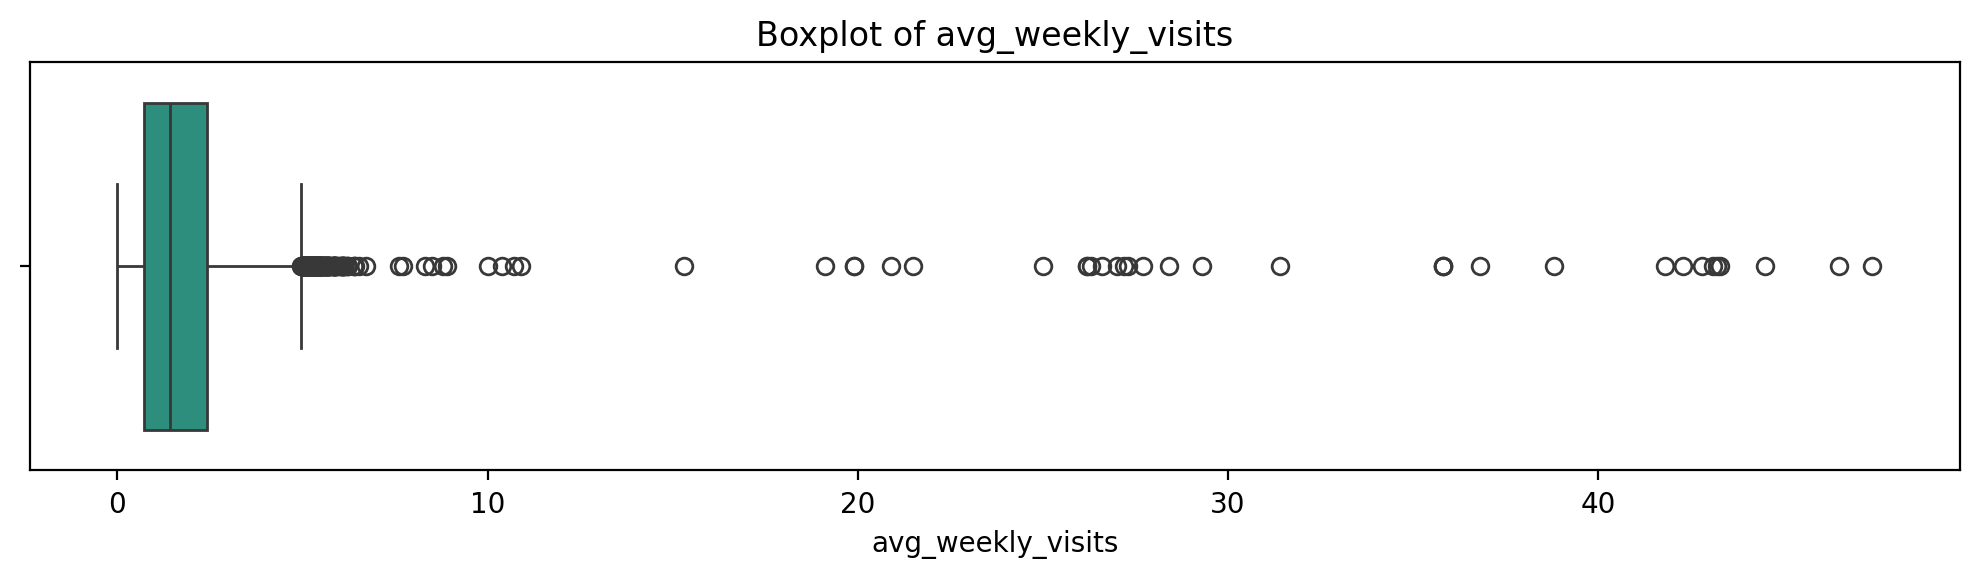

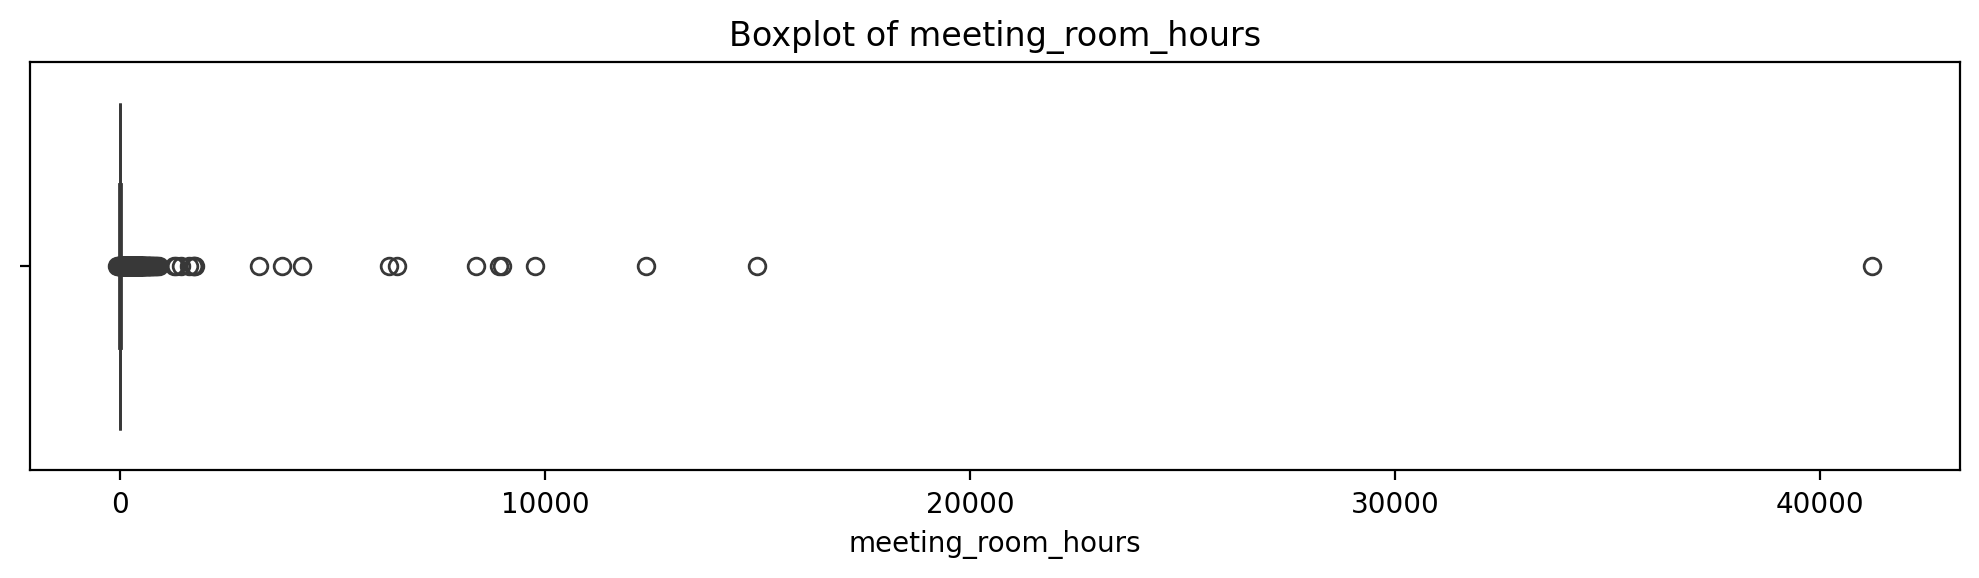

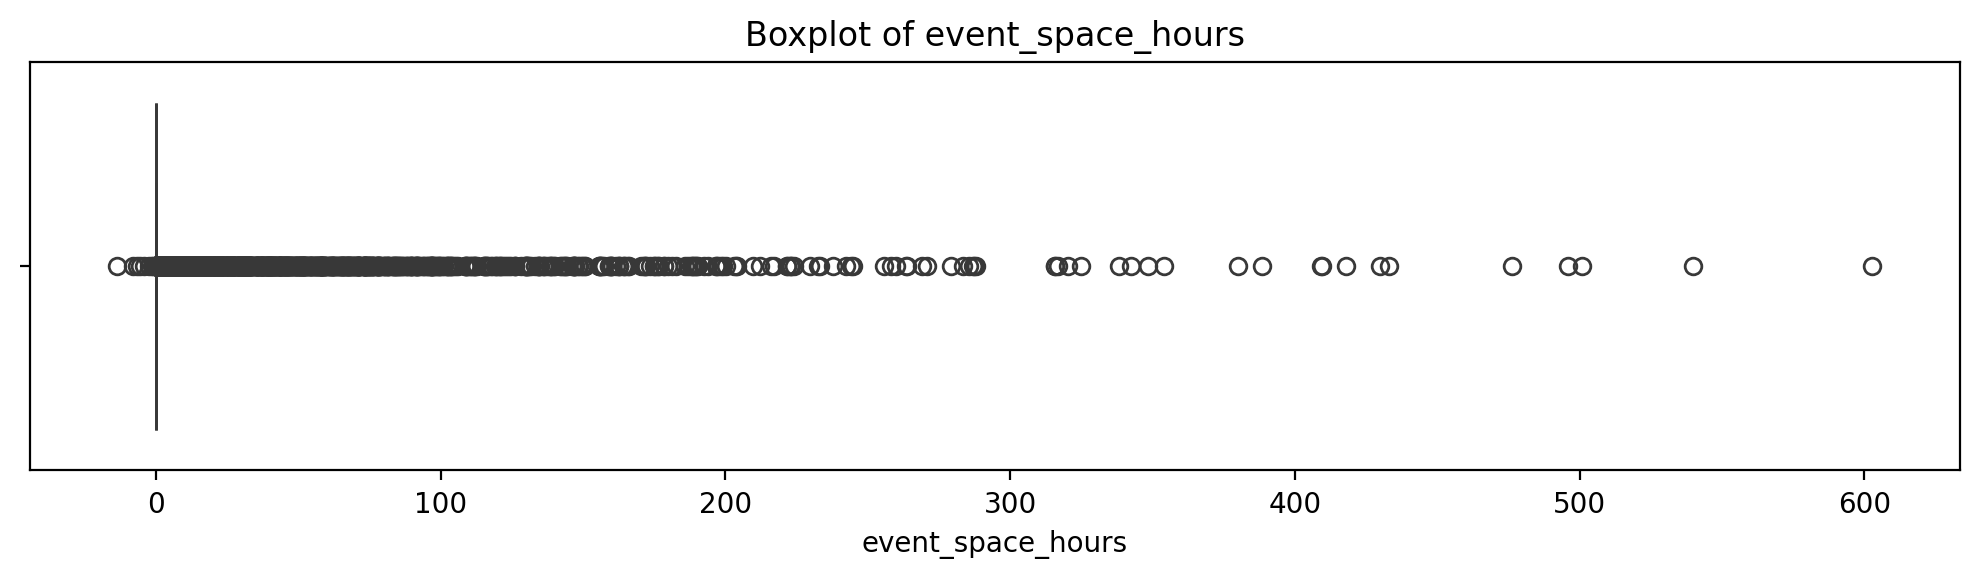

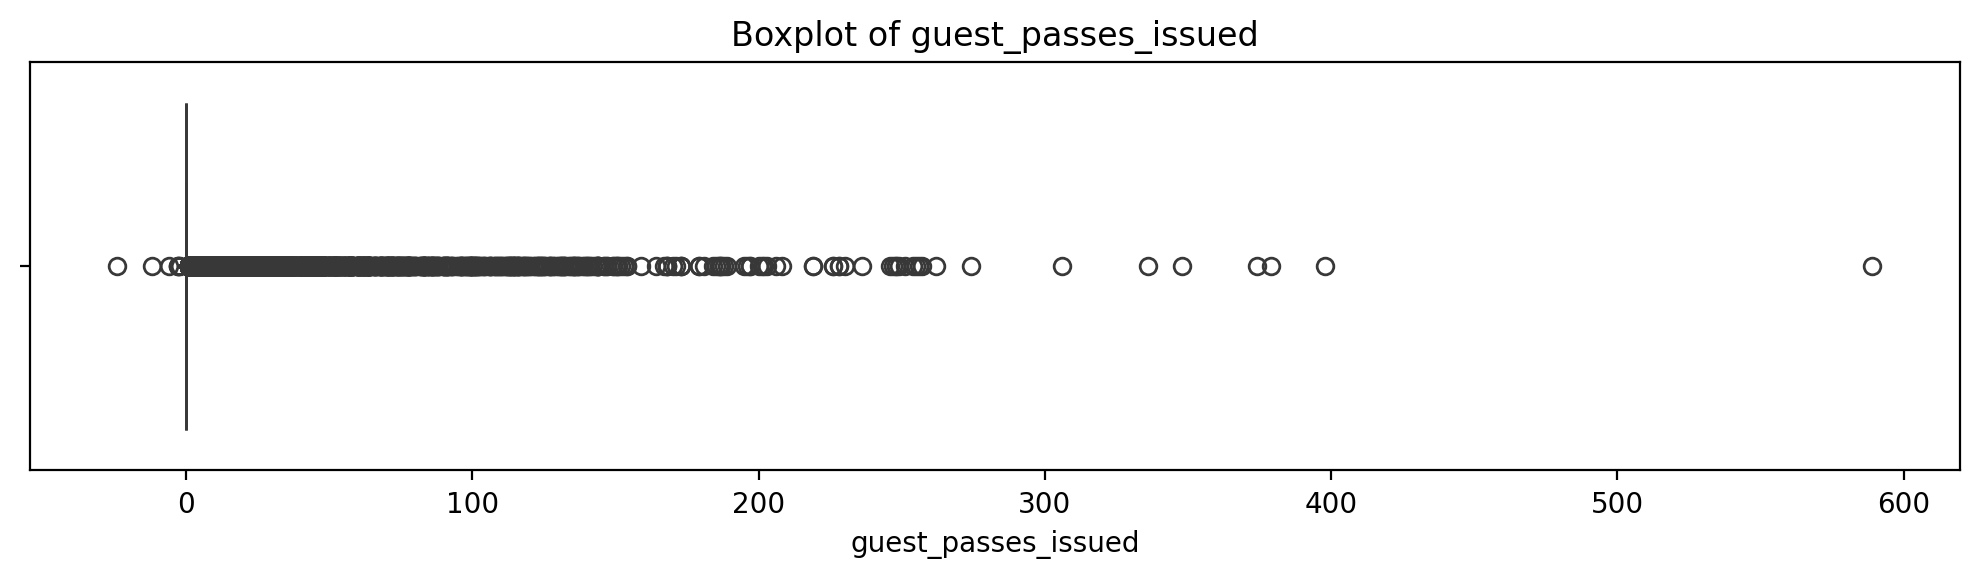

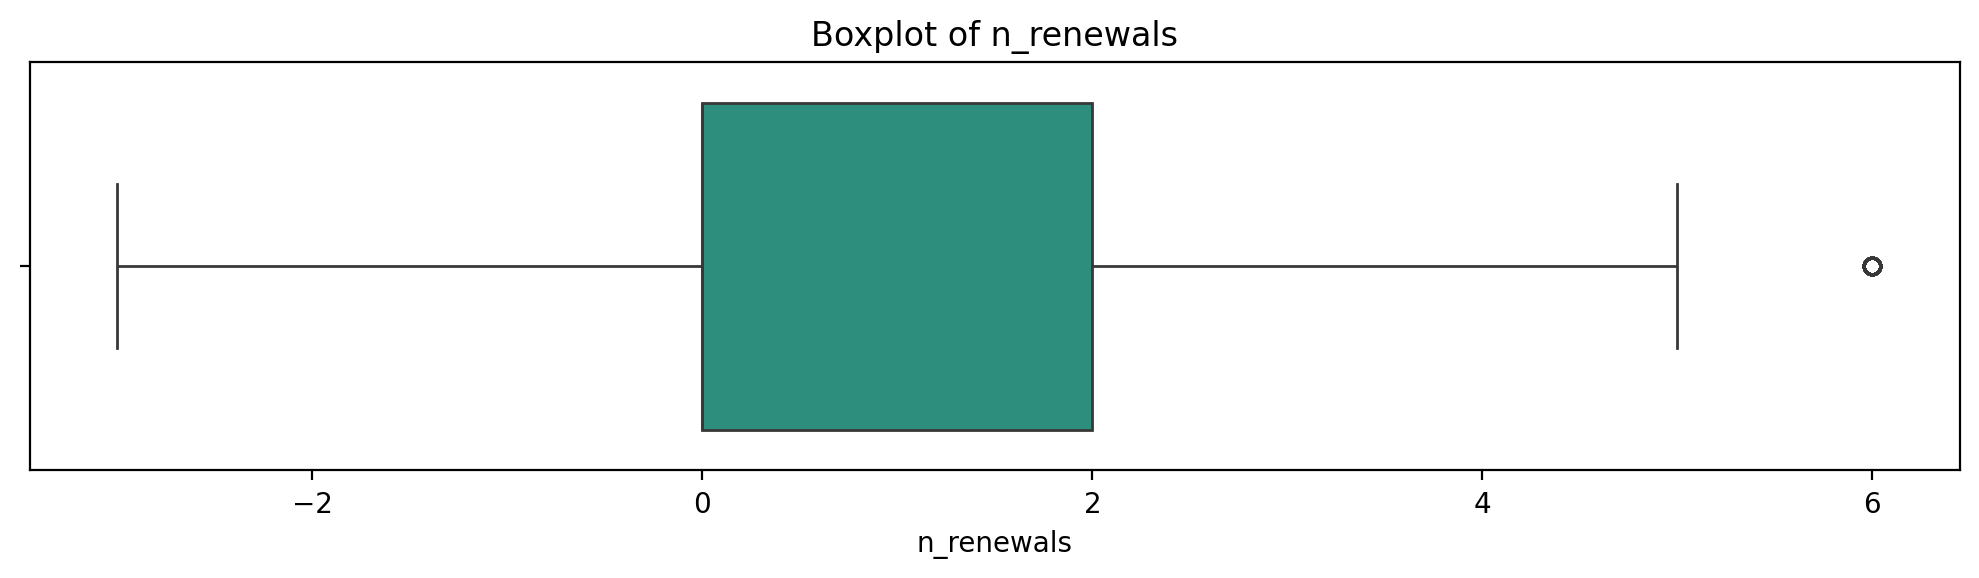

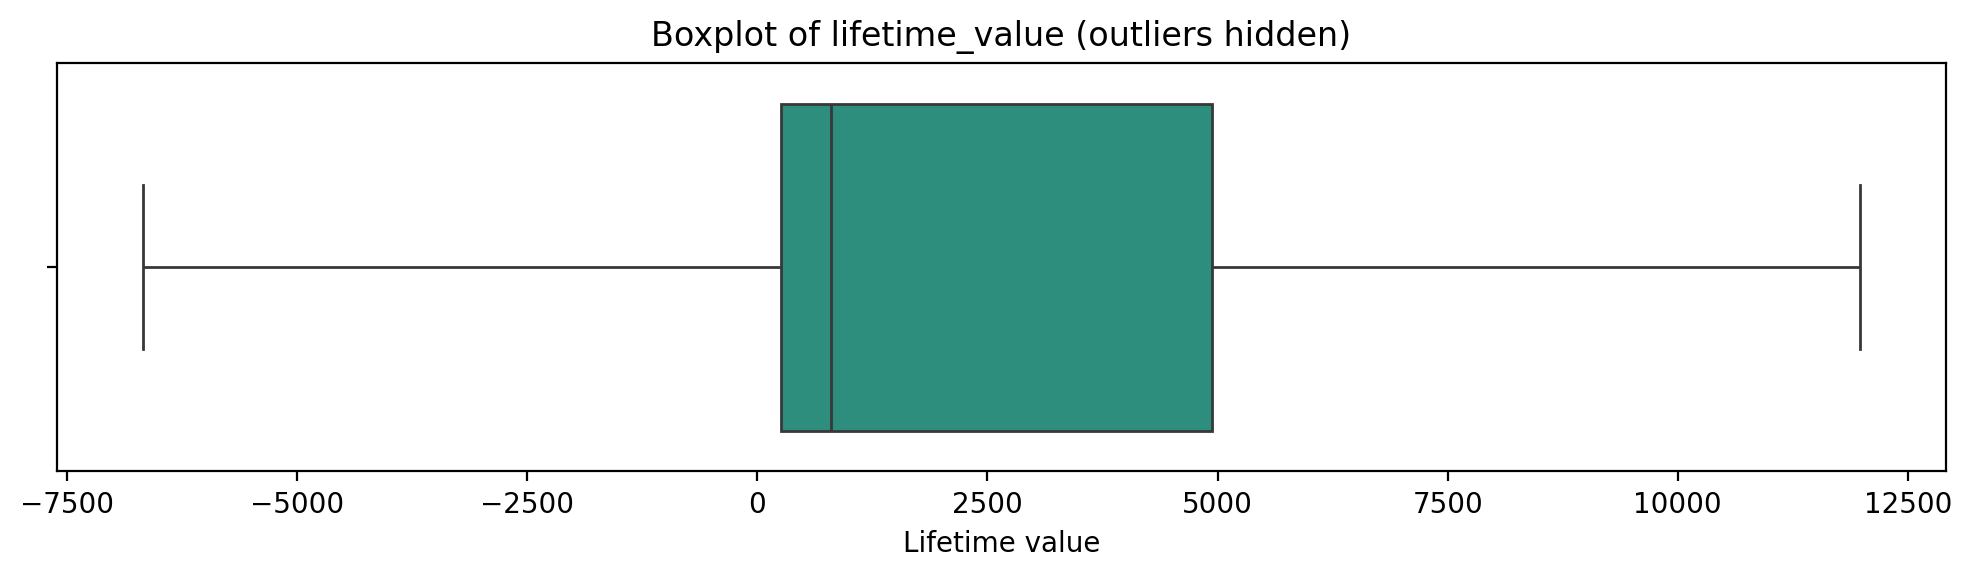

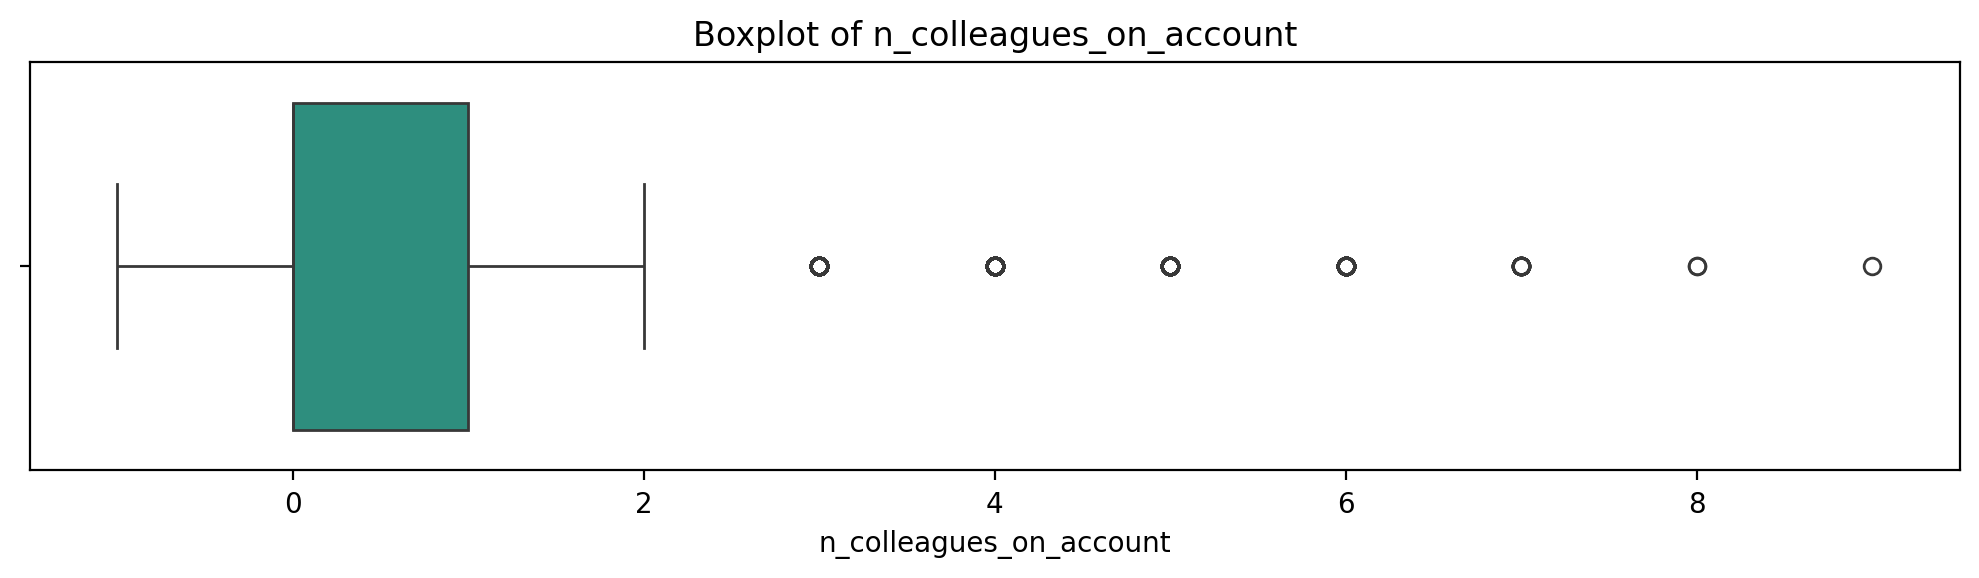

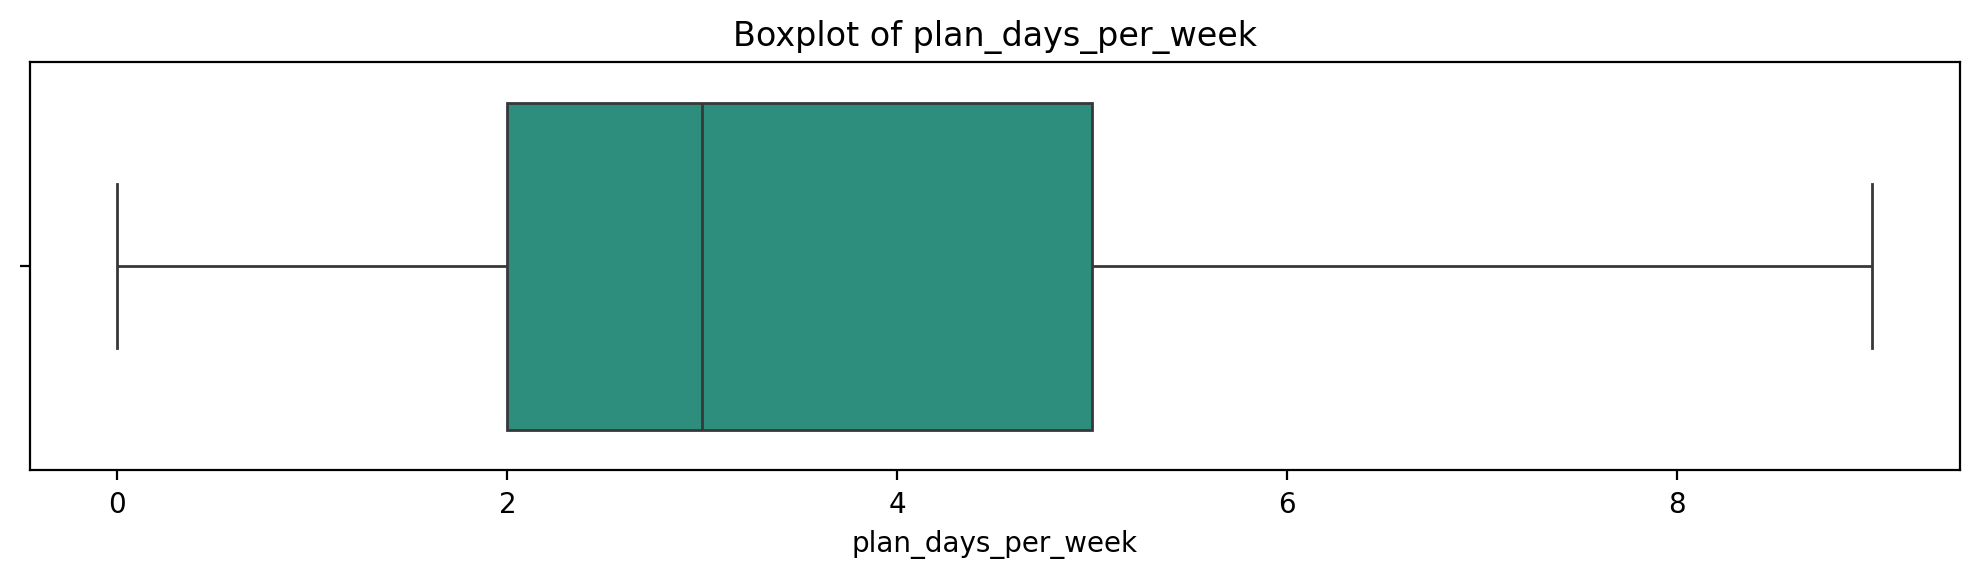

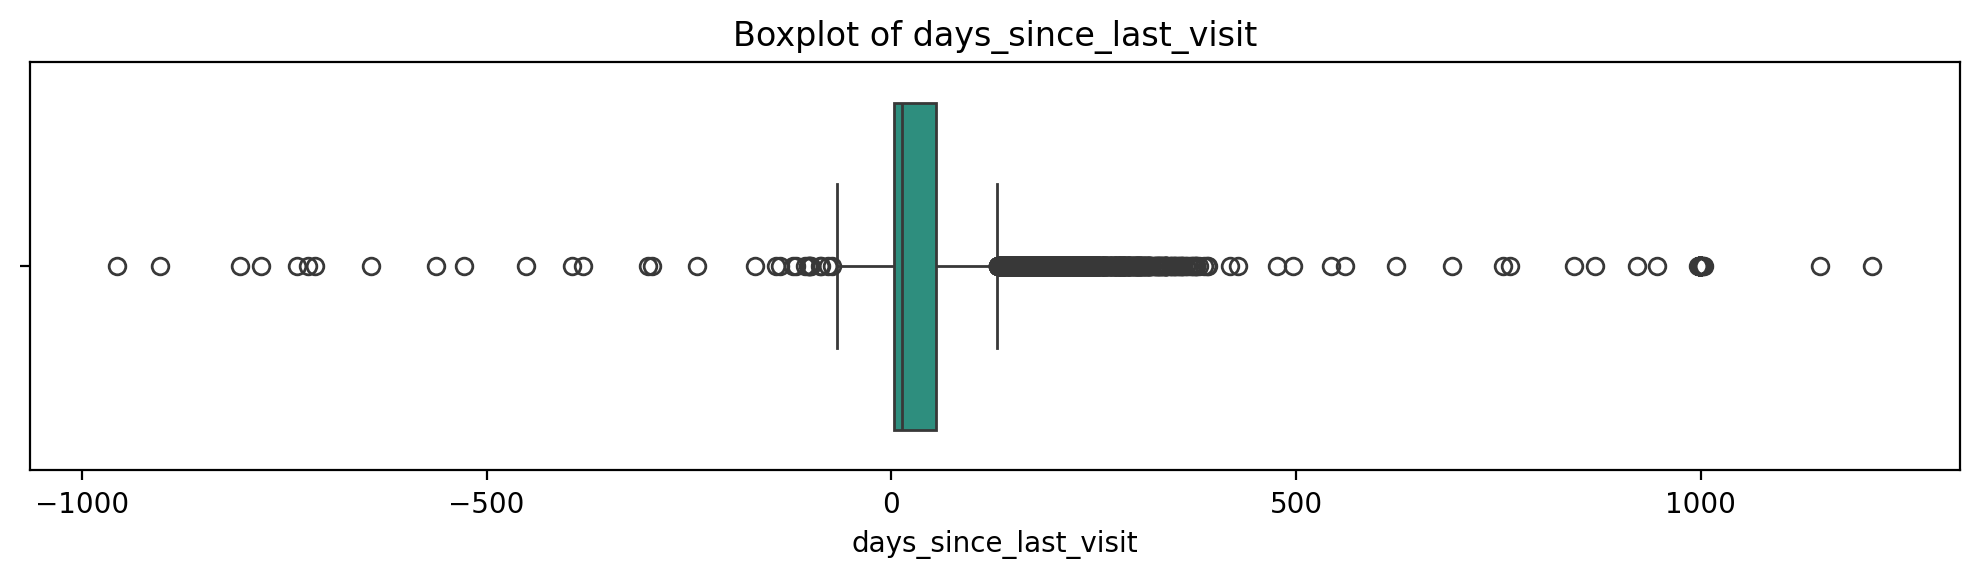

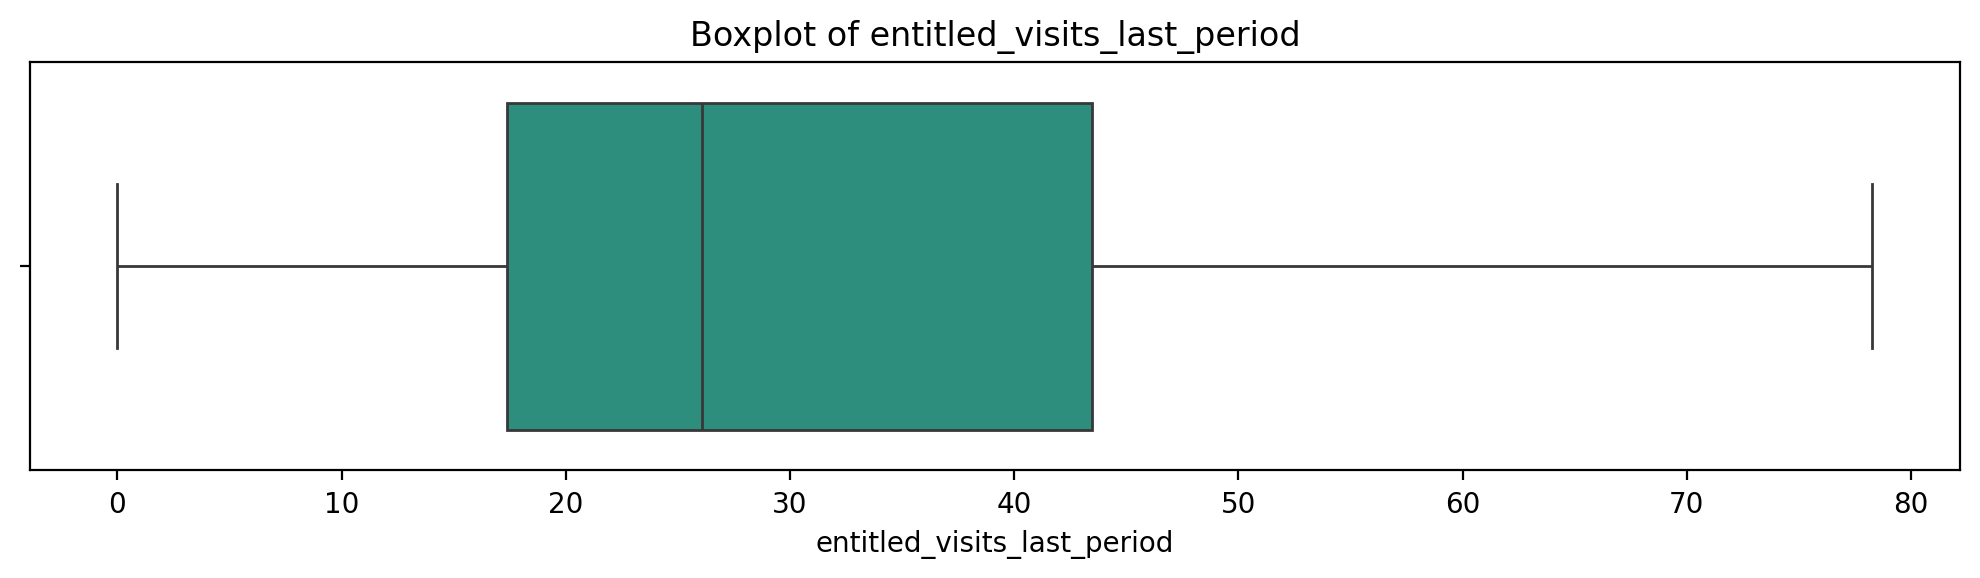

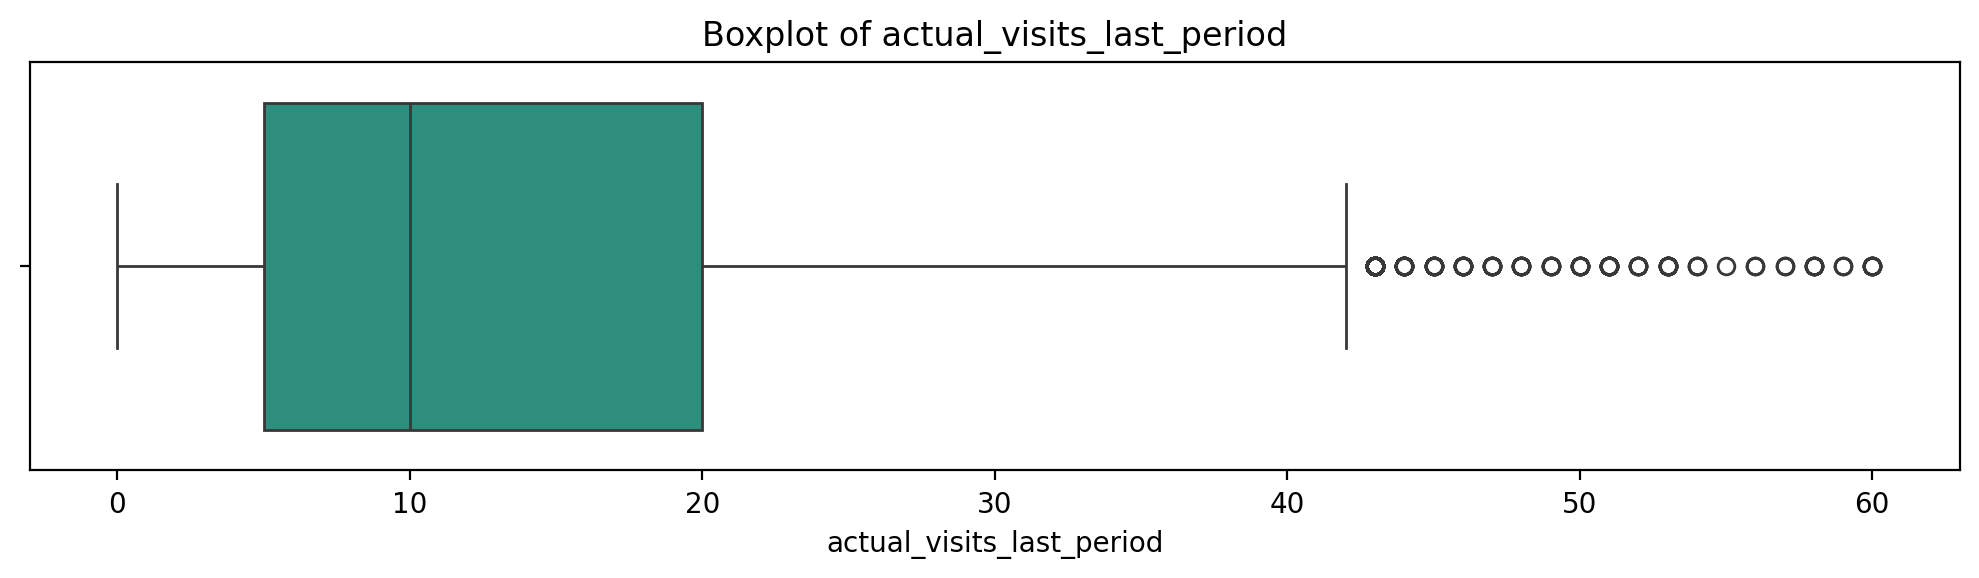

In [14]:
outlier_cols = [
    "age",
    "total_visits",
    "avg_weekly_visits",
    "meeting_room_hours",
    "event_space_hours",
    "guest_passes_issued",
    "n_renewals", 
    "lifetime_value", 
    "n_colleagues_on_account", 
    "plan_days_per_week",
    "days_since_last_visit",
    "entitled_visits_last_period",
    "actual_visits_last_period"
]

for col in outlier_cols:
    plt.figure(figsize=(10, 3))
    values = numeric["lifetime_value_eur"] if col == "lifetime_value" else acdc[col]
    sns.boxplot(x=values, color=PALETTE[4], showfliers=(col != "lifetime_value"))
    title = f"Boxplot of {col}"
    if col == "lifetime_value":
        title += " (outliers hidden)"
        plt.xlabel("Lifetime value")
        plt.ticklabel_format(axis="x", style="plain", useOffset=False)
    plt.title(title)
    plt.tight_layout()
    plt.show()


**Outlier review:** These boxplots compare the main numerical variables on their observed scales. Strong skew can compress the central range in a boxplot; the lack of visible fliers in lifetime value is intentional for readability. Use the plots to locate suspicious values and plan sensitivity checks, not to remove genuine extreme members.

**How to read these plots:** the box shows the interquartile range and the center line is the median; points beyond the whiskers are potential outliers. Extreme total visits, room hours, or renewals may reflect long membership duration as well as unusual behavior. Negative counts or hours and implausible ages need source validation. These plots flag records for review; they do not decide which records should be removed.


## 6. Relationships and potential redundancy

Use Spearman rank correlation to see whether numeric variables tend to increase or decrease together. Spearman is useful for skewed data and monotonic relationships, but it does not measure causation and can still be affected by data-quality problems. Highly correlated measures may be redundant in distance-based clustering, because several versions of the same behavior can give that behavior excess weight.


The selected fields cover demographics, attendance, service use, plan allowance, renewal history, and LTV. The matrix is a first-pass redundancy check, not a feature-selection decision.

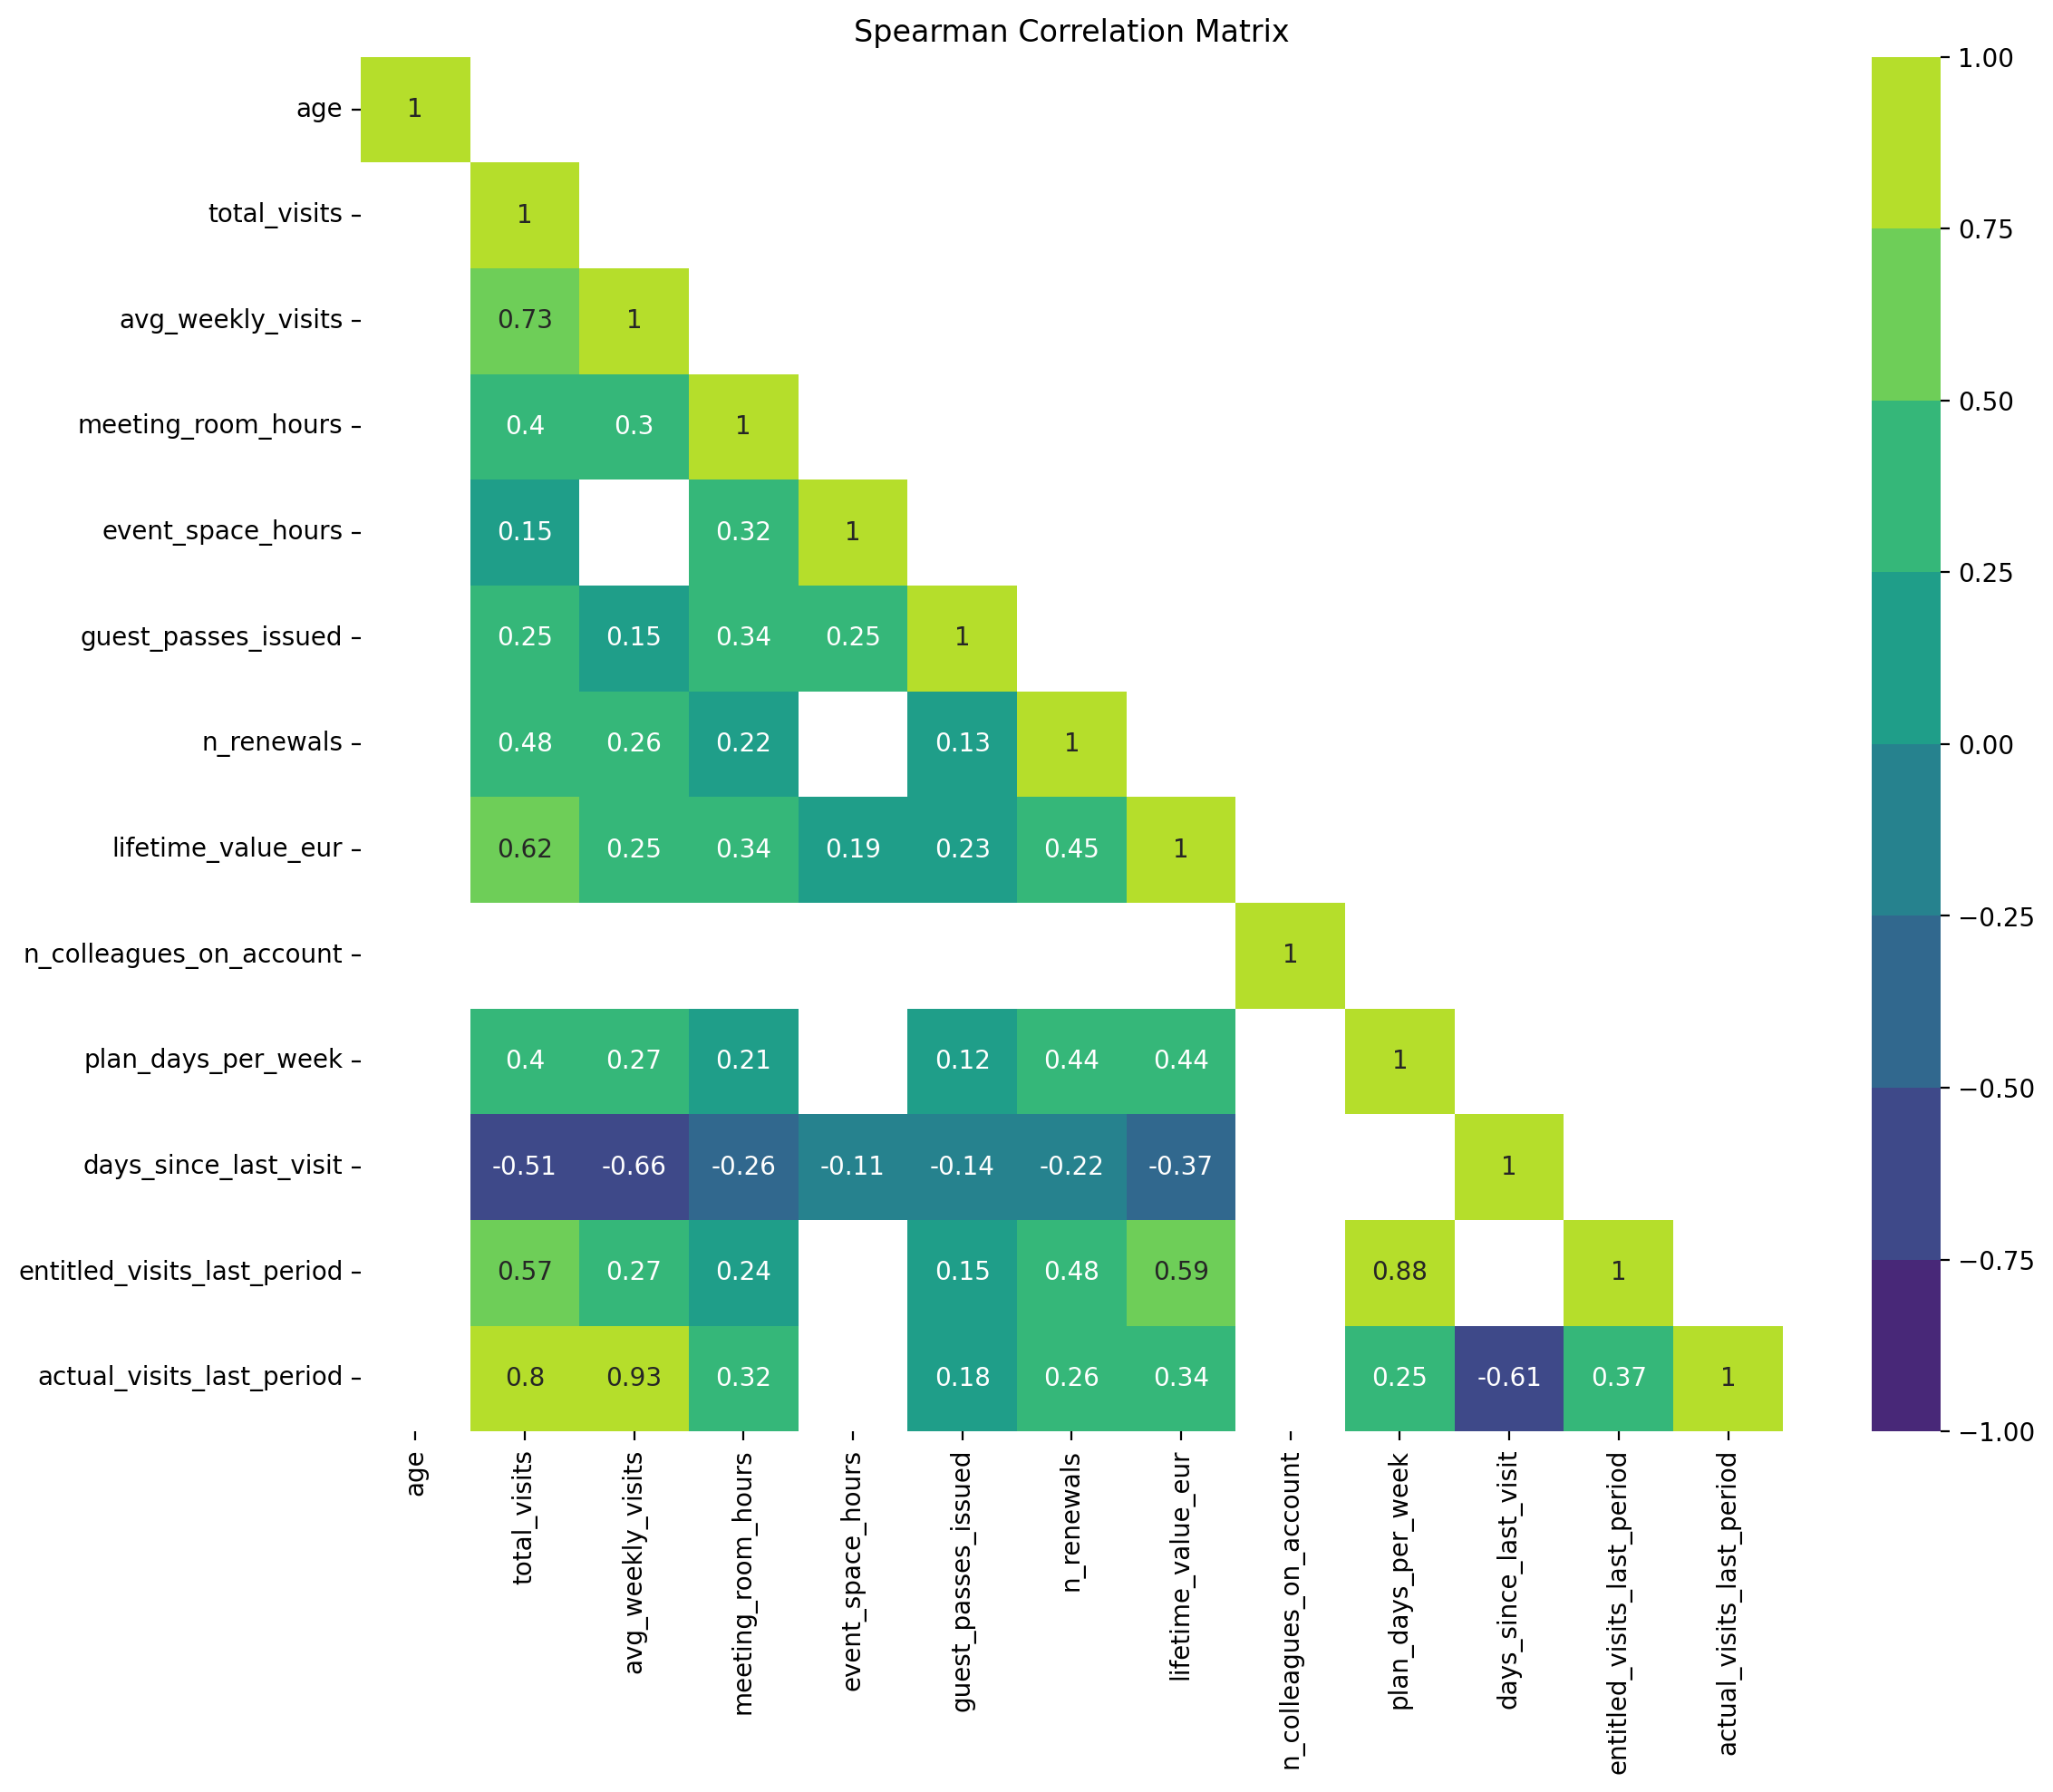

In [15]:
# Numeric variables selected for the correlation analysis
corr_cols = [
    "age",
    "total_visits",
    "avg_weekly_visits",
    "meeting_room_hours",
    "event_space_hours",
    "guest_passes_issued",
    "n_renewals", 
    "lifetime_value_eur", 
    "n_colleagues_on_account", 
    "plan_days_per_week",
    "days_since_last_visit",
    "entitled_visits_last_period",
    "actual_visits_last_period"
]

numeric["lifetime_value_eur"] = acdc["lifetime_value_eur"]

corr = numeric[corr_cols].corr(method="spearman").round(2)
plt.figure(figsize=(12, 10)) #size of the graph
sns.heatmap(
    corr,
    mask=(~np.tril(np.ones_like(corr, dtype=bool))) | (corr.abs() < 0.10),
    #tril hides the upper traingle, upper triangle is True but Seaborn hides True cells, so we add the "~"
    annot=True,#write the correlation value inside each square 
    cmap=PALETTE_CMAP, #colour palette
    center=0,
    vmin=-1,
    vmax=1,
)

plt.title("Spearman Correlation Matrix")
plt.tight_layout() #helps prevent labels from overlapping or being cut off
plt.show()
# also the values close to zero(check distributions because they could still relate to eachother


**What the matrix is for:** Use this as a screening view to find overlapping measures before clustering. Values closer to -1 or +1 indicate stronger monotonic association; values near zero indicate little monotonic association. The matrix uses the available raw values, so data-quality review remains important.

**Reading the heatmap:** the matrix is symmetric, so only one triangle is shown; correlations with absolute values below 0.10 are hidden for readability. In this dataset, average weekly visits and recent-period visits have a strong positive association (about 0.93), while days since last visit is negatively associated with weekly visits (about -0.66). These suggest an engagement/recency dimension, but overlapping attendance measures should not automatically all be given equal weight. Correlation near zero rules out only a strong monotonic pattern, not every possible relationship.


### 6.1 Focused relationship checks

The following plots examine three relationships in more detail: age versus attendance, team size versus meeting-room hours, and event-space hours versus attendance. Hexbin plots group observations into small regions, making dense areas visible when many members overlap. Each plot also reports Spearman correlation as a compact measure of monotonic association.


First, check whether age is associated with average weekly attendance. A hexbin plot shows dense regions where points would otherwise overlap.

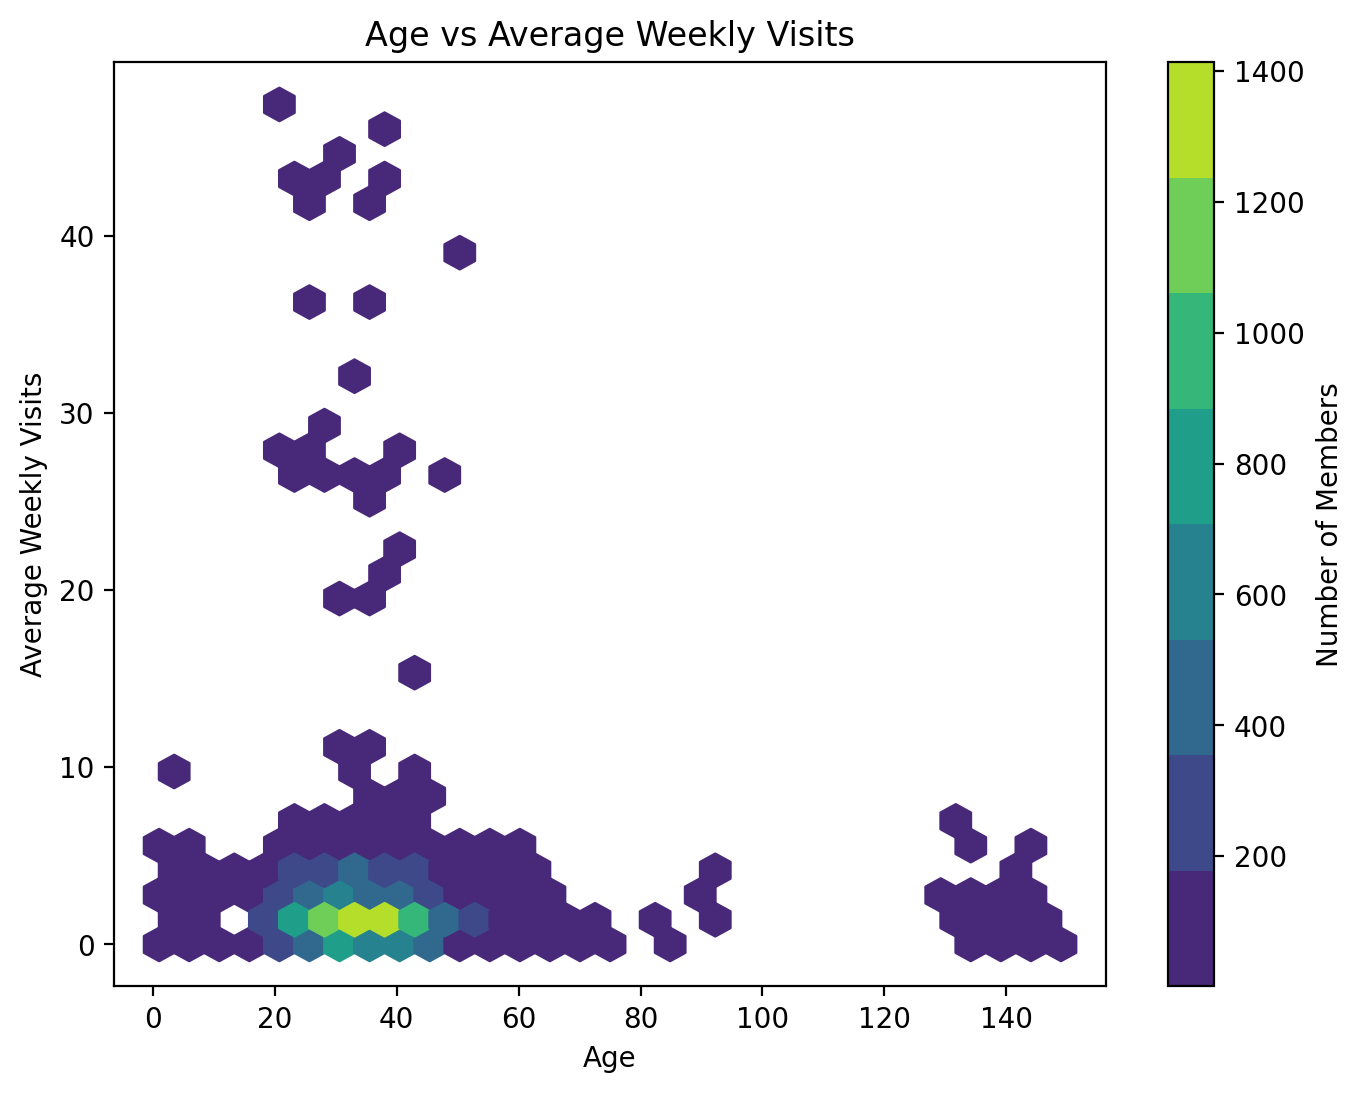

Spearman correlation: 0.01


In [16]:
plt.figure(figsize=(8, 6))

plt.hexbin(
    acdc["age"],
    acdc["avg_weekly_visits"],
    gridsize=30,
    cmap=PALETTE_CMAP,
    mincnt=1
)

plt.xlabel("Age")
plt.ylabel("Average Weekly Visits")
plt.title("Age vs Average Weekly Visits")

plt.colorbar(label="Number of Members")
plt.show()

rho = acdc["age"].corr(acdc["avg_weekly_visits"], method="spearman")
print("Spearman correlation:", round(rho, 2))

**Finding:** age and average weekly visits have a Spearman correlation of about 0.01, indicating almost no monotonic association in this sample. The dense regions still show that members of similar ages can have different attendance levels. Age therefore appears less directly useful than behavioral measures for defining initial clusters; any demographic use should be cautious and primarily descriptive.


Next, compare the number of colleagues on an account with meeting-room hours. This checks whether team size and collaboration-space use appear to move together.

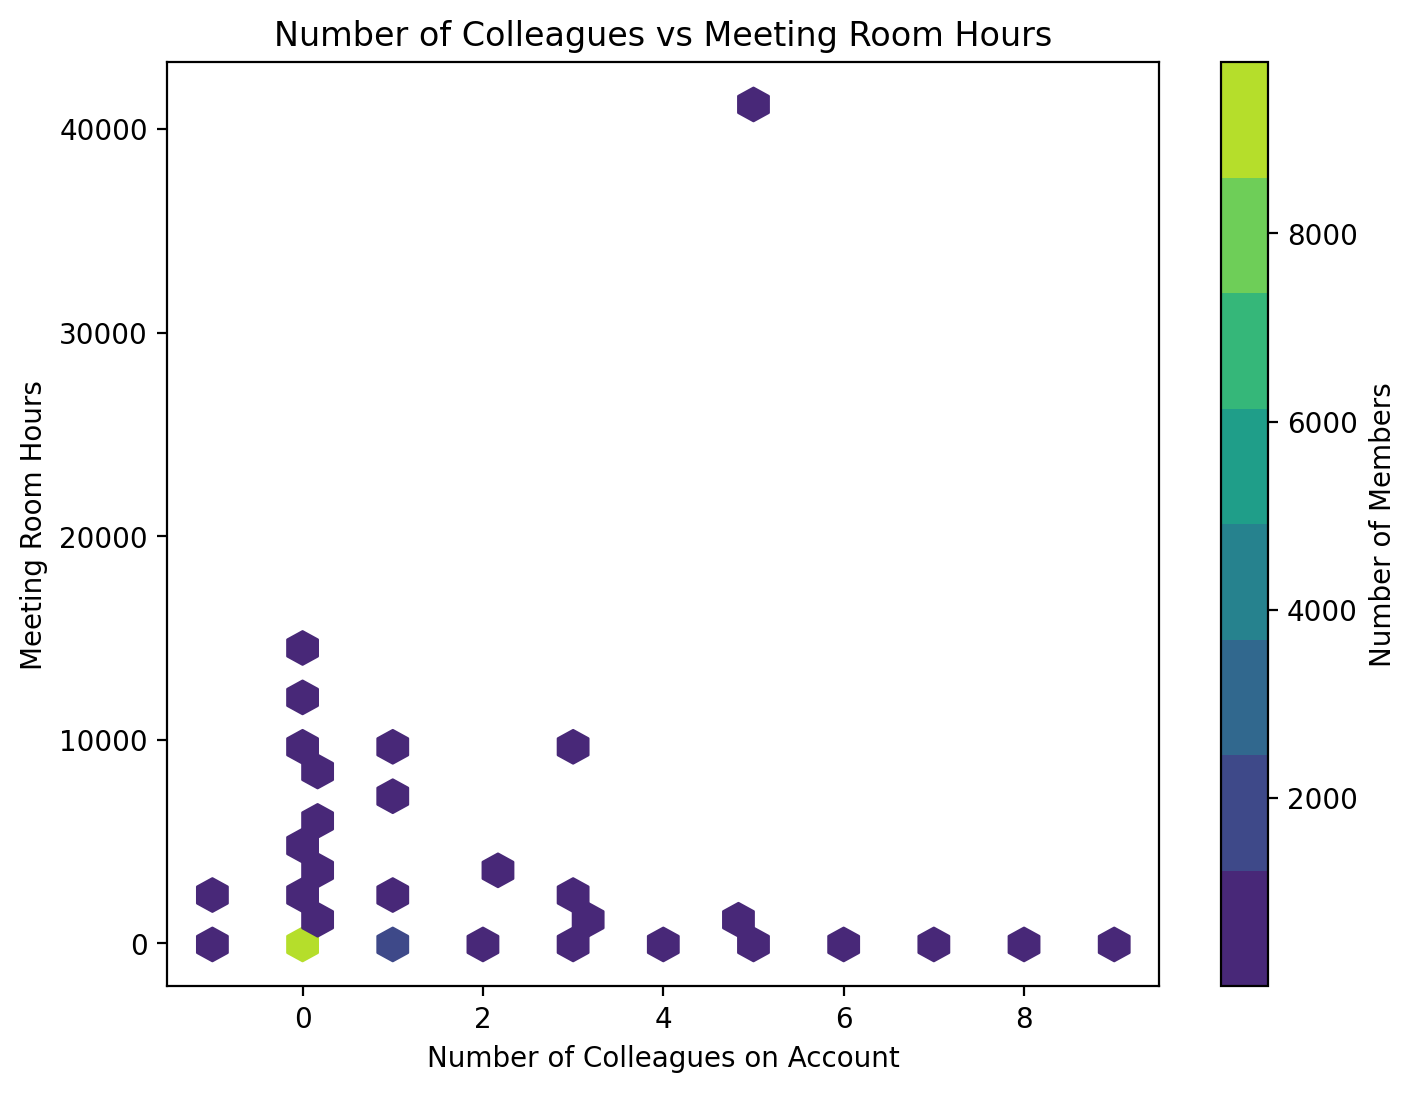

Spearman correlation: 0.01


In [17]:
plt.figure(figsize=(8, 6))

plt.hexbin(
    acdc["n_colleagues_on_account"],
    acdc["meeting_room_hours"],
    gridsize=30,
    cmap=PALETTE_CMAP,
    mincnt=1
)

plt.xlabel("Number of Colleagues on Account")
plt.ylabel("Meeting Room Hours")
plt.title("Number of Colleagues vs Meeting Room Hours")

plt.colorbar(label="Number of Members")
plt.show()
rho = acdc["n_colleagues_on_account"].corr(acdc["meeting_room_hours"], method="spearman")
print("Spearman correlation:", round(rho, 2))

**Finding:** number of colleagues and meeting-room hours also have a near-zero Spearman correlation (about 0.01). Most members have small values, while extreme room-hour values and negative colleague counts are visible data-quality concerns. Team size and room use should be checked against the data definitions before they are used as model inputs.


Finally, compare event-space hours with average weekly visits to see whether event use follows the same pattern as regular attendance.

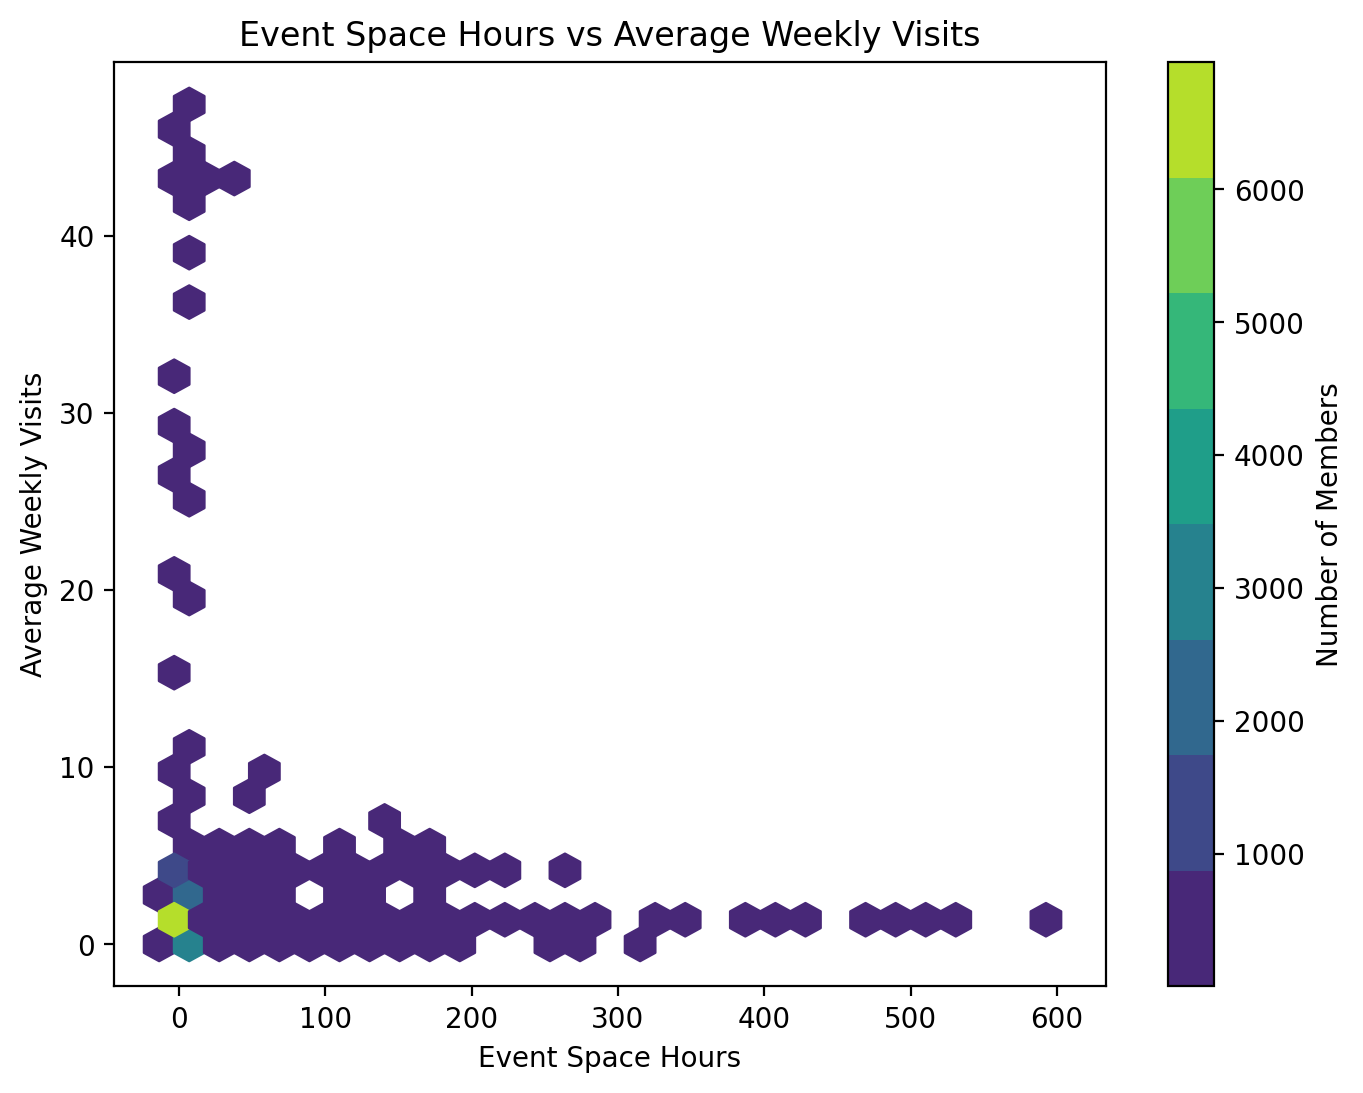

Spearman correlation: 0.07


In [18]:
plt.figure(figsize=(8, 6))

plt.hexbin(
    acdc["event_space_hours"],
    acdc["avg_weekly_visits"],
    gridsize=30,
    cmap=PALETTE_CMAP,
    mincnt=1
)

plt.xlabel("Event Space Hours")
plt.ylabel("Average Weekly Visits")
plt.title("Event Space Hours vs Average Weekly Visits")

plt.colorbar(label="Number of Members")
plt.show()

rho = acdc["event_space_hours"].corr(acdc["avg_weekly_visits"], method="spearman")
print("Spearman correlation:", round(rho, 2))

**Finding:** event-space hours and average weekly visits have a weak Spearman association (about 0.07). Most members are concentrated at low values, and high event-space use does not simply correspond to frequent workspace attendance. Event-space use may capture a different behavior, although its skew and extreme values need attention.


## 7. Feature engineering: describe behavior more directly

Derived features can express behavior more meaningfully than raw fields. Here we examine (1) **visit utilization**, the share of entitled visits actually used; (2) **service breadth**, the number of additional services used; and (3) a candidate **mail-or-storage indicator**, which groups two services that may signal a need beyond desk attendance. These features may help distinguish members with similar raw visit counts but different plan allowances or service needs. Their usefulness for clustering must still be tested.


### 7.1 Visit utilization

Calculate actual visits divided by entitled visits during the last period. If entitlement is zero, the ratio is undefined, so the code records it as missing rather than treating it as zero. Values near 0 indicate low use relative to allowance; values near 1 indicate use close to the allowance.


In [19]:
acdc["visit_utilization"] = (
    acdc["actual_visits_last_period"] /
    acdc["entitled_visits_last_period"].replace(0, np.nan)
)

acdc["visit_utilization"].describe()

count    15455.000000
mean         0.517490
std          0.312224
min          0.000000
25%          0.238445
50%          0.517539
75%          0.804906
max          1.000000
Name: visit_utilization, dtype: float64

**Feature definition:** This ratio answers, "What share of the member's entitled visits did they use?" Replacing a zero denominator with missing avoids division by zero and avoids claiming that a member with no allowance had zero utilization.

**Example:** if a member is entitled to 20 visits and uses 10, utilization is `10 / 20 = 0.50`, or 50%.


**Finding:** average utilization is about 52%, with a wide range from 0 to 1. This indicates members differ in how fully they use their plan allowance. Utilization can complement absolute attendance, but should be reviewed alongside plan terms and records with zero entitlement.


The histogram complements the summary statistics by showing the shape of the utilization distribution and whether values cluster near low, middle, or high plan use.

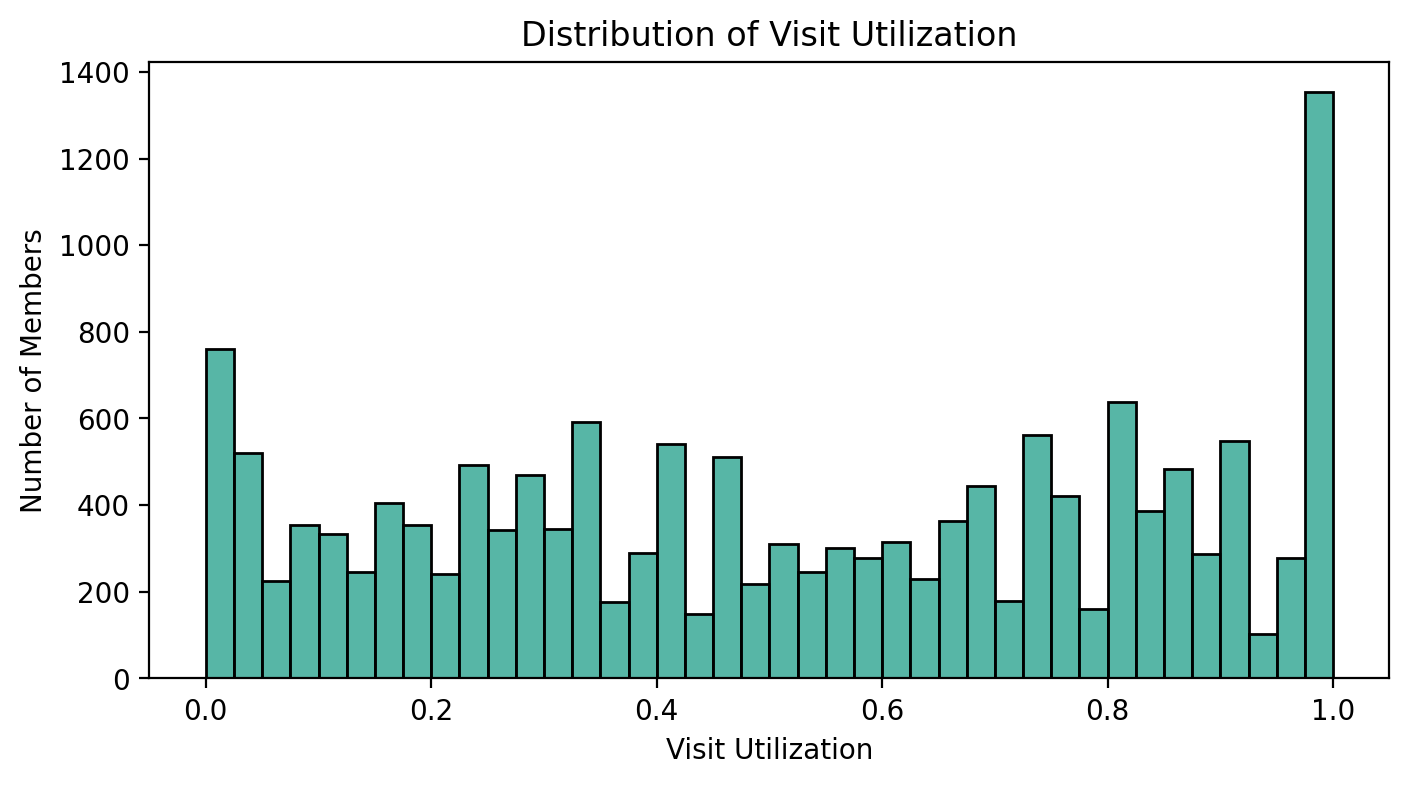

In [20]:
plt.figure(figsize=(8, 4))

sns.histplot(
    acdc["visit_utilization"].dropna(),
    bins=40,
    color=PALETTE[4]
)

plt.title("Distribution of Visit Utilization")
plt.xlabel("Visit Utilization")
plt.ylabel("Number of Members")

plt.show()

**Reading the histogram:** The distribution shows how many members use a small versus large share of their allowance. Together with the summary above, the spread—not just the average—can reveal under-use and near-full-use patterns that may be useful for segmentation.

### 7.2 Number of additional services used

Count the optional service indicators that are true for each member. This creates a compact summary of service breadth. It does not show which services a member uses, so later comparisons inspect individual service patterns as well.


In [21]:
service_cols = [
    "uses_meeting_rooms",
    "uses_event_space",
    "uses_guest_passes",
    "uses_print",
    "uses_mail_handling",
    "uses_phone_booths",
    "uses_day_passes",
    "uses_storage",
    "uses_bike_locker"
]

acdc["n_services_used"] = acdc[service_cols].sum(axis=1)

acdc["n_services_used"].value_counts().sort_index()

n_services_used
0    3091
1    4645
2    3240
3    2141
4    1397
5     690
6     224
7      34
8       3
Name: count, dtype: int64

**Feature definition:** `n_services_used` ranges from zero to the number of listed service indicators. Summing the Boolean indicators produces a simple breadth measure; it treats each service equally and does not capture service frequency or value.

**Finding:** one additional service is the most common count (4,645 members); 3,091 members have zero, and increasingly few members use many services. This feature can distinguish basic workspace use from broader service use, but service breadth alone can hide which services are involved.


Plot the count feature to make its skew and the prevalence of broad versus limited service use easier to see.

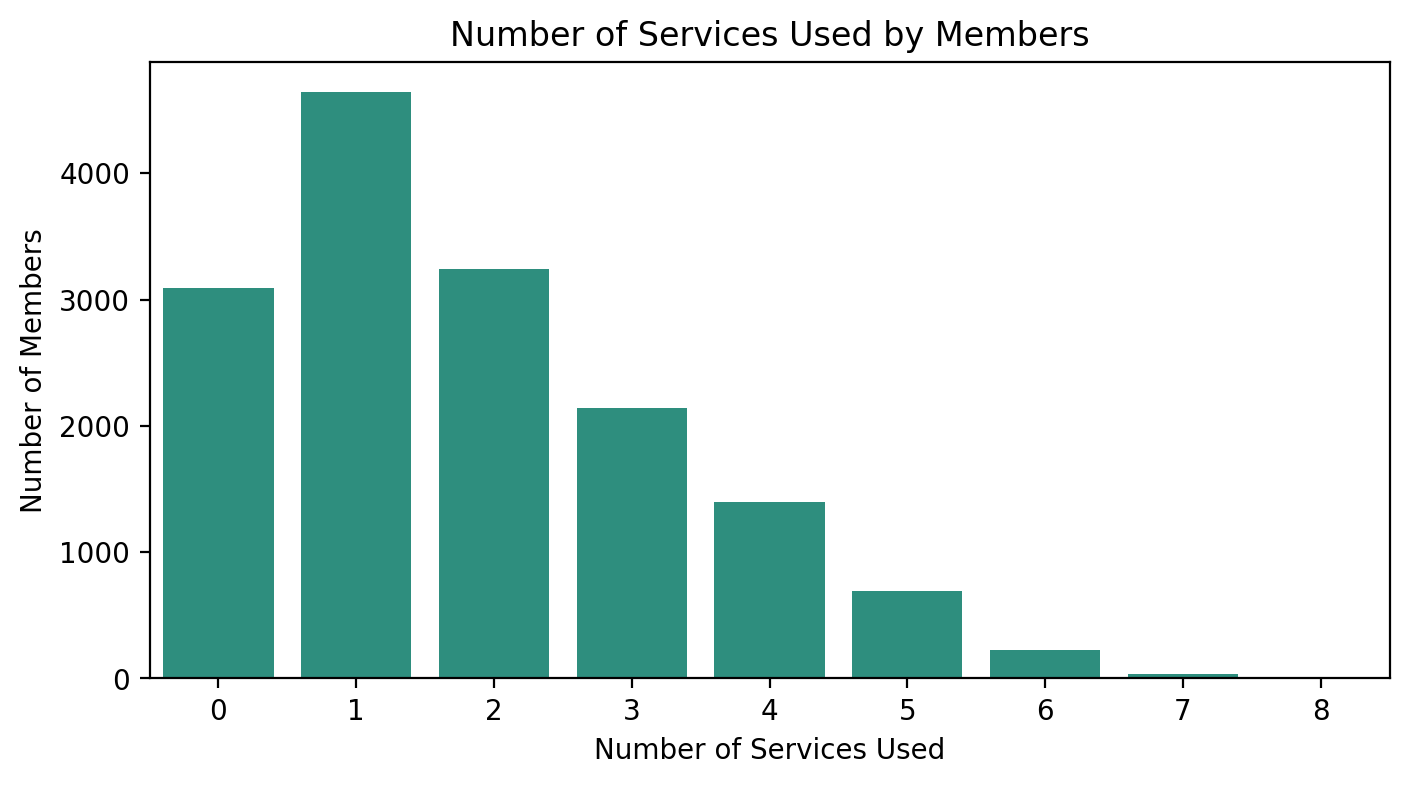

In [22]:
plt.figure(figsize=(8, 4))

sns.countplot(
    data=acdc,
    x="n_services_used",
    color=PALETTE[4]
)

plt.title("Number of Services Used by Members")
plt.xlabel("Number of Services Used")
plt.ylabel("Number of Members")

plt.show()

**Reading the count plot:** One optional service is the most common pattern (4,645 members); 3,091 members report none. Counts decline substantially at higher service breadth. Consider this a compact candidate feature, and use the individual service summary below to retain information about which services members choose.

## 8. EDA synthesis: candidate behavioral dimensions

The goal is to identify plausible differences in member behavior, not to predict an existing label. The analyses below test whether candidate dimensions vary and whether they appear reliable enough to investigate in clustering: attendance and recency, use relative to plan allowance, service use, and possible team-oriented behavior. Plan, industry, country, age, and gender can help describe members, but should not automatically define behavior-based clusters.

Later clustering work must test these candidates rather than assume that every feature is useful. No model is fitted in this notebook.


### 8.1 Data-quality review before interpreting patterns

Exact duplicates can inflate counts, while conflicting records for the same ID require investigation. Negative counts or durations and implausible ages may distort correlations and cluster distances. The next cell creates a separate deduplicated copy for the remaining comparisons, reports repeated-ID conflicts and flags suspicious values. It does not silently replace invalid values with zero or modify the original `acdc` dataframe.


In [23]:
# Work on a separate frame so this notebook's original EDA cells and `acdc` remain unchanged.
cluster_eda = acdc.copy()
exact_duplicate_count = int(cluster_eda.duplicated().sum())
repeated_id_rows = cluster_eda.loc[cluster_eda["member_id"].duplicated(keep=False)]
conflicting_id_count = int(
    repeated_id_rows.drop_duplicates().groupby("member_id").size().gt(1).sum()
) if not repeated_id_rows.empty else 0
cluster_eda = cluster_eda.drop_duplicates().copy()
print(f"Rows before exact deduplication: {len(acdc):,}")
print(f"Exact duplicate rows removed: {exact_duplicate_count:,}")
print(f"Repeated IDs with conflicting records: {conflicting_id_count:,}")
print(f"Rows after exact deduplication: {len(cluster_eda):,}")

quality_checks = {
    "negative colleague counts": int((cluster_eda["n_colleagues_on_account"] < 0).sum()),
    "negative days since last visit": int((cluster_eda["days_since_last_visit"] < 0).sum()),
    "negative total visits": int((cluster_eda["total_visits"] < 0).sum()),
    "negative meeting-room hours": int((cluster_eda["meeting_room_hours"] < 0).sum()),
    "negative event-space hours": int((cluster_eda["event_space_hours"] < 0).sum()),
    "negative guest passes": int((cluster_eda["guest_passes_issued"] < 0).sum()),
    "negative renewals": int((cluster_eda["n_renewals"] < 0).sum()),
    "age below 18 (review, not automatically invalid)": int((cluster_eda["age"] < 18).sum()),
    "age above 100 (review)": int((cluster_eda["age"] > 100).sum()),
}
display(pd.Series(quality_checks, name="records to investigate").to_frame())


Rows before exact deduplication: 15,465
Exact duplicate rows removed: 15
Repeated IDs with conflicting records: 0
Rows after exact deduplication: 15,450


,records to investigate
negative colleague counts,565
negative days since last visit,56
negative total visits,42
negative meeting-room hours,16
negative event-space hours,8
negative guest passes,7
negative renewals,66
"age below 18 (review, not automatically invalid)",98
age above 100 (review),45


**Data-quality findings:** The analysis copy drops 15 exact duplicate rows and finds no repeated IDs with conflicting records. Negative values remain flagged for investigation: colleague counts (565), recency (56), total visits (42), meeting-room hours (16), event-space hours (8), guest passes (7), and renewals (66). Ages below 18 (98) and above 100 (45) also need source validation. These records are not automatically deleted or recoded.

### 8.2 Do members use different plans differently?

Compare median attendance and median visit utilization across consistently labeled plan tiers. This distinguishes absolute attendance from use relative to plan allowance. Category spelling variants are mapped only in the analysis copy; missing or unmatched labels remain visible as `Missing / review`. The boxplots suppress fliers for readability, not from the calculations. Differences are descriptive, not evidence that a plan causes a behavior.


The table reports group sizes and medians; the plots show the distributions without displaying individual fliers. Both views are needed because a median alone can hide within-plan variation.

,members,weekly_visits_median,utilization_median
plan_tier_clean,,,
Flex,5449,1.89,0.57
Hot desk,5212,0.96,0.46
Full time,2471,1.61,0.33
Dedicated desk,1549,3.86,0.74
Private office,664,1.04,0.15
Missing / review,105,3.98,0.67


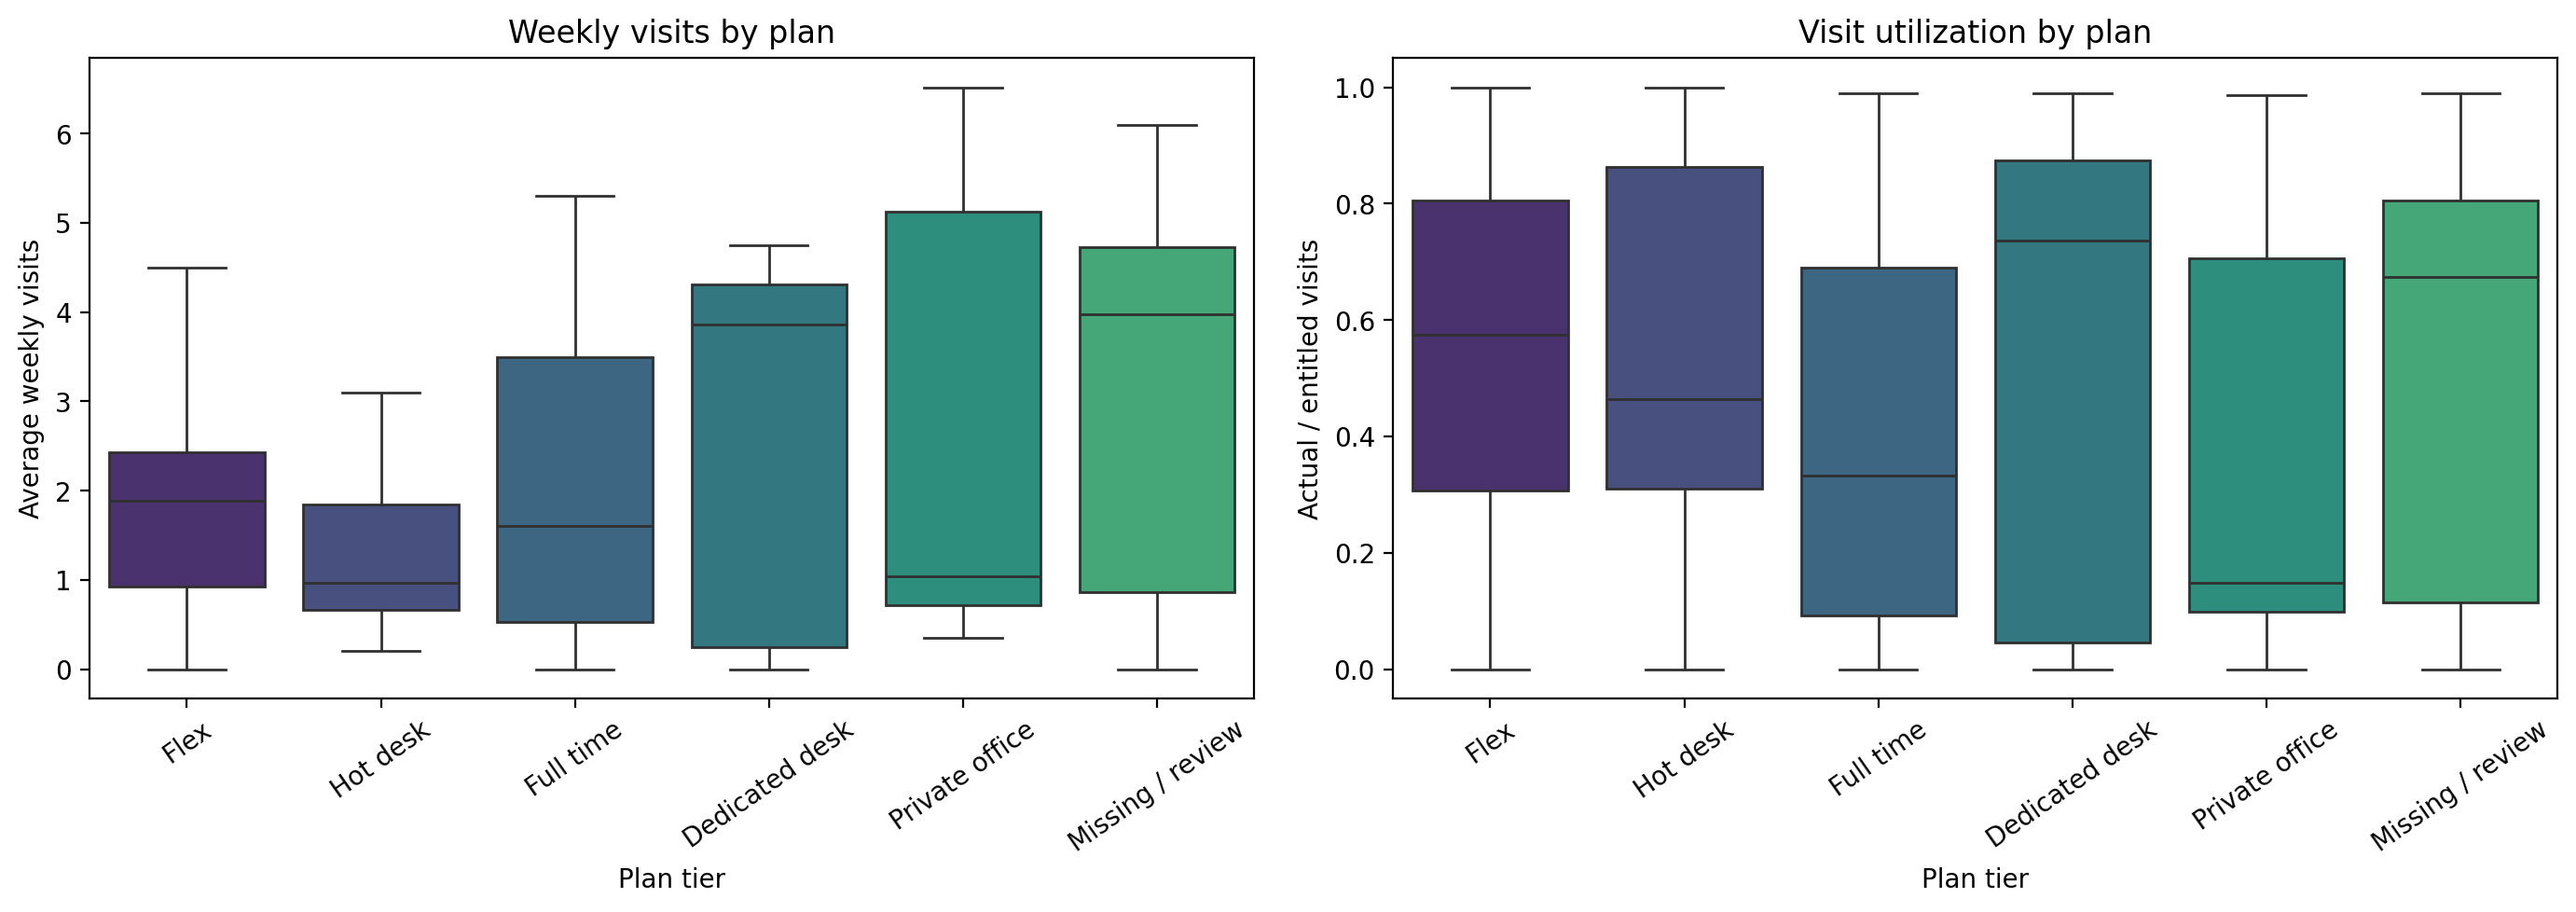

In [24]:
# Normalize spelling/case for this comparison only; preserve the original source values.
plan_key = (cluster_eda["plan_tier"].astype("string").str.strip().str.lower()
            .str.replace(r"[\s_-]+", "", regex=True))
plan_map = {
    "flex": "Flex", "hotdesk": "Hot desk", "fulltime": "Full time",
    "dedicateddesk": "Dedicated desk", "privateoffice": "Private office",
}
cluster_eda["plan_tier_clean"] = plan_key.map(plan_map).fillna("Missing / review")
cluster_eda["visit_utilization"] = (
    cluster_eda["actual_visits_last_period"] /
    cluster_eda["entitled_visits_last_period"].replace(0, np.nan)
)
plan_summary = (cluster_eda.groupby("plan_tier_clean", observed=True)
                .agg(members=("member_id", "size"),
                     weekly_visits_median=("avg_weekly_visits", "median"),
                     utilization_median=("visit_utilization", "median"))
                .sort_values("members", ascending=False))
display(plan_summary.round(2))

plot_plans = plan_summary.index[plan_summary["members"] >= 30]
plot_data = cluster_eda.loc[cluster_eda["plan_tier_clean"].isin(plot_plans)]
plan_order = list(plot_plans)
plan_palette = {
    plan: PALETTE[index % len(PALETTE)]
    for index, plan in enumerate(plan_order)
}
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, measure, title, ylabel in [
    (axes[0], "avg_weekly_visits", "Weekly visits by plan", "Average weekly visits"),
    (axes[1], "visit_utilization", "Visit utilization by plan", "Actual / entitled visits"),
]:
    sns.boxplot(
        data=plot_data,
        x="plan_tier_clean",
        y=measure,
        hue="plan_tier_clean",
        order=plan_order,
        hue_order=plan_order,
        palette=plan_palette,
        legend=False,
        showfliers=False,
        ax=ax,
    )
    ax.set(title=title, xlabel="Plan tier", ylabel=ylabel)
for ax in axes:
    ax.tick_params(axis="x", rotation=35)
plt.tight_layout()
plt.show()


**How to interpret the comparison:** Compare the medians across plans rather than assuming plan causes attendance. Differences in allowance can explain why a member with fewer absolute visits may still use a larger share of their plan. The small `Missing / review` group is not a meaningful plan tier and should not be interpreted as one.

### 8.3 How do attendance and recency relate?

Compare average weekly visits with days since the last visit, retaining only non-negative values for this visualization and correlation. Negative recency values are invalid candidates and are reported separately in the quality review. The plot displays the main concentration (through the 99th percentile of each axis) while the reported correlation uses all valid non-negative records.


The correlation is calculated on valid non-negative records. The hexbin plot displays the central concentration so a small number of extreme values do not hide the main pattern.

Spearman correlation (valid non-negative recency rows, n=15,394): -0.66


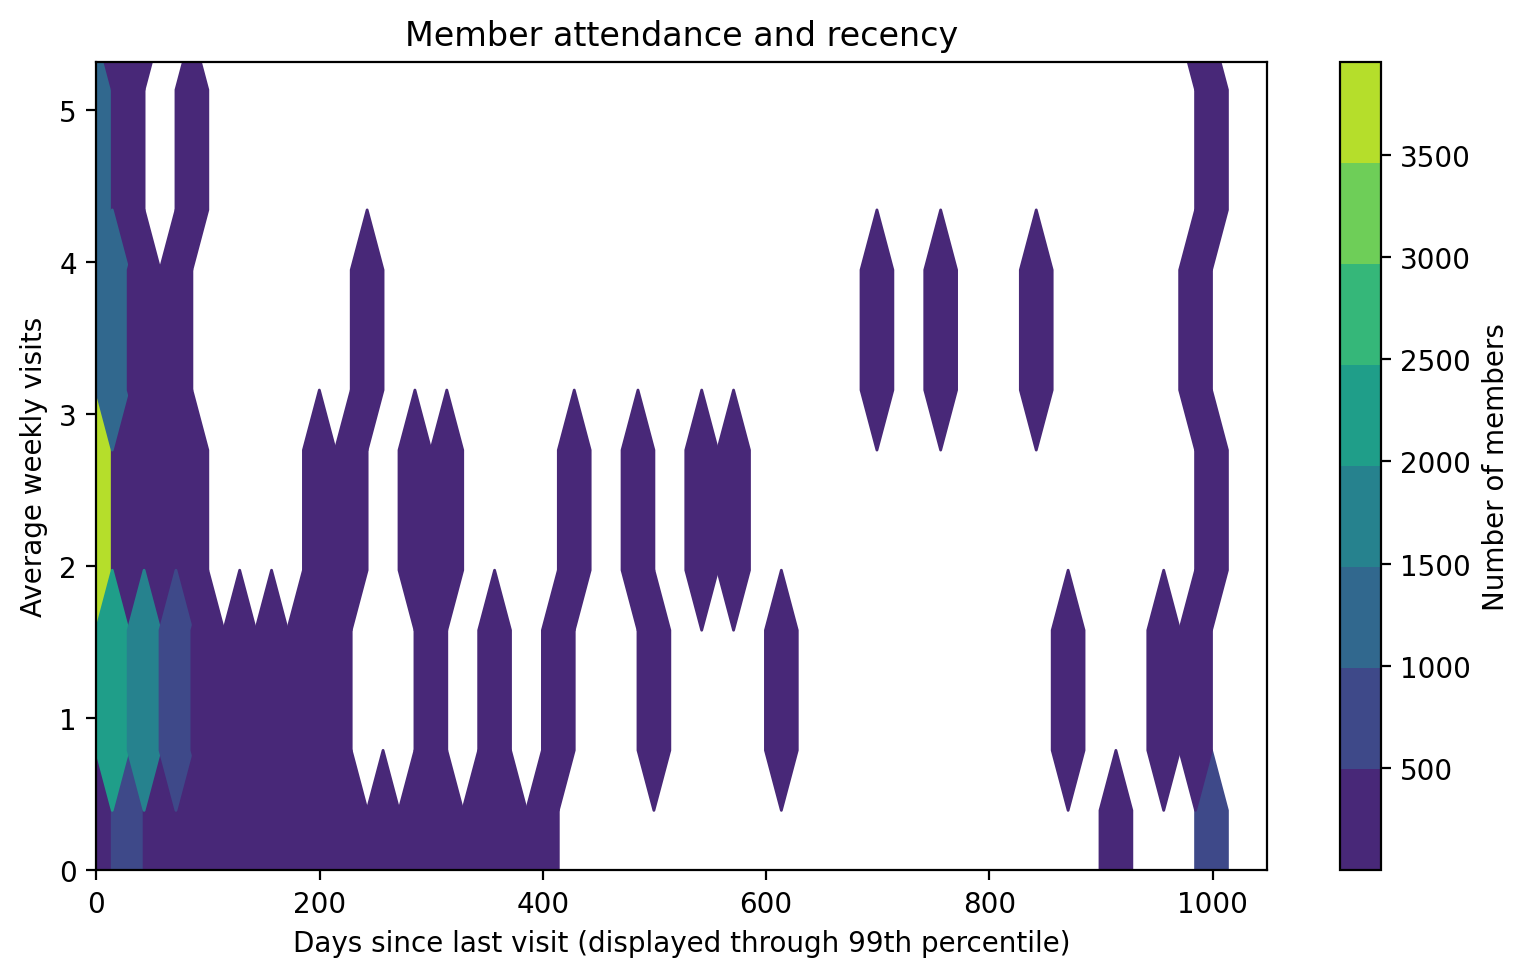

In [25]:
valid_activity = cluster_eda.loc[
    (cluster_eda["days_since_last_visit"] >= 0) &
    (cluster_eda["avg_weekly_visits"] >= 0),
    ["days_since_last_visit", "avg_weekly_visits"],
].dropna()
activity_rho = valid_activity.corr(method="spearman").iloc[0, 1]
print(f"Spearman correlation (valid non-negative recency rows, n={len(valid_activity):,}): {activity_rho:.2f}")

# Limit the displayed axes to the 99th percentile to make the main concentration visible;
# this only changes the view, not the underlying analysis data.
x_limit, y_limit = valid_activity.quantile(0.99)
plot_activity = valid_activity.loc[
    valid_activity["days_since_last_visit"] <= x_limit
].copy()
plt.figure(figsize=(8, 5))
plt.hexbin(plot_activity["days_since_last_visit"], plot_activity["avg_weekly_visits"],
           gridsize=35, mincnt=1, cmap=PALETTE_CMAP)
plt.xlim(left=0)
plt.ylim(bottom=0, top=y_limit)
plt.xlabel("Days since last visit (displayed through 99th percentile)")
plt.ylabel("Average weekly visits")
plt.title("Member attendance and recency")
plt.colorbar(label="Number of members")
plt.tight_layout()
plt.show()


**Finding:** Among 15,394 records with non-negative attendance and recency, Spearman correlation is about -0.66: members with more days since their last visit tend to have lower weekly attendance. The axes are cropped to show the dense central pattern; the underlying correlation is not cropped.

### 8.4 Do service choices distinguish types of engagement?

A total service count is useful but hides which amenities are used. For each optional service, show the number and percentage of members using it and the median attendance/utilization among users. Treat these as descriptive associations, not causal effects. Rare services may be too sparse to be reliable clustering inputs.


For each service, calculate its prevalence and summarize behavior among users. Sort the table and chart from the most commonly used service to the rarest.

,service,members_using,share_using_pct,median_weekly_visits_when_used,median_utilization_when_used
0,meeting_rooms,5258,34.03,1.95,0.62
3,print,4992,32.31,2.11,0.71
5,phone_booths,3990,25.83,1.98,0.69
4,mail_handling,3560,23.04,1.90,0.59
6,day_passes,3394,21.97,1.19,0.46
2,guest_passes,2811,18.19,1.75,0.58
7,storage,2293,14.84,2.53,0.69
1,event_space,1838,11.90,1.38,0.50
8,bike_locker,26,0.17,1.17,0.38


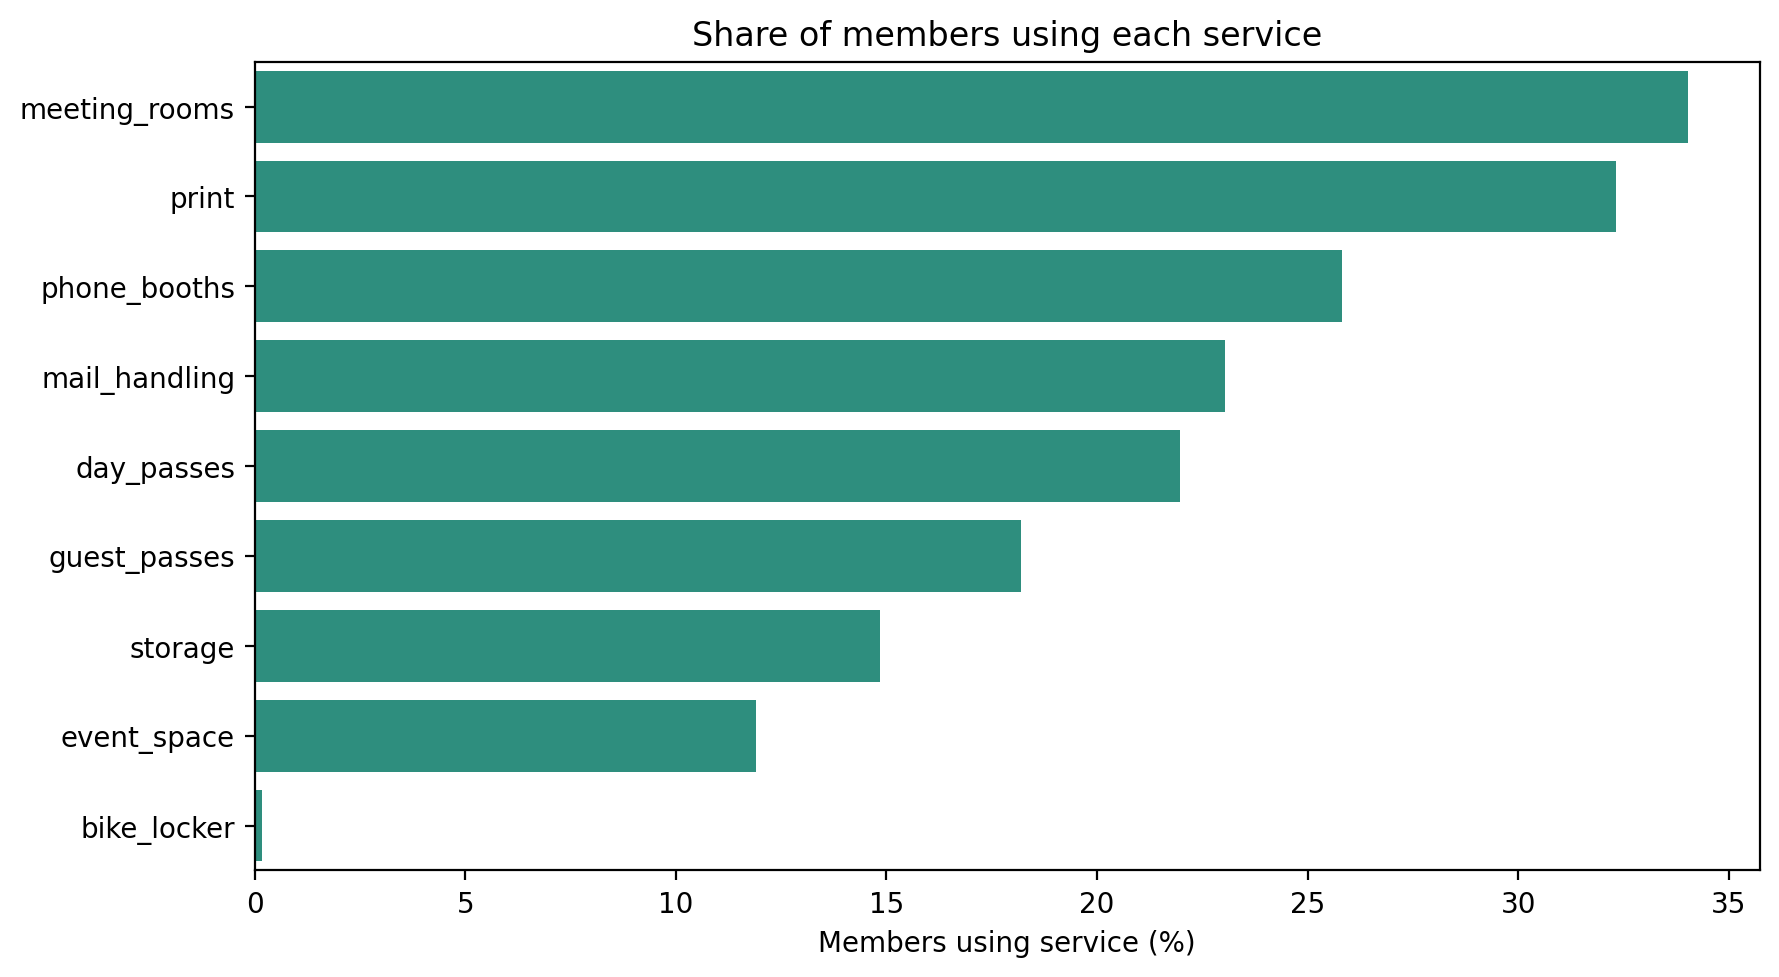

In [26]:
service_cols = [
    "uses_meeting_rooms", "uses_event_space", "uses_guest_passes", "uses_print",
    "uses_mail_handling", "uses_phone_booths", "uses_day_passes", "uses_storage",
    "uses_bike_locker",
]
service_summary = []
for column in service_cols:
    used = cluster_eda[column].fillna(False).astype(bool)
    service_summary.append({
        "service": column.removeprefix("uses_"),
        "members_using": int(used.sum()),
        "share_using_pct": 100 * used.mean(),
        "median_weekly_visits_when_used": cluster_eda.loc[used, "avg_weekly_visits"].median(),
        "median_utilization_when_used": cluster_eda.loc[used, "visit_utilization"].median(),
    })
service_summary = pd.DataFrame(service_summary).sort_values("share_using_pct", ascending=False)
display(service_summary.round(2))

fig, ax = plt.subplots(figsize=(9, 5))
sns.barplot(data=service_summary, x="share_using_pct", y="service", color=PALETTE[4], ax=ax)
ax.set(title="Share of members using each service", xlabel="Members using service (%)", ylabel="")
plt.tight_layout()
plt.show()


**Service-use finding:** Meeting rooms (about 34%) and printing (about 32%) are among the most common services; bike lockers are extremely rare (about 0.2%). The medians describe users only, not non-users, and a rare service may be unsuitable as a standalone clustering feature without further checks.

### 8.5 Is team-oriented use a distinct behavioral dimension?

Compare team and non-team accounts using colleague count, attendance, meeting-room use, and guest-pass use. If account-level attributes are repeated on individual member rows, they may not represent independent member-level behavior; confirm the unit of observation before treating these fields as clustering inputs.


Summarize team and non-team accounts side by side. Medians reduce sensitivity to skewed counts and durations; service-use percentages show prevalence.

In [27]:
team_summary = (cluster_eda.groupby("is_team_account", dropna=False)
                .agg(members=("member_id", "size"),
                     colleagues_median=("n_colleagues_on_account", "median"),
                     weekly_visits_median=("avg_weekly_visits", "median"),
                     meeting_room_hours_median=("meeting_room_hours", "median"),
                     guest_passes_median=("guest_passes_issued", "median"),
                     meeting_room_use_pct=("uses_meeting_rooms", lambda s: 100 * s.astype(bool).mean()),
                     guest_pass_use_pct=("uses_guest_passes", lambda s: 100 * s.astype(bool).mean())))
display(team_summary.round(2))


,members,colleagues_median,weekly_visits_median,meeting_room_hours_median,guest_passes_median,meeting_room_use_pct,guest_pass_use_pct
is_team_account,,,,,,,
False,11100,0.0,1.42,0.0,0.0,33.83,18.22
True,4350,2.0,1.45,0.0,0.0,34.55,18.14


**Team comparison:** Median weekly visits are similar for team and non-team accounts (about 1.45 versus 1.42), while colleague counts differ as expected by the team-account flag. Service-use percentages are also similar in this table. This provides limited evidence that the binary team flag alone separates attendance behavior; verify what one row represents before deciding whether team attributes belong in a model.

### 8.6 Demographics as context, not assumed cluster inputs

Compare median attendance across broad age bands and recorded gender categories to see whether descriptive differences are apparent. Common gender aliases are harmonized for this comparison only, and groups with fewer than 30 records are omitted to avoid over-interpreting very small samples. These associations do not establish causes; age and gender are included as context, not default behavioral inputs.


Standardize common gender labels and bin ages only for this descriptive comparison. Display the table and heatmap for groups large enough to interpret cautiously.

,age_band,gender_clean,members,weekly_visits_median
0,Under 18 (review),Female,56,1.92
1,Under 18 (review),Male,35,1.04
4,18-24,Female,877,1.23
5,18-24,Male,713,1.45
6,18-24,Missing / review,62,1.06
7,18-24,Other,64,1.40
8,25-34,Female,2919,1.44
9,25-34,Male,2453,1.41
10,25-34,Missing / review,200,1.83
11,25-34,Other,180,1.48


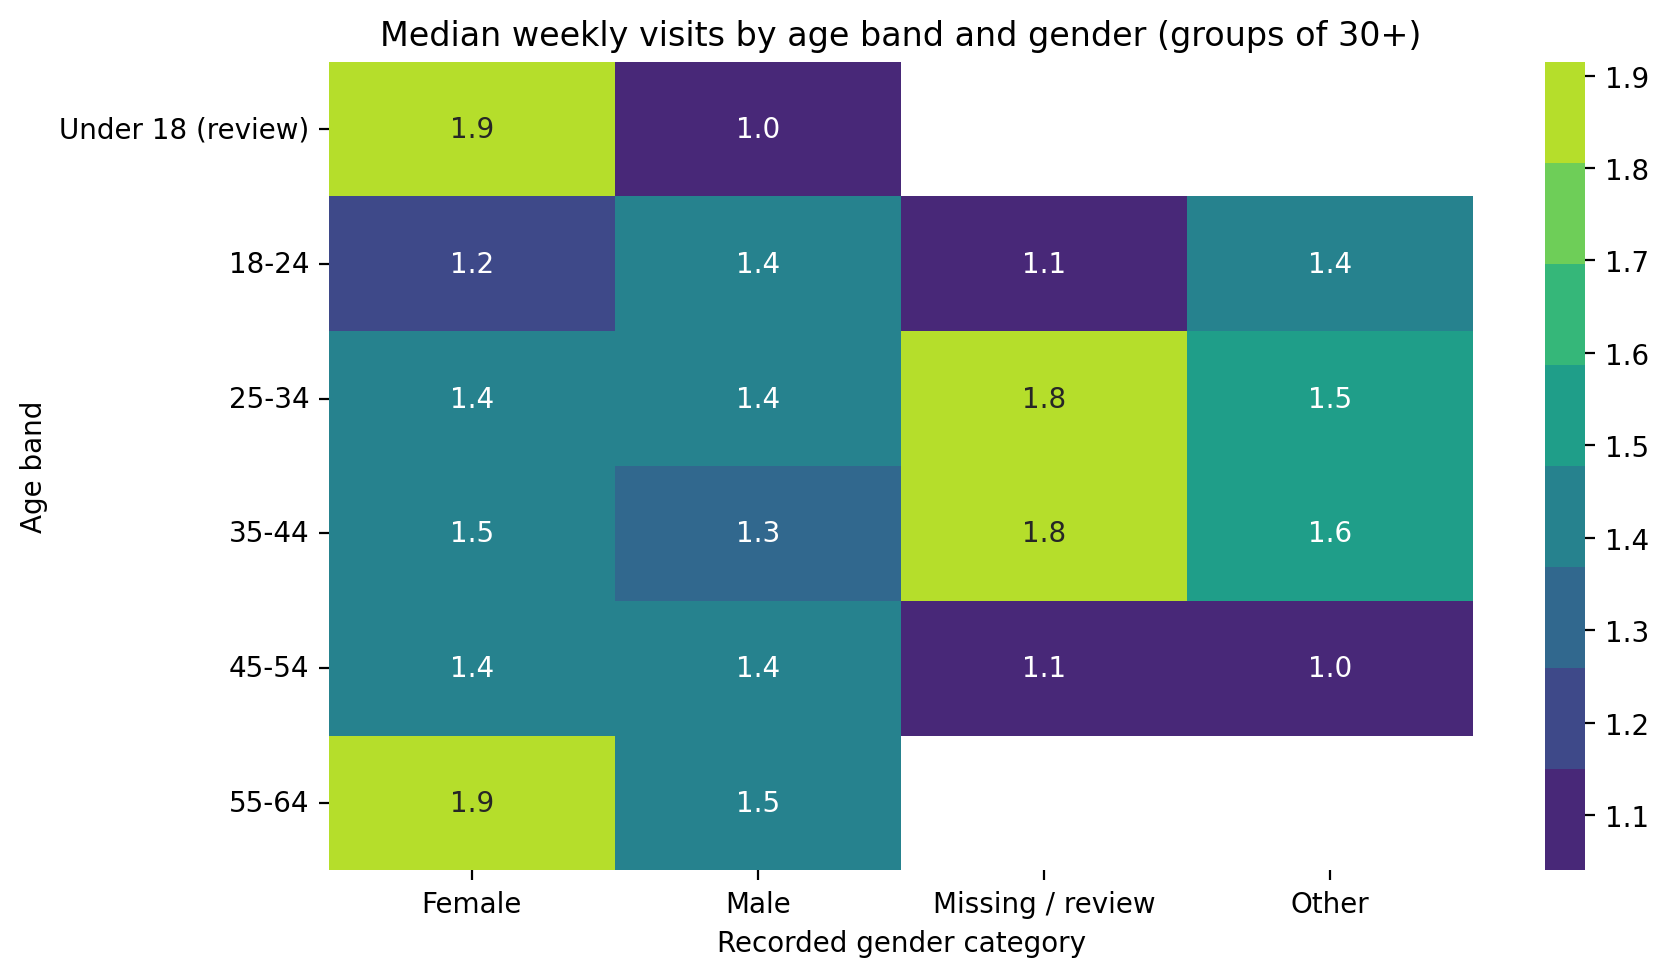

In [28]:
gender_key = cluster_eda["gender"].astype("string").str.strip().str.casefold()
gender_map = {"female": "Female", "f": "Female", "male": "Male", "m": "Male",
              "other": "Other", "o": "Other"}
cluster_eda["gender_clean"] = gender_key.map(gender_map).fillna("Missing / review")
cluster_eda["age_band"] = pd.cut(
    cluster_eda["age"], bins=[-np.inf, 17, 24, 34, 44, 54, 64, 100, np.inf],
    labels=["Under 18 (review)", "18-24", "25-34", "35-44", "45-54", "55-64", "65-100", "Over 100 (review)"],
)
demo_counts = (cluster_eda.groupby(["age_band", "gender_clean"], observed=True)
               .agg(members=("member_id", "size"),
                    weekly_visits_median=("avg_weekly_visits", "median"))
               .reset_index())
display(demo_counts.loc[demo_counts["members"] >= 30].round(2))
demo_plot = demo_counts.loc[demo_counts["members"] >= 30].pivot(
    index="age_band", columns="gender_clean", values="weekly_visits_median")
if not demo_plot.empty:
    plt.figure(figsize=(9, 5))
    sns.heatmap(demo_plot, annot=True, fmt=".1f", cmap=PALETTE_CMAP)
    plt.title("Median weekly visits by age band and gender (groups of 30+)")
    plt.xlabel("Recorded gender category")
    plt.ylabel("Age band")
    plt.tight_layout()
    plt.show()


**Demographic comparison:** The table and heatmap report median weekly visits only for age/gender groups with at least 30 records. Group medians are broadly similar, so these variables do not show a strong simple attendance split here. This is descriptive context, not evidence of no demographic relationship or a reason to use sensitive attributes as clustering inputs.

### 8.7 Membership dates, tenure, and cumulative measures

Membership dates help interpret total visits, renewals, and lifetime value: members with longer membership have had more opportunity to accumulate these totals. The dataset uses `1970-01-01` as a sentinel for active memberships. Current tenure should not be calculated from today's date unless the dataset's observation date is known. The date audit below reuses the originally parsed dates, preserves the raw-format audit, and excludes active sentinels when checking impossible end-before-start records.


In [29]:
date_cols = ["membership_start", "membership_end", "last_badge_swipe"]
# Align the parsed raw dates with the deduplicated analysis copy.
parsed_dates = parsed_dates.loc[cluster_eda.index, date_cols].copy()
for column in date_cols:
    cluster_eda[f"{column}_iso"] = parsed_dates[column].dt.strftime("%Y-%m-%d")

display(pd.DataFrame(date_format_audit).set_index("column"))
print("Normalized date examples:")
display(cluster_eda[[f"{column}_iso" for column in date_cols]].head())
date_summary = pd.DataFrame({
    "parsed_values": parsed_dates.notna().sum(),
    "missing_or_unparsed": parsed_dates.isna().sum(),
    "earliest": parsed_dates.min(),
    "latest": parsed_dates.max(),
})
display(date_summary)
active_end_sentinel = pd.Timestamp("1970-01-01")
real_end_dates = parsed_dates["membership_end"].notna() & parsed_dates["membership_end"].ne(active_end_sentinel)
start_dates_present = parsed_dates["membership_start"].notna()
end_before_start = (
    real_end_dates & start_dates_present
    & parsed_dates["membership_end"].lt(parsed_dates["membership_start"])
)
print(f"Active-member sentinel dates: {int(parsed_dates['membership_end'].eq(active_end_sentinel).sum()):,}")
print(f"Real end dates before membership start: {int(end_before_start.sum()):,}")


,ISO dates,day-first dates,unsupported or missing,invalid calendar dates
column,,,,
membership_start,14826,639,0,0
membership_end,15002,463,0,0
last_badge_swipe,14826,639,0,0


Normalized date examples:


,membership_start_iso,membership_end_iso,last_badge_swipe_iso
0,2021-08-01,2023-03-06,2023-03-23
1,2023-11-24,1970-01-01,2023-11-24
2,2021-12-03,1970-01-01,2023-07-22
3,2022-01-02,2022-02-15,2022-01-02
4,2023-10-24,1970-01-01,2023-12-17


,parsed_values,missing_or_unparsed,earliest,latest
membership_start,15450,0,2021-01-01,2023-12-30
membership_end,15450,0,1970-01-01,2024-01-01
last_badge_swipe,15450,0,2020-09-06,2024-04-28


Active-member sentinel dates: 3,954
Real end dates before membership start: 152


**Date-quality findings:** The original raw-format audit is retained from the first parsing step. After excluding exact duplicate rows, 3,954 records have the active-member sentinel. Among records with real end dates, 152 end dates precede their membership start and require validation. These records must not be used as completed tenure without review. Badge-swipe dates extend beyond 2024-01-01, which also limits snapshot-based tenure calculations.


### 8.8 Standardize categories for interpretation

Raw country and industry labels contain spelling, case, abbreviation, and missing-value variants. Normalize only clear aliases in the analysis copy so that category summaries are interpretable; keep the source columns unchanged. Rare or uncertain labels are not forced into a guessed category. These fields are mainly for describing the customer mix and profiling clusters after they are built.


Normalize clear country and industry aliases in the analysis copy. The source fields are not overwritten; a count table and top-category plots show the resulting member mix.


country (top categories after clear alias mapping):


,members
country_clean,
Portugal,10499
United Kingdom,1165
Germany,901
Spain,741
France,533
Netherlands,487
Other (Europe),451
Missing,429
Ireland,244



industry (top categories after clear alias mapping):


,members
industry_clean,
Information Technology,3557
Consulting,2055
Design & Creative,1974
Marketing & PR,1962
Finance,1219
Other,1175
Legal,878
Education,775
Unknown,693


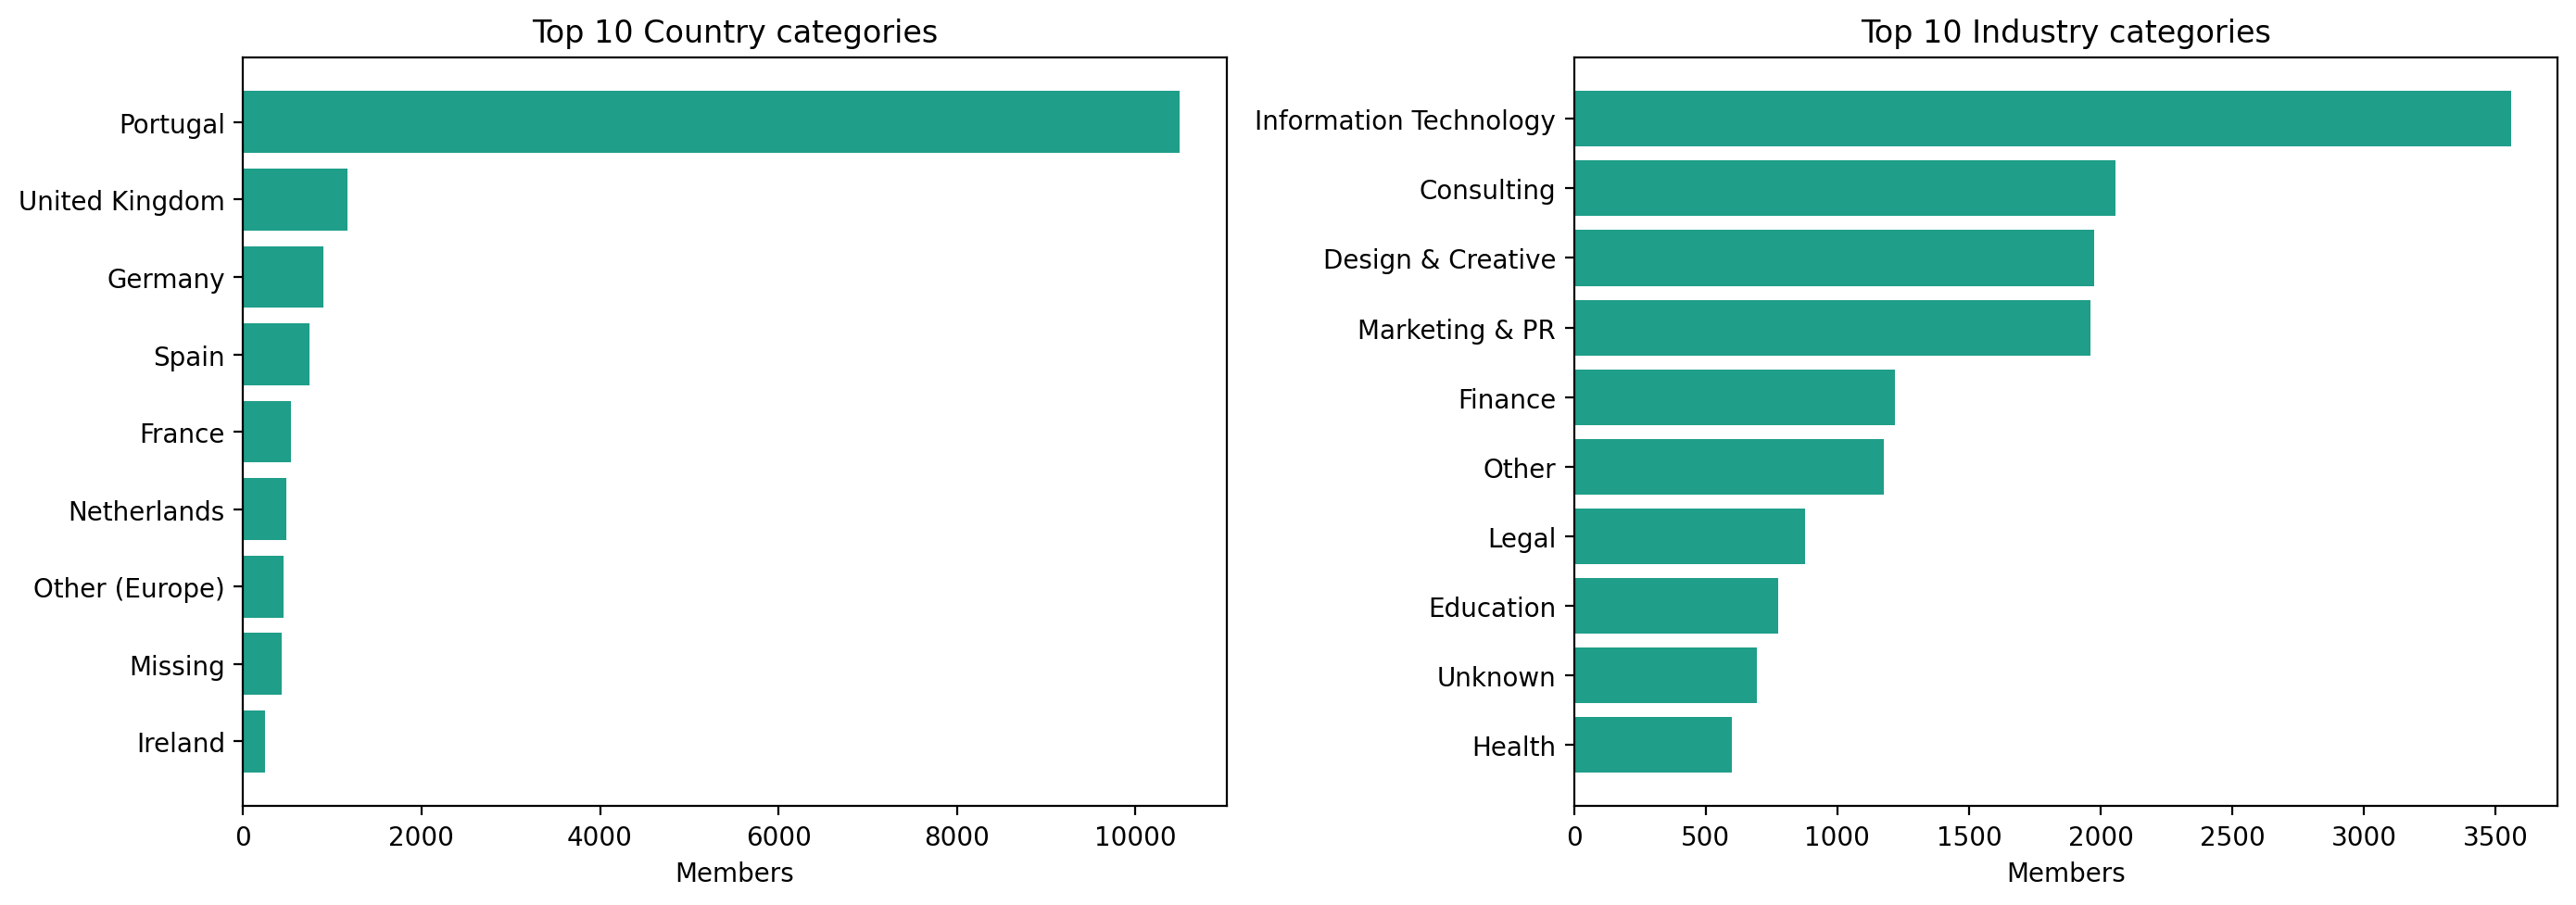

In [30]:
import re
import unicodedata

def category_key(value):
    if pd.isna(value):
        return None
    text = unicodedata.normalize("NFKD", str(value)).encode("ascii", "ignore").decode("ascii")
    return re.sub(r"[^a-z0-9]+", " ", text.casefold()).strip()

country_aliases = {
    "portugal": "Portugal", "portucal": "Portugal", "pt": "Portugal",
    "united kingdom": "United Kingdom", "uk": "United Kingdom", "u k": "United Kingdom", "gb": "United Kingdom",
    "germany": "Germany", "deutschland": "Germany", "de": "Germany",
    "netherlands": "Netherlands", "the netherlands": "Netherlands", "holland": "Netherlands", "nl": "Netherlands",
    "spain": "Spain", "espana": "Spain", "espa a": "Spain", "es": "Spain",
    "france": "France", "fr": "France", "ireland": "Ireland", "ie": "Ireland",
    "other europe": "Other (Europe)",
}
industry_aliases = {
    "information technology": "Information Technology", "it": "Information Technology", "tech": "Information Technology",
    "design creative": "Design & Creative", "design and creative": "Design & Creative",
    "consulting": "Consulting", "finance": "Finance", "marketing pr": "Marketing & PR",
    "marketing and pr": "Marketing & PR", "legal": "Legal", "education": "Education", "health": "Health",
    "real estate": "Real Estate", "realestate": "Real Estate", "other": "Other", "unknown": "Unknown",
}
for source_col, output_col, aliases in [
    ("country", "country_clean", country_aliases),
    ("industry", "industry_clean", industry_aliases),
]:
    keys = cluster_eda[source_col].map(category_key)
    cluster_eda[output_col] = keys.map(aliases).fillna(keys.str.title()).fillna("Missing")
    counts = cluster_eda[output_col].value_counts(dropna=False).head(12)
    print(f"\n{source_col} (top categories after clear alias mapping):")
    display(counts.rename("members").to_frame())

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, column, title in zip(axes, ["country_clean", "industry_clean"], ["Country", "Industry"]):
    counts = cluster_eda[column].value_counts().head(10).sort_values()
    ax.barh(counts.index, counts.values, color=PALETTE[4])
    ax.set(title=f"Top 10 {title} categories", xlabel="Members", ylabel="")
plt.tight_layout()
plt.show()


**Category cleanup result:** Portugal is the largest country group, and Information Technology is the largest industry group after clear aliases are combined. The source columns remain unchanged. `Unknown` and `Missing` remain explicit because they do not identify a reliable category.

### 8.9 Renewals, engagement, and membership duration

Compare renewal counts with weekly attendance, visit utilization, and completed membership duration. Negative renewal counts are excluded. The tenure comparison includes only ended memberships with valid dates; active-member sentinels are excluded. Longer memberships naturally allow more renewals, so interpret the correlation as descriptive rather than causal.


Compare the 0, 1, and 2+ renewal bands for engagement and for completed tenure. Report group sizes alongside medians, and calculate rank correlations to summarize the strength of the associations.

In [31]:
renewal_data = cluster_eda.loc[cluster_eda["n_renewals"].ge(0)].copy()
renewal_data["visit_utilization"] = (
    renewal_data["actual_visits_last_period"] /
    renewal_data["entitled_visits_last_period"].replace(0, np.nan)
)
renewal_data["renewal_band"] = pd.cut(
    renewal_data["n_renewals"],
    bins=[-0.5, 0.5, 1.5, np.inf],
    labels=["0", "1", "2+"],
)

engagement_by_renewal = renewal_data.groupby("renewal_band", observed=False).agg(
    members=("member_id", "size"),
    median_weekly_visits=("avg_weekly_visits", "median"),
    median_visit_utilization=("visit_utilization", "median"),
)

tenure_valid = (
    parsed_dates["membership_start"].notna()
    & parsed_dates["membership_end"].notna()
    & parsed_dates["membership_end"].ne(pd.Timestamp("1970-01-01"))
    & parsed_dates["membership_end"].ge(parsed_dates["membership_start"])
    & cluster_eda["n_renewals"].ge(0)
)
renewal_tenure = cluster_eda.loc[tenure_valid, ["member_id", "n_renewals"]].copy()
renewal_tenure["tenure_years"] = (
    parsed_dates.loc[tenure_valid, "membership_end"]
    - parsed_dates.loc[tenure_valid, "membership_start"]
).dt.days / 365.25
renewal_tenure["renewal_band"] = pd.cut(
    renewal_tenure["n_renewals"],
    bins=[-0.5, 0.5, 1.5, np.inf],
    labels=["0", "1", "2+"],
)
tenure_by_renewal = renewal_tenure.groupby("renewal_band", observed=False).agg(
    ended_members=("member_id", "size"),
    median_tenure_years=("tenure_years", "median"),
)

print(f"Negative renewal records excluded: {(cluster_eda['n_renewals'] < 0).sum():,}")
print(f"Valid ended memberships in tenure comparison: {len(renewal_tenure):,}")
print(f"Active memberships excluded from tenure comparison: {int(parsed_dates['membership_end'].eq(pd.Timestamp('1970-01-01')).sum()):,}")
print("Median visits and utilization by renewal count:")
display(engagement_by_renewal.round(2))
print("Median completed tenure by renewal count (ended members only):")
display(tenure_by_renewal.round(2))
print("Spearman correlations:")
display(pd.Series({
    "renewals vs. weekly visits": renewal_data[["n_renewals", "avg_weekly_visits"]].corr(method="spearman").iloc[0, 1],
    "renewals vs. visit utilization": renewal_data[["n_renewals", "visit_utilization"]].corr(method="spearman").iloc[0, 1],
    "renewals vs. completed tenure (ended members)": renewal_tenure[["n_renewals", "tenure_years"]].corr(method="spearman").iloc[0, 1],
}).round(2).rename("Spearman correlation"))

Negative renewal records excluded: 66
Valid ended memberships in tenure comparison: 11,293
Active memberships excluded from tenure comparison: 3,954
Median visits and utilization by renewal count:


,members,median_weekly_visits,median_visit_utilization
renewal_band,,,
0,7742,0.99,0.40
1,3289,1.96,0.71
2+,4353,2.02,0.69


Median completed tenure by renewal count (ended members only):


,ended_members,median_tenure_years
renewal_band,,
0,6470,0.20
1,2353,1.19
2+,2470,1.58


Spearman correlations:


renewals vs. weekly visits                       0.26
renewals vs. visit utilization                   0.14
renewals vs. completed tenure (ended members)    0.64
Name: Spearman correlation, dtype: float64

**Finding:** renewal count is moderately associated with completed tenure (Spearman correlation about 0.64), but only weakly-to-modestly associated with weekly visits (0.26) and visit utilization (0.14). The result is expected in part because longer memberships create more opportunities to renew, and active members are not included in the tenure comparison. For clustering, treat renewal count as membership-history context and test its redundancy with tenure rather than automatically including both.


### 8.10 Do industry and country relate to member behavior?

Compare service mix across industries and average weekly attendance across standardized industry and country groups. These are exploratory descriptions, not evidence that industry or country causes behavior. Groups with fewer than 30 members are omitted from attendance plots to avoid unstable visual comparisons; the profile table reports group sizes.


Convert each service indicator to a within-industry percentage and display a heatmap. Industries with fewer than 30 members are excluded from this comparison to reduce the influence of very small groups.

,members,meeting rooms,event space,guest passes,print,mail handling,phone booths,day passes,storage,bike locker
industry_clean,,,,,,,,,,
Information Technology,3557,32.9,10.8,16.5,33.7,24.4,27.1,20.6,16.5,0.2
Consulting,2055,38.5,13.2,20.0,35.5,30.7,28.6,21.4,19.3,0.0
Design & Creative,1974,28.8,12.1,15.9,33.2,13.0,22.8,24.1,8.1,0.3
Marketing & PR,1962,38.8,15.4,22.4,30.9,18.3,24.6,24.3,11.8,0.1
Finance,1219,37.1,11.1,20.9,33.9,36.1,28.2,18.3,22.6,0.1
Other,1175,28.1,11.0,17.1,27.0,16.4,21.4,24.6,11.7,0.2
Legal,878,35.3,10.9,18.2,36.9,30.8,28.1,20.0,20.6,0.0
Education,775,30.7,10.1,14.7,24.6,15.6,25.4,24.3,9.4,0.0
Unknown,693,31.5,9.8,18.6,30.3,23.7,24.8,23.2,11.7,1.0


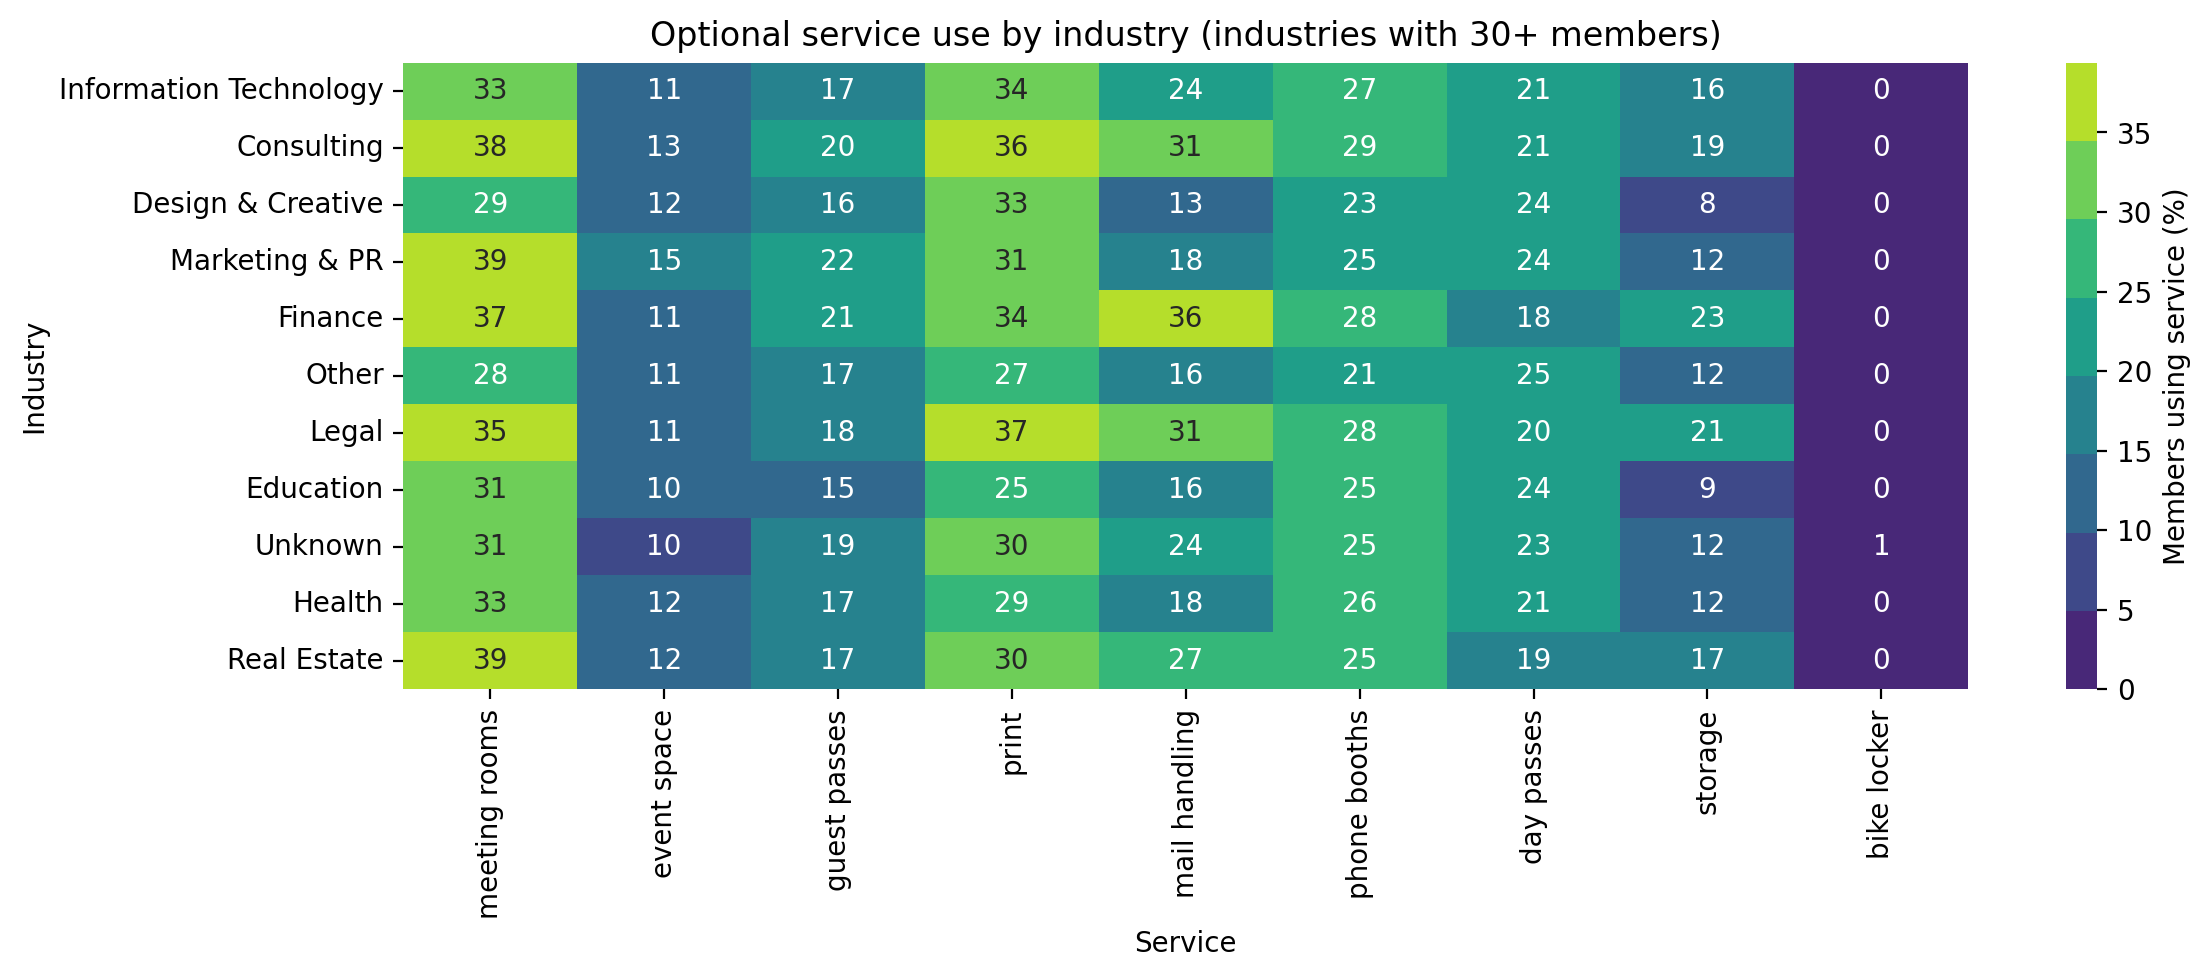

In [32]:
service_cols = [
    "uses_meeting_rooms", "uses_event_space", "uses_guest_passes", "uses_print",
    "uses_mail_handling", "uses_phone_booths", "uses_day_passes", "uses_storage",
    "uses_bike_locker",
]
industry_service_data = cluster_eda[["industry_clean", *service_cols]].copy()
industry_service_data[service_cols] = industry_service_data[service_cols].astype(float)
industry_service_counts = industry_service_data.groupby("industry_clean", dropna=False).size()
eligible_industries = industry_service_counts[industry_service_counts >= 30].index
industry_service_data = industry_service_data.loc[
    industry_service_data["industry_clean"].isin(eligible_industries)
]
industry_service_rates = (
    industry_service_data.groupby("industry_clean", dropna=False)[service_cols]
    .mean()
    .mul(100)
)
industry_service_rates.columns = [column.removeprefix("uses_").replace("_", " ") for column in service_cols]
industry_service_rates.insert(
    0, "members", industry_service_data.groupby("industry_clean", dropna=False).size()
)
industry_service_rates = industry_service_rates.sort_values("members", ascending=False)
display(industry_service_rates.round(1))

heatmap_data = industry_service_rates.drop(columns="members")
plt.figure(figsize=(12, max(5, 0.38 * len(heatmap_data))))
sns.heatmap(heatmap_data, annot=True, fmt=".0f", cmap=PALETTE_CMAP, cbar_kws={"label": "Members using service (%)"})
plt.title("Optional service use by industry (industries with 30+ members)")
plt.xlabel("Service")
plt.ylabel("Industry")
plt.tight_layout()
plt.show()

**Industry comparison:** The heatmap reports the percentage using each service within an industry. It helps identify possible differences in service mix, but these percentages are descriptive and may reflect group size or other factors. Use only as a cluster-profiling consideration, not as evidence of causal preference.

Show the distribution of average weekly visits by country and industry, then compare the country or industry breakdown within each standardized plan tier using horizontal 100% stacked bars. Each bar sums to 100% within a plan tier, matching the original comparison in `03_eda`. Weekly visits are used here rather than plotting both weekly and recent-period attendance, which are already strongly correlated. Outlier markers are hidden in the boxplots for readability, not removed from the analysis.


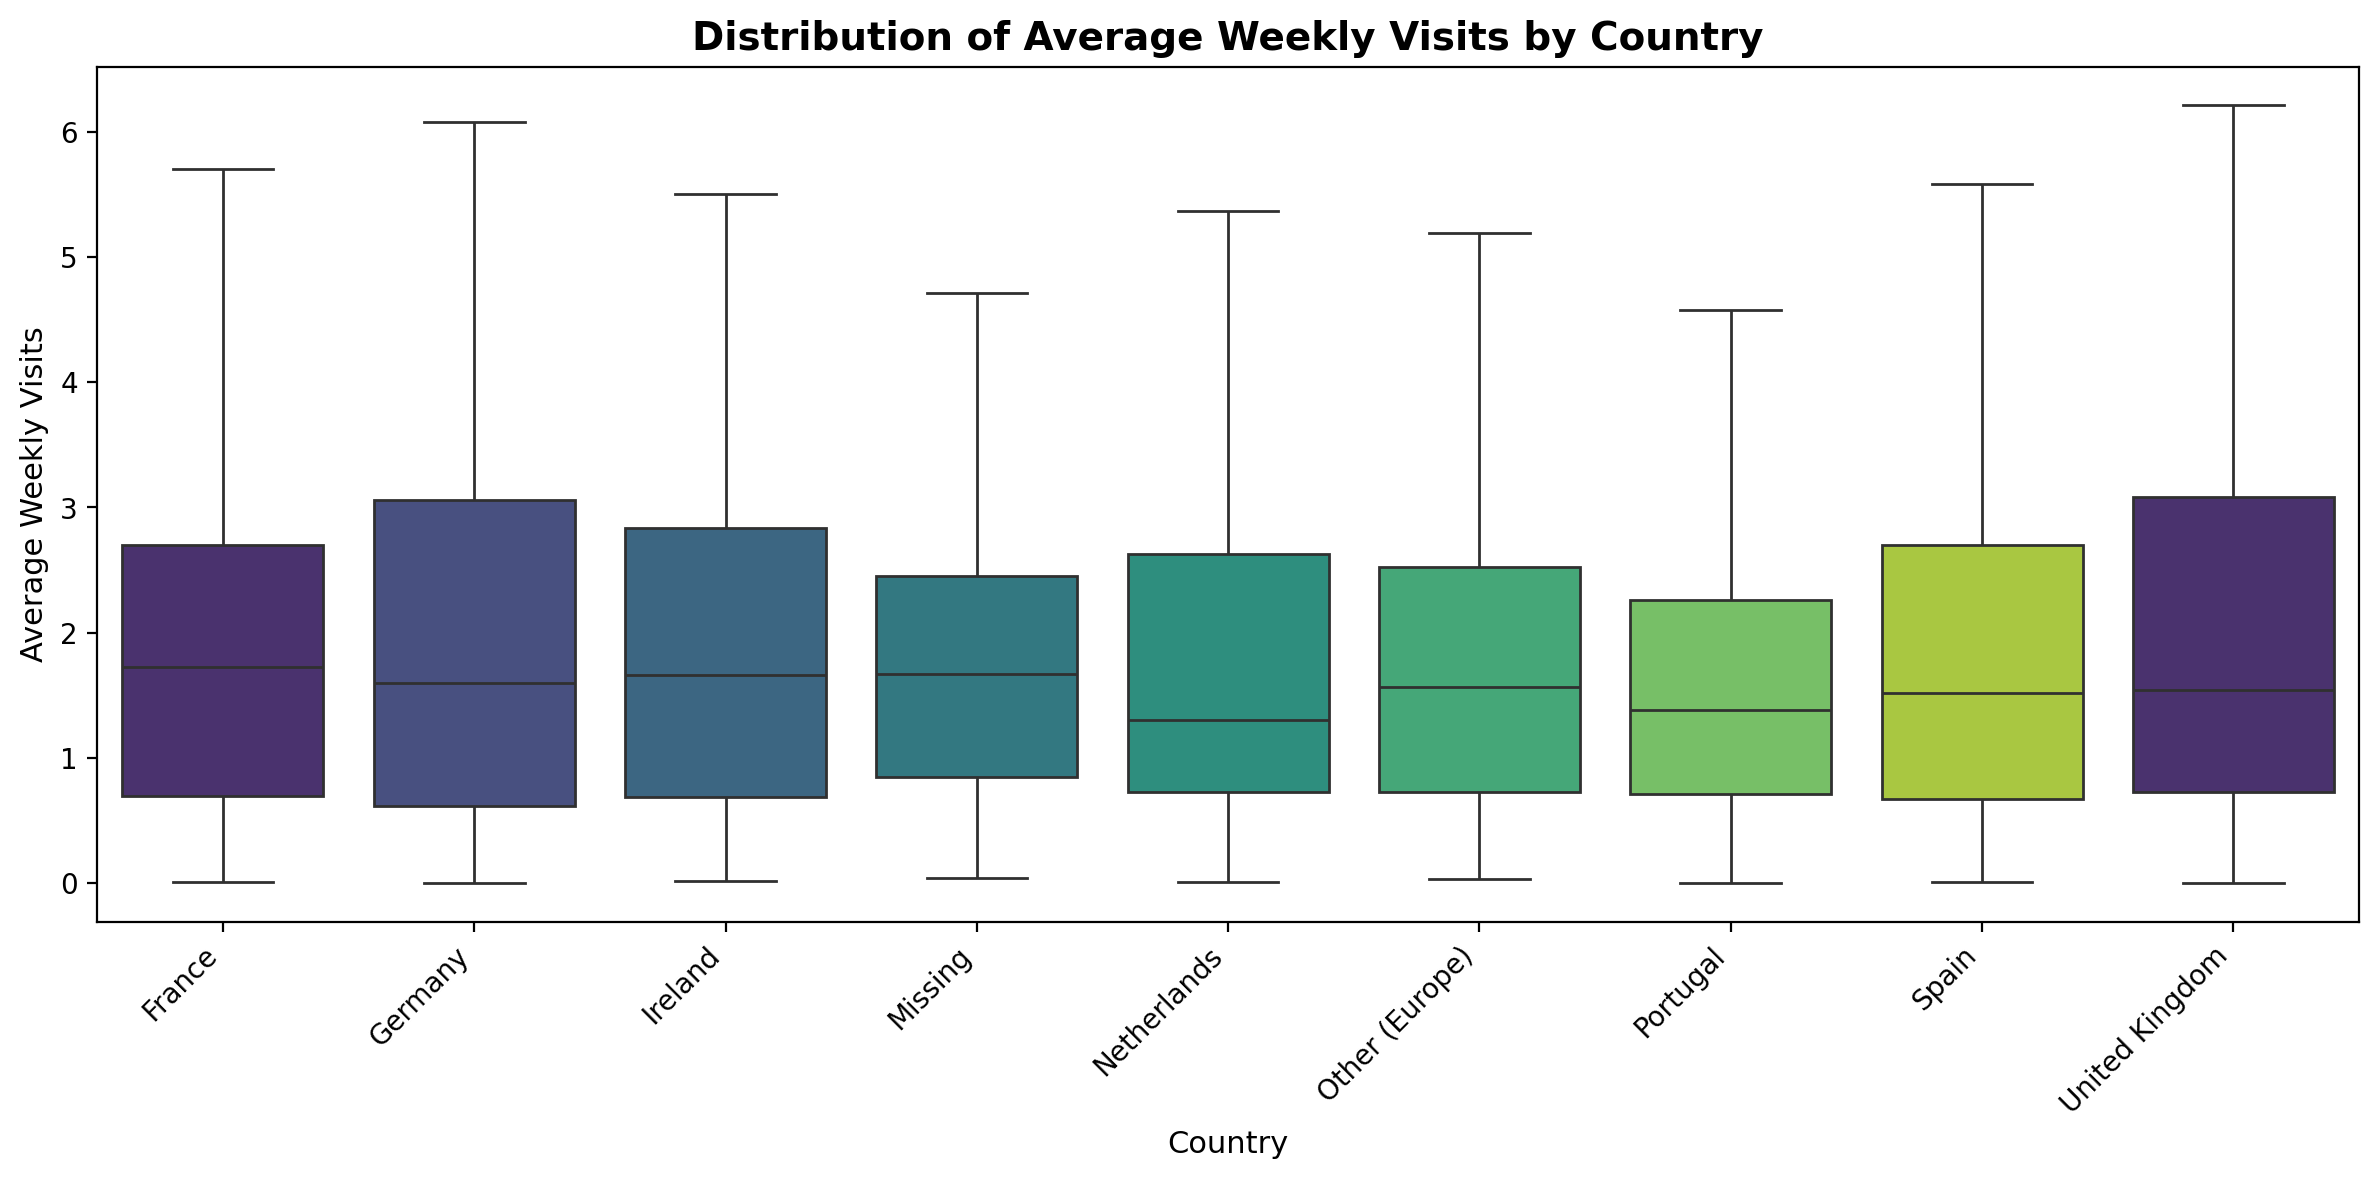

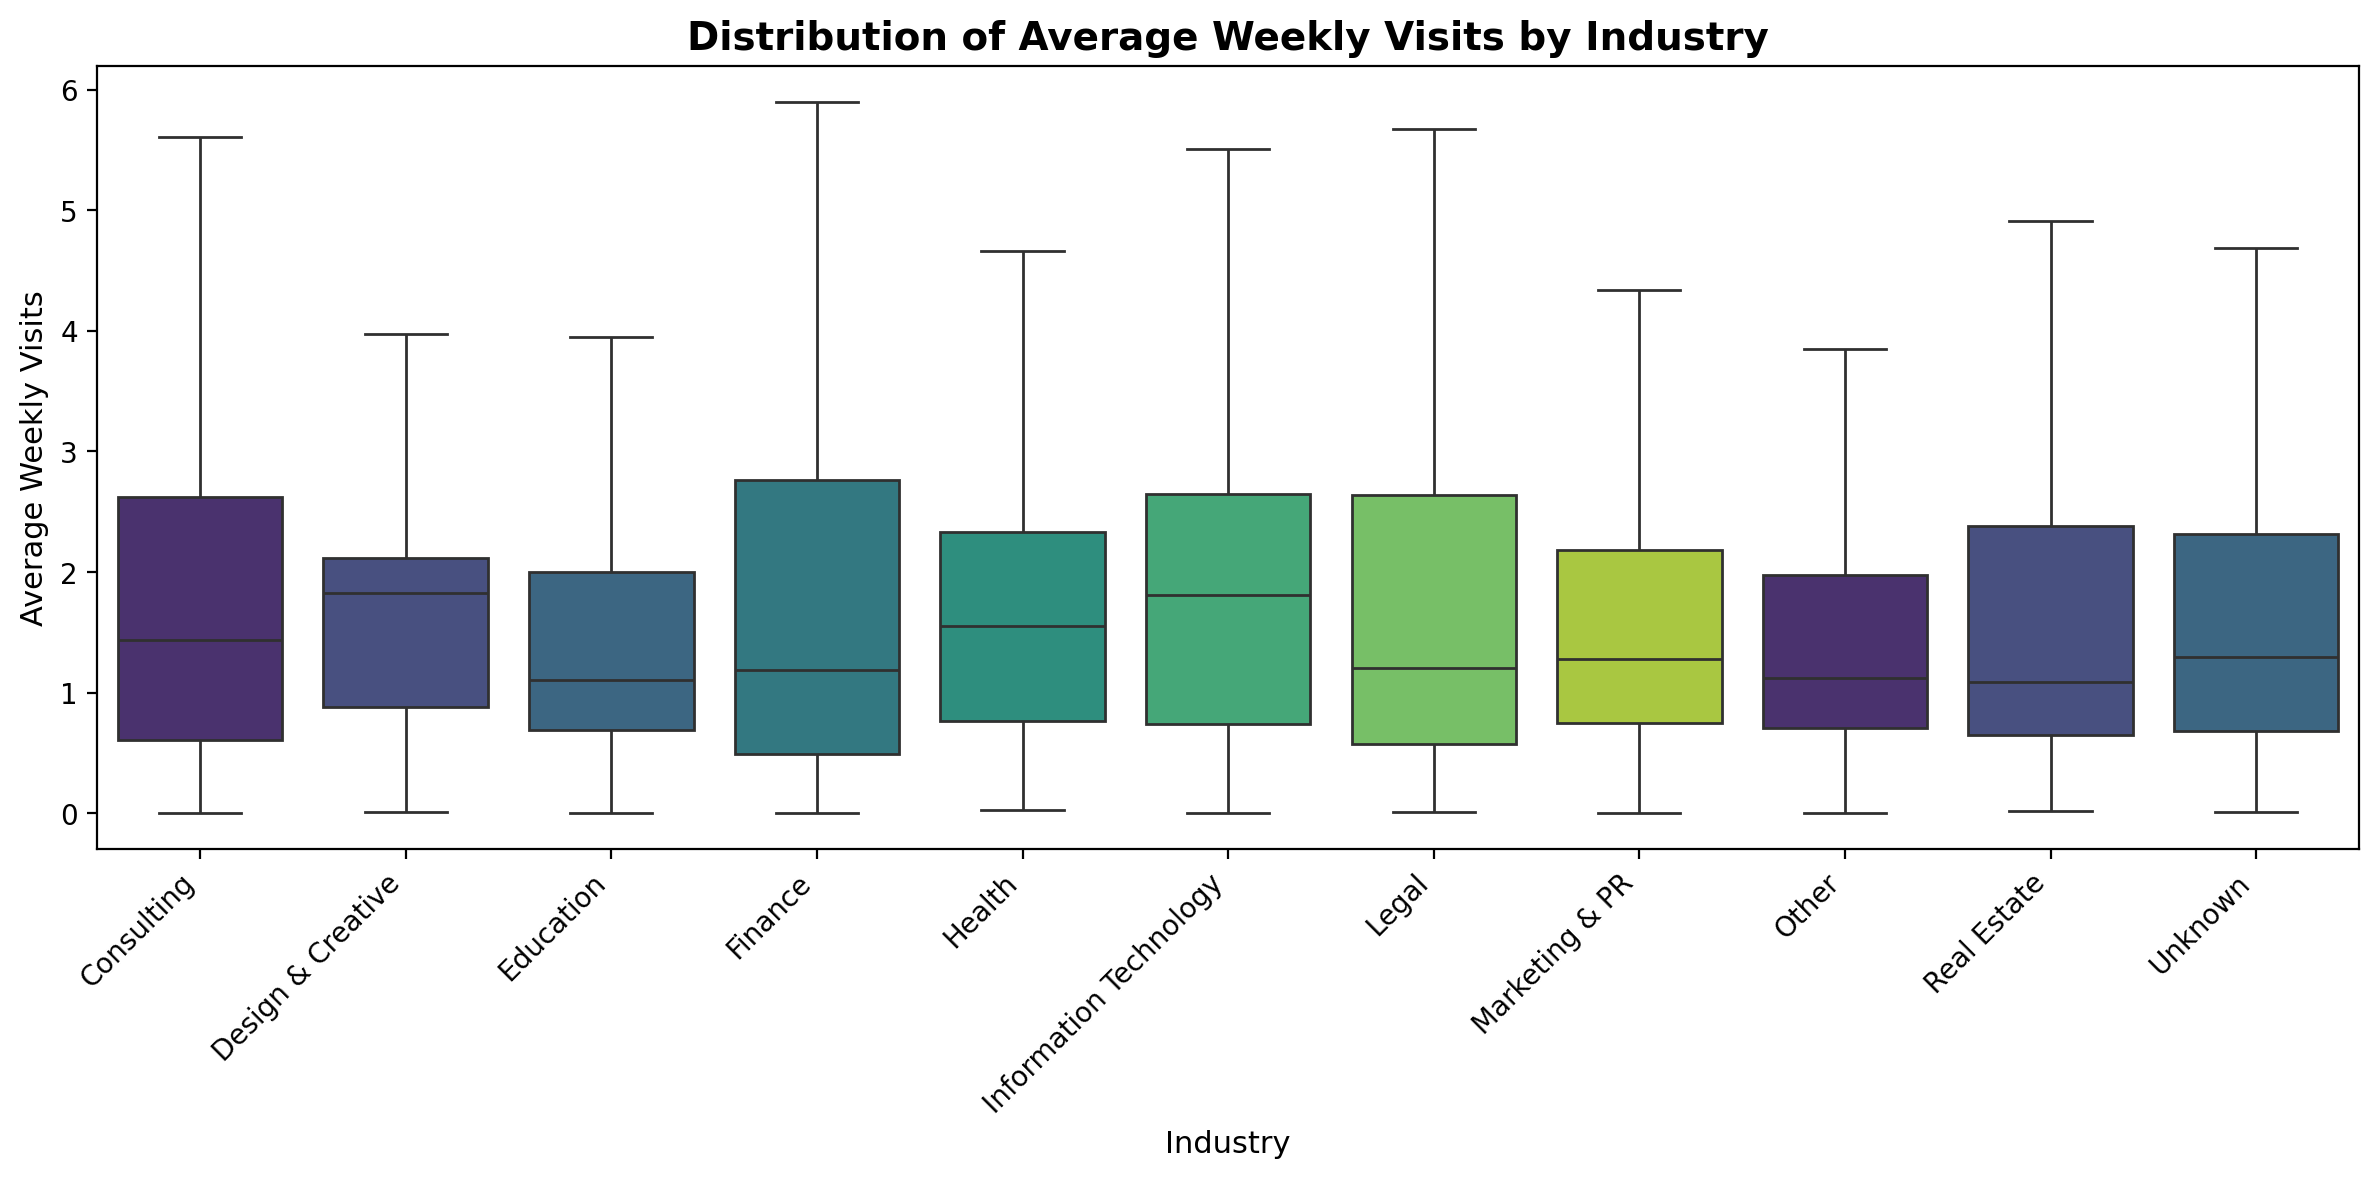

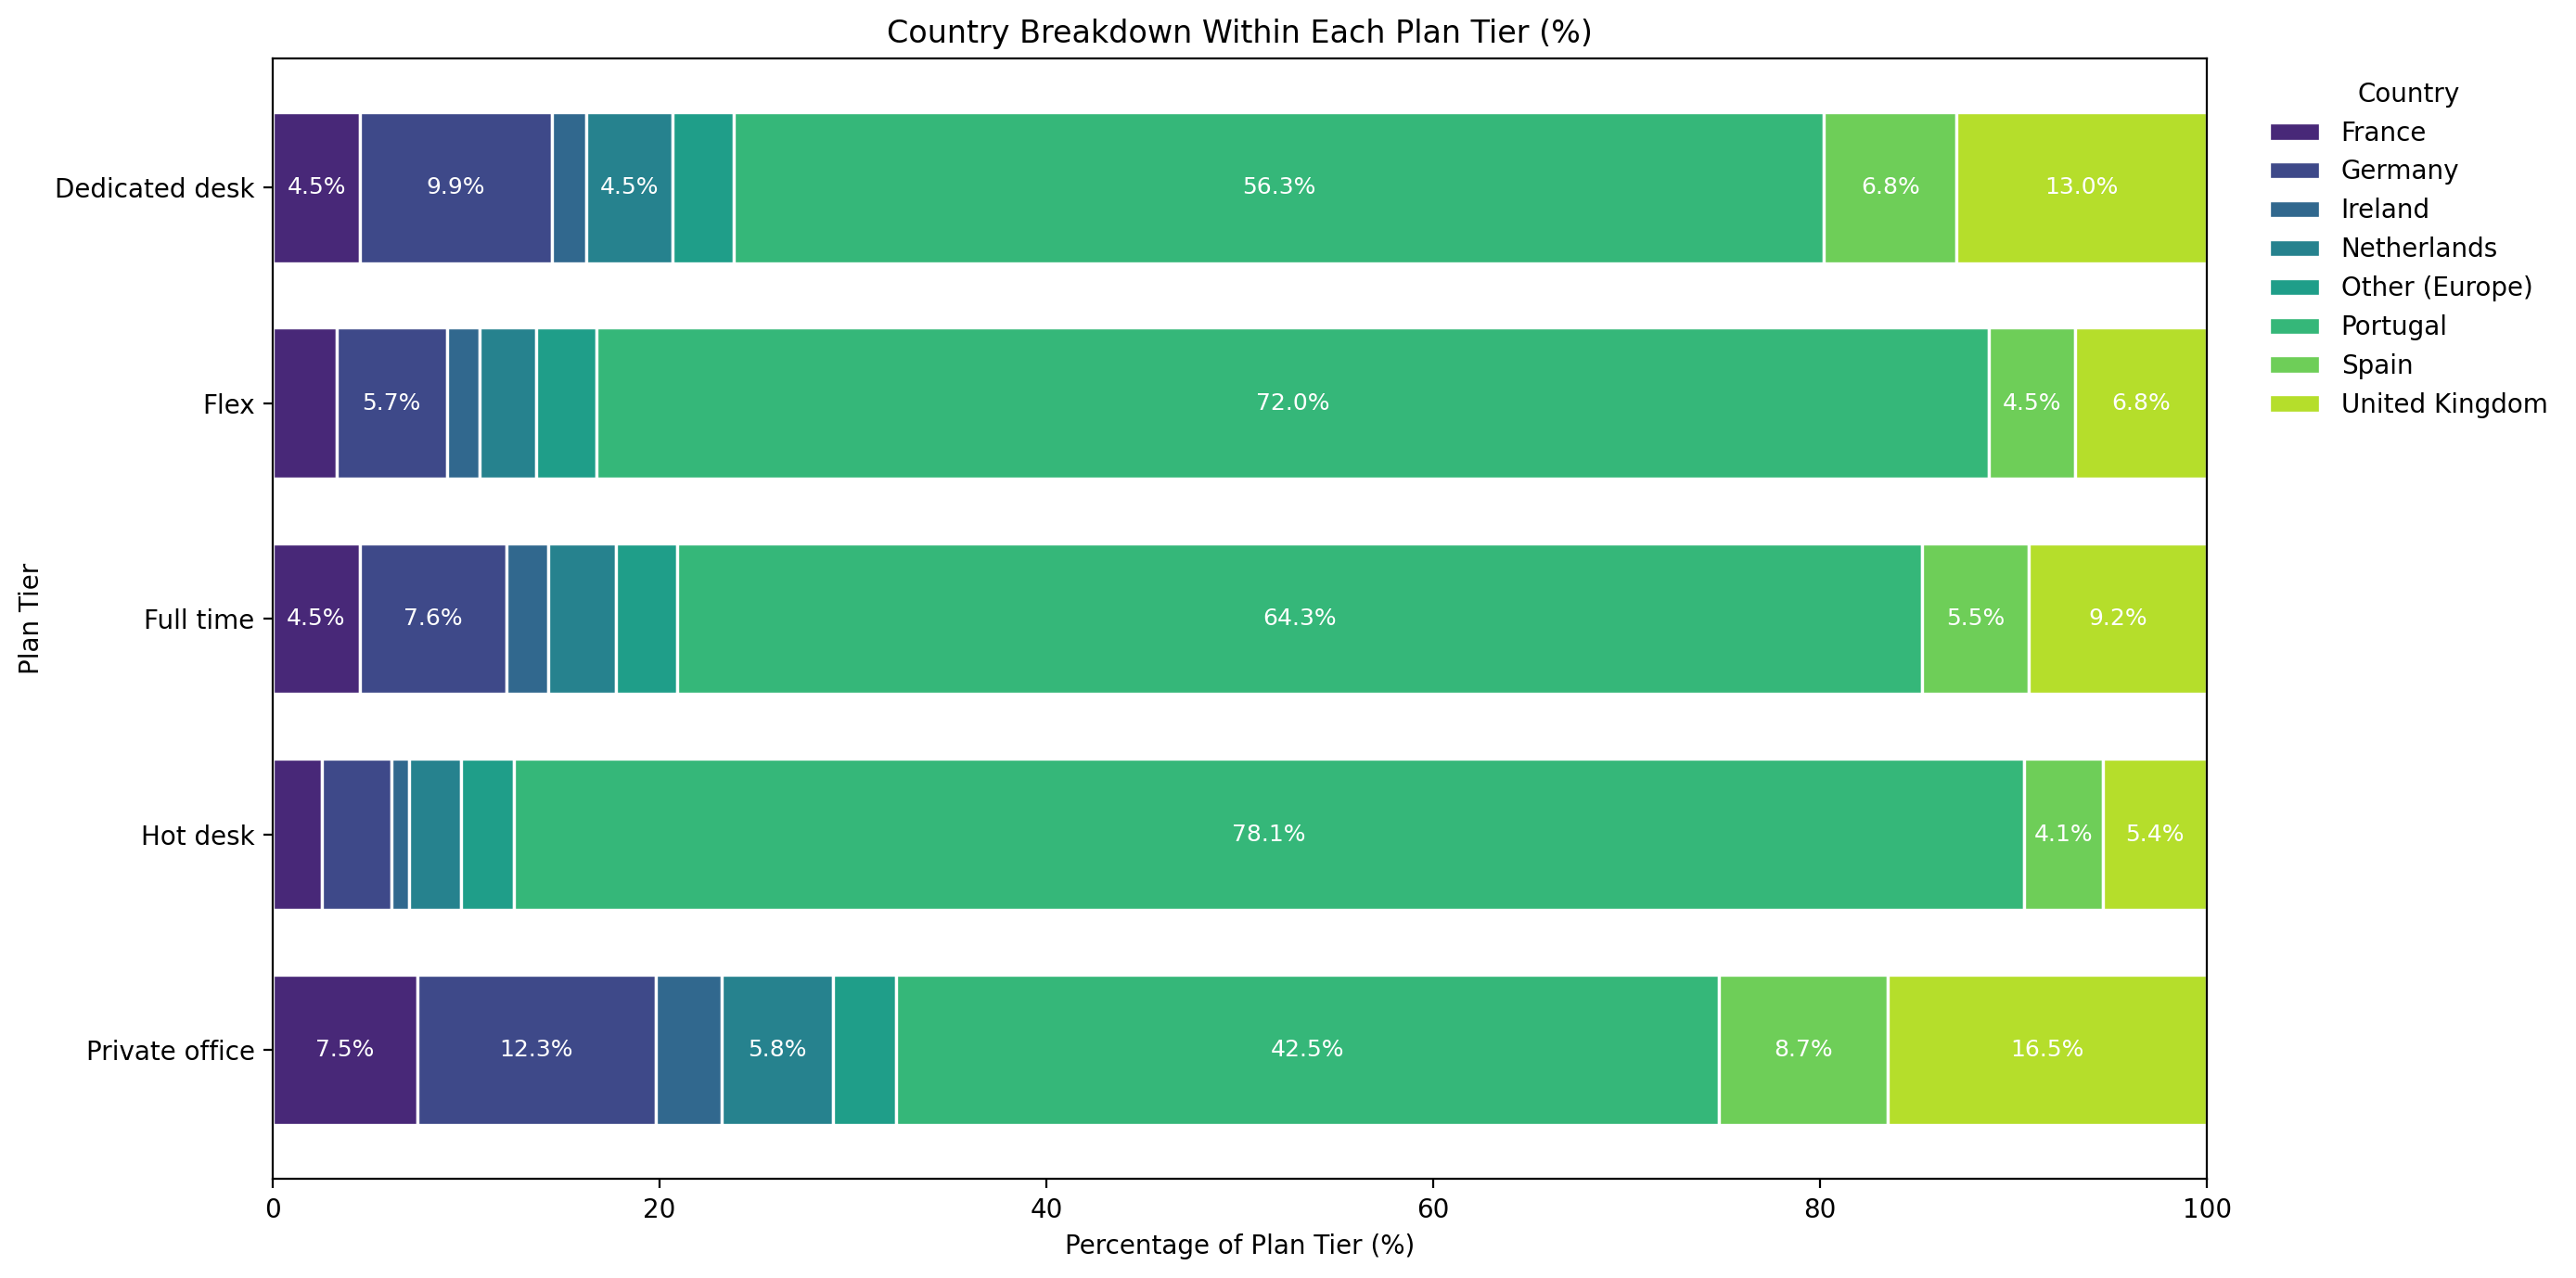

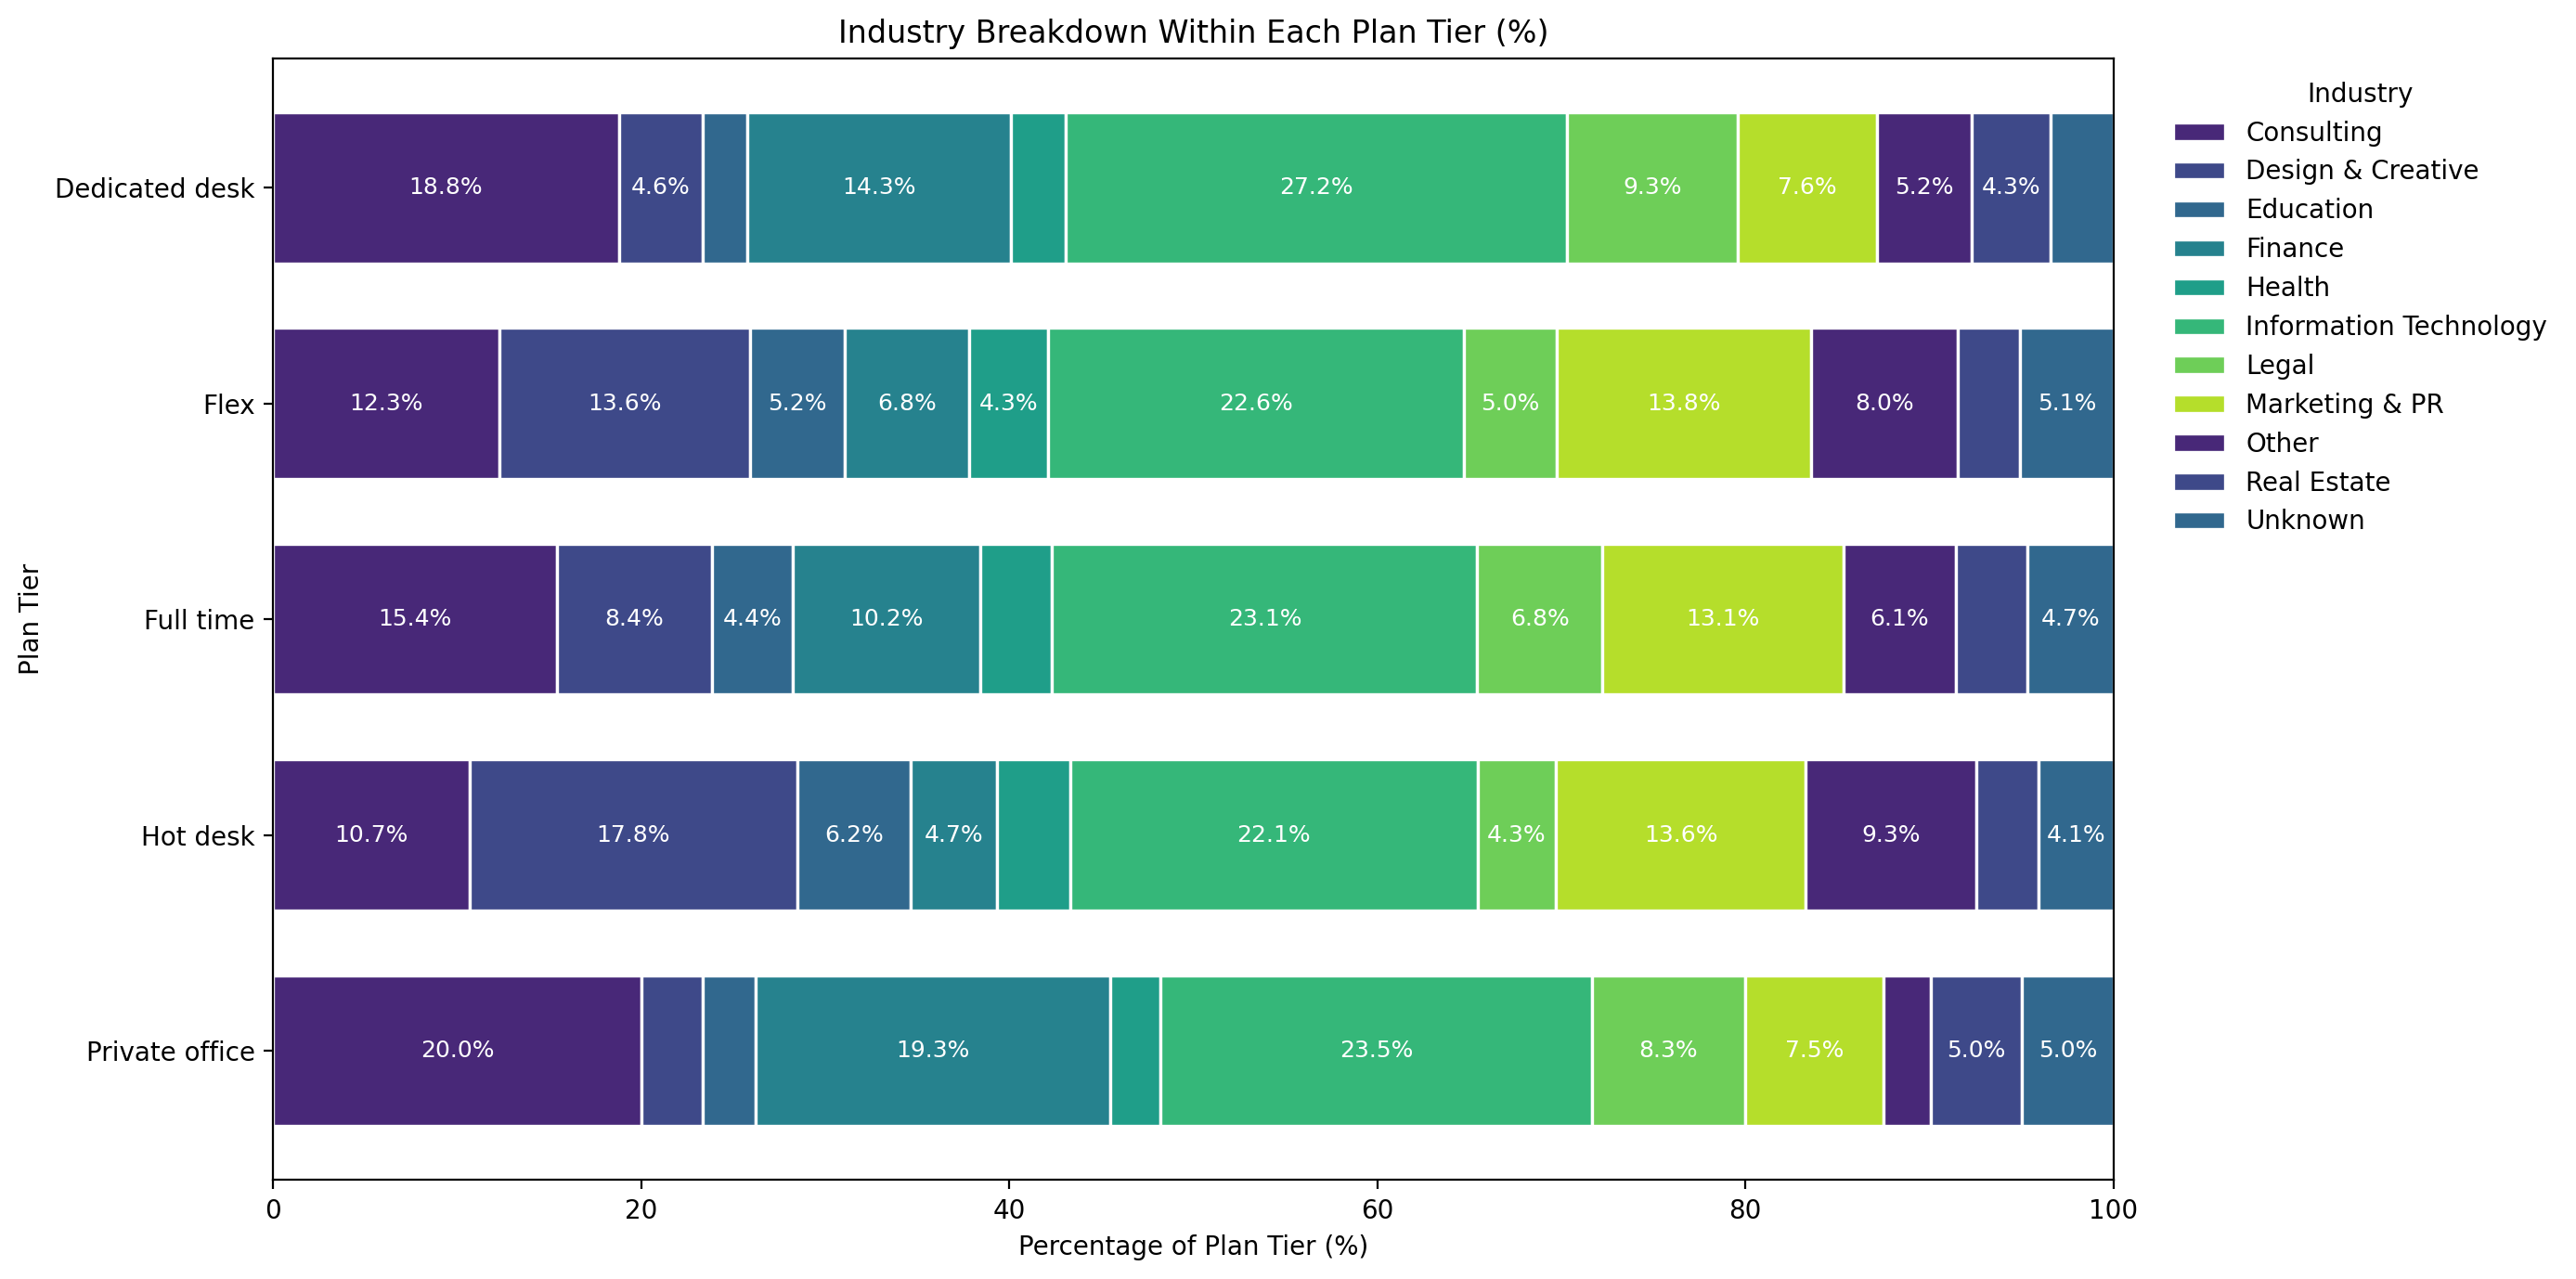

In [33]:
for category_label, category_column in [
    ("Country", "country_clean"),
    ("Industry", "industry_clean"),
]:
    category_order = sorted(cluster_eda[category_column].dropna().unique())
    category_palette = {
        category: PALETTE[index % len(PALETTE)]
        for index, category in enumerate(category_order)
    }
    plt.figure(figsize=(12, 6))
    sns.boxplot(
        data=cluster_eda,
        x=category_column,
        y="avg_weekly_visits",
        hue=category_column,
        order=category_order,
        hue_order=category_order,
        palette=category_palette,
        legend=False,
        showfliers=False,
    )
    plt.title(f"Distribution of Average Weekly Visits by {category_label}", fontsize=14, fontweight="bold")
    plt.xlabel(category_label, fontsize=11)
    plt.ylabel("Average Weekly Visits", fontsize=11)
    plt.xticks(rotation=45, ha="right")
    plt.tight_layout()
    plt.show()

for category_label, category_column in [
    ("Country", "country_clean"),
    ("Industry", "industry_clean"),
]:
    valid_data = cluster_eda.loc[
        cluster_eda[category_column].ne("Missing")
        & cluster_eda["plan_tier_clean"].ne("Missing / review")
    ]
    cross_tab = pd.crosstab(
        valid_data["plan_tier_clean"],
        valid_data[category_column],
        normalize="index",
    ).mul(100)
    palette = [PALETTE[index % len(PALETTE)] for index in range(cross_tab.shape[1])]
    ax = cross_tab.plot(
        kind="barh",
        stacked=True,
        figsize=(14, 7),
        color=palette,
        edgecolor="white",
        linewidth=1.2,
        width=0.7,
    )
    for container, color in zip(ax.containers, palette):
        labels = [f"{value:.1f}%" if value > 4 else "" for value in container.datavalues]
        ax.bar_label(container, labels=labels, label_type="center", fontsize=9, color="white")
    ax.set_title(f"{category_label} Breakdown Within Each Plan Tier (%)")
    ax.set_xlabel("Percentage of Plan Tier (%)")
    ax.set_ylabel("Plan Tier")
    ax.set_xlim(0, 100)
    ax.invert_yaxis()
    ax.legend(title=category_label, bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
    plt.tight_layout()
    plt.show()


**Interpretation:** The boxplots compare attendance distributions across categories. In the stacked bars, each plan tier is the denominator: they show how that plan's members are distributed across countries or industries. These comparisons are descriptive and do not establish that industry or country causes attendance patterns.


### 8.11 Clustering implication: avoid overweighting attendance

Section 6 already shows that average weekly visits and recent-period visits overlap strongly (Spearman rho about 0.93). Visit utilization also tracks attendance closely (rho about 0.84), so treat it as a plan-relative view of engagement rather than automatically adding it as an independent behavior. Compare clustering feature sets to check whether including utilization adds a useful distinction without overweighting engagement.


## 9. Implications for the clustering stage

**Behavioral dimensions to test:**

- **Engagement and recency:** average weekly visits and/or days since last visit. Recent-period visits overlap with weekly visits, so test whether both add value.
- **Plan-relative engagement:** visit utilization, interpreted alongside plan allowance. Keep undefined utilization distinct from zero use.
- **Service needs:** service breadth, selected individual indicators, or the mail-or-storage grouping. Compare these as alternative representations; including all of them could overweight service use.
- **Collaboration:** team status, colleagues, meeting-room use, or guest passes only after confirming the record-level definition and data quality.

**Usually better for profiling than initial behavior inputs:** age, gender, country, and industry. Plan tier depends on the business question: include it if membership choice is part of the segmentation; otherwise use it to describe the resulting groups. Renewals, total visits, and lifetime value are cumulative and should be interpreted with tenure; they may be better as profiling measures.

Before fitting a model, resolve duplicate/conflicting records, validate suspicious values, decide how to handle missingness and skew, standardize/scale inputs, and test the stability and interpretability of several cluster solutions. Compare alternative feature sets so that the result is not an artifact of redundant variables or data-cleaning choices.


## 10. Preliminary findings for stakeholders

These are **EDA findings and hypotheses, not discovered clusters**.

1. **Engagement is a likely differentiator.** Attendance and recency vary, but weekly visits and recent-period visits are strongly correlated (about 0.93); weekly visits and days since last visit are inversely correlated (about -0.66). Median weekly visits also vary across industry and country groups, although these comparisons are descriptive and may reflect plan mix. The model should avoid unintentionally overweighting attendance.
2. **Unexpected service-use pattern:** Members using mail handling or storage have higher median weekly attendance (1.95 vs. 1.25 visits) and median plan utilization (62% vs. 47%) than members using neither. These services may accompany, rather than replace, workspace use. The comparison is descriptive; check it across plan types before interpreting it as a distinct customer profile. More broadly, plan-relative use and service mix may add context: overall visit utilization averages about 52%, and optional services range from common meeting-room use to rare bike-locker use.
3. **Data limitations are material.** The source contains 15 exact duplicate rows, negative and implausible values, missing fields, inconsistent labels, and a likely LTV unit issue. The LTV cents adjustment is heuristic, and the badge-swipe timeline extends past the assumed 2024-01-01 snapshot. Validate these issues before modeling.
4. **Working segment hypothesis.** Test whether the data support profiles such as frequent/high-utilization members, low-activity or less-recent members, and members with broader or collaboration-oriented service use. These are hypotheses to validate, not known customer groups.
5. **Working cluster-count hypothesis.** Evaluate candidate counts such as *k* = 2 through 6; roughly 3-4 interpretable profiles are a starting expectation only. The final choice should depend on stability, separation, distinct behavioral profiles, and business usefulness, not EDA alone or a single score.

**Plain-language explanation:** We are checking whether members differ in how often they visit, how much of their plan they use, and which extra services they choose. Early patterns suggest attendance is important, while service mix and plan-relative use may provide additional context. We will test a range of possible groupings and only recommend profiles that are stable and understandable. Data quality and overlapping measures are the main challenges.

For the final clustering report, show cluster sizes and a few distinctive behavioral measures, describe each group in plain language, and state uncertainty and data limitations. Use demographic attributes carefully to describe and check groups, not to imply that demographics cause behavior.
